# Parte 1 - Gobernanza y Calidad de datos

## 1. Describir brevemente el origen y caracteristicas del dataset


### Origen

El conjunto de datos corresponde al dataset de producción de pozos de petróleo provisto por la cátedra (archivo `ds_ypf_2026.csv`), utilizado como **Opción A** del Proyecto Integrador. Su diccionario de datos organiza las variables en categorías de ingeniería: identificatoria, profundidad, diseño de estimulación, volumen de producción, tiempo de producción, productividad, geomecánica y geología, geología estática y forma de producir.

### Estructura

| Concepto | Valor |
|---|---|
| Filas en el archivo original | 998 |
| Columnas en el archivo original | 26 |
| Columnas sin nombre (eliminadas) | 10 |
| Filas vacías (eliminadas) | 772 |
| **Filas Finales** | **226** |
| **Variables Finales** | **16** |

El conjunto de trabajo contiene **15 variables numéricas continuas** y **1 variable categórica** (`zona`).

### Grupos de variables

| Categoría | Variables |
|---|---|
| Identificatoria | `zona` |
| Profundidad | `tvd_landing` |
| Diseño de estimulación | `ef_L_m`, `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `p50_i_prefrac_whp_psi` |
| Volumen de producción | `210d_kbbl` |
| Tiempo de producción | `dias_efectivos` |
| Productividad | `frac_y_pem_dias`, `cumgor180_days_m3m3` |
| Geomecánica / geología | `ai_jifi_` |
| Geología estática | `ild_avg`, `Sat`, `omphi_` |
| Forma de producir | `dd_50d` |


## 2. Indentifica y discuti posibles problemas de calidad de datos, tales como:

    a. Inconsistencias entre columnas

    b. Valores nulos, duplicados o extremos

    c. Formatos no estandarizados

### 2.1 - Analisis del dataset

In [ ]:

# Librerías estándar
import math
import re

# Manipulación de datos y cálculo numérico
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy import stats
from scipy.stats import pearsonr, spearmanr

# scikit-learn: preprocesamiento
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler

# scikit-learn: modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
)

# scikit-learn: partición, validación y pipelines
from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline

# scikit-learn: métricas
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

# Configuración de visualización
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

In [2]:
# Carga del dataset
RUTA = "ds_ypf_2026.csv"
df = pd.read_csv(RUTA, delimiter=";")
df.head()

,zona,tvd_landing,ef_L_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,Sat,omphi_,dd_50d,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,Zona B,3114.79,1860.0,0.748826,0.519440,0.0,6206.5,155.521252,1145.0,47.177778,121.7,7072.657427,144.510823,0.176144,0.073696,0.830962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Zona A,3124.09,2460.0,0.740660,0.498118,0.0,6214.0,254.031469,1115.0,43.773611,121.6,7062.238177,105.029498,0.206746,0.066866,0.843503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Zona D,3056.85,2368.0,0.787669,0.519240,0.0,5880.0,178.063669,861.0,54.831250,240.8,7251.706503,56.148262,0.315294,0.074453,0.911041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Zona A,3053.59,1792.0,0.750438,0.143228,0.0,5625.0,139.927722,859.0,57.170139,199.3,7362.269218,109.137477,0.242902,0.081679,0.853775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Zona B,2989.65,2439.6,1.000000,0.360000,0.0,5994.0,196.827550,914.0,41.475000,162.2,7390.584428,103.160630,0.201982,0.095174,0.836422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 998 entries, 0 to 997
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   zona                   226 non-null    str    
 1   tvd_landing            226 non-null    float64
 2   ef_L_m                 226 non-null    float64
 3   m_100_frac             226 non-null    float64
 4   vol_swater_frac        226 non-null    float64
 5   vol_xlink_frac         226 non-null    float64
 6   p50_i_prefrac_whp_psi  226 non-null    float64
 7   210d_kbbl              226 non-null    float64
 8   dias_efectivos         226 non-null    float64
 9   frac_y_pem_dias        226 non-null    float64
 10  cumgor180_days_m3m3    226 non-null    float64
 11  ai_jifi_               226 non-null    float64
 12  ild_avg                226 non-null    float64
 13  Sat                    226 non-null    float64
 14  omphi_                 226 non-null    float64
 15  dd_50d           

In [4]:
#Nombres de originales de las columnas, hago esto para normalizar despues
print("Nombres originales de las columnas:")
print(df.columns.tolist())

Nombres originales de las columnas:
['zona', 'tvd_landing', 'ef_L_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'Sat', 'omphi_', 'dd_50d', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


In [5]:
#Como buena practica, decido normalizar los nombres de las columnas, quitando espacios, convirtiendo a minusculas y reemplazando espacios y guiones por guion bajo
def normalizar_nombre(columna):
    nombre = columna.strip().lower()
    nombre = re.sub(r"[ /\-]+", "_", nombre)
    return nombre


df.columns = [normalizar_nombre(c) for c in df.columns]
print("Nombres normalizados:")
print(df.columns.tolist())

Nombres normalizados:
['zona', 'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', 'dd_50d', 'unnamed:_16', 'unnamed:_17', 'unnamed:_18', 'unnamed:_19', 'unnamed:_20', 'unnamed:_21', 'unnamed:_22', 'unnamed:_23', 'unnamed:_24', 'unnamed:_25']


In [6]:
# Hay columnas quee se me crearon que saleen como unnamed, las elimino
columnas_sin_nombre = [c for c in df.columns if c.startswith('unnamed')]
df = df.drop(columns=columnas_sin_nombre)
print("Columnas eliminadas:", len(columnas_sin_nombre))

Columnas eliminadas: 10


### 2.2 - Valores nulos y faltantes

In [7]:
#Veo la cantidad de valores nulos por columna
faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["cantidad"] > 0].sort_values("porcentaje", ascending=False)
faltantes

,cantidad,porcentaje
zona,772,77.35
tvd_landing,772,77.35
ef_l_m,772,77.35
m_100_frac,772,77.35
vol_swater_frac,772,77.35
vol_xlink_frac,772,77.35
p50_i_prefrac_whp_psi,772,77.35
210d_kbbl,772,77.35
dias_efectivos,772,77.35
frac_y_pem_dias,772,77.35


Las 16 variables tienen exactamente 772 valores faltantes (77,35 %). Como la cantidad y el porcentaje son idénticos en todas las columnas, los faltantes no están dispersos: corresponden a las mismas 772 filas, que no contienen ningún dato. Por eso se eliminan en la celda siguiente.

In [8]:
#Confirmo lo que mencione arriba
df.tail(10)

,zona,tvd_landing,ef_l_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,sat,omphi_,dd_50d
988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
993,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
#Elimino las filas Nan
df = df.dropna(axis=0, how='all')

#Hago un reset index para que el index vuelva a ser correlativo
df.reset_index(drop=True, inplace=True)

#Veo filas y columnas del dataset
df.shape

(226, 16)

In [10]:
#Verifico si hay algun valor nulo en el dataset
df.isnull().sum()

zona                     0
tvd_landing              0
ef_l_m                   0
m_100_frac               0
vol_swater_frac          0
vol_xlink_frac           0
p50_i_prefrac_whp_psi    0
210d_kbbl                0
dias_efectivos           0
frac_y_pem_dias          0
cumgor180_days_m3m3      0
ai_jifi_                 0
ild_avg                  0
sat                      0
omphi_                   0
dd_50d                   0
dtype: int64

In [11]:
#Describe de los elementos para conocer sus valores estadisticos y ver si hay algun valor que me llama la atencion
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tvd_landing,226.0,3085.735885,73.550337,2934.600000,3027.237500,3083.475000,3132.257500,3250.320000
ef_l_m,226.0,1759.787696,566.585128,298.800000,1322.512500,1739.687500,2252.531250,3328.000000
m_100_frac,226.0,0.371677,0.312043,0.062100,0.136300,0.186150,0.748304,1.000002
vol_swater_frac,226.0,0.413099,0.186202,0.000000,0.272871,0.427009,0.482266,0.999219
vol_xlink_frac,226.0,0.284571,0.261738,0.000000,0.000195,0.204569,0.580064,0.889765
p50_i_prefrac_whp_psi,226.0,6094.205752,240.052690,5432.000000,5941.500000,6101.500000,6240.750000,6782.000000
210d_kbbl,226.0,127.487714,63.264054,31.727292,76.661211,102.565083,172.903248,303.812580
dias_efectivos,226.0,1754.358407,604.786486,382.000000,1317.250000,1793.500000,2205.500000,2926.000000
frac_y_pem_dias,226.0,33.909999,24.427098,4.000000,16.000000,26.235417,47.133333,168.000000
cumgor180_days_m3m3,226.0,158.796903,45.469661,54.400000,129.325000,151.200000,181.625000,349.600000


### 2.3 - Valores duplicados

Lo que busco ver aca es si hay mas de un valor en cada columnas. Aquellas columnas que posean 1 o 2 valores podemos eliminarlas o ver como las trabajamos ya que es posible que mucha informacion no nos aporte al modelo

In [12]:
# 1) Duplicados: filas idénticas en las 16 variables
print("Filas duplicadas:", df.duplicated().sum())

# 2) Cardinalidad: cantidad de valores distintos por columna.
#    Sirve para detectar variables constantes o con poca variación.
print("\nValores distintos por columna:")
print(df.nunique().sort_values())

Filas duplicadas: 0

Valores distintos por columna:
zona                       4
frac_y_pem_dias          119
vol_xlink_frac           170
p50_i_prefrac_whp_psi    192
m_100_frac               196
ef_l_m                   208
cumgor180_days_m3m3      211
dias_efectivos           215
tvd_landing              224
dd_50d                   225
210d_kbbl                226
vol_swater_frac          226
ai_jifi_                 226
ild_avg                  226
sat                      226
omphi_                   226
dtype: int64


### 2.4 - Analisis de variables categoricas

Zona es la unica variable categorica que tenemos, por ende es la unica que vamos a encodear. Para ellos me gustaria ver primero que valores posee.

In [13]:
df.dtypes

zona                         str
tvd_landing              float64
ef_l_m                   float64
m_100_frac               float64
vol_swater_frac          float64
vol_xlink_frac           float64
p50_i_prefrac_whp_psi    float64
210d_kbbl                float64
dias_efectivos           float64
frac_y_pem_dias          float64
cumgor180_days_m3m3      float64
ai_jifi_                 float64
ild_avg                  float64
sat                      float64
omphi_                   float64
dd_50d                   float64
dtype: object

In [14]:
#Solo zona es del tipo categorica, verifico los valores unicos que tiene para ver si es necesario hacer algun tipo de limpieza
df['zona'].unique()
#Determino que no es necesario hacer una limpieza ya que los valores son correctos y no hay errores de tipeo

<ArrowStringArray>
['Zona B', 'Zona A', 'Zona D', 'Zona C']
Length: 4, dtype: str

In [15]:
# Valores únicos de la variable categórica 'zona'
# Verifico que sean exactamente 4 zonas escritas de forma uniforme
print(df['zona'].value_counts())

zona
Zona B    106
Zona A     86
Zona D     22
Zona C     12
Name: count, dtype: int64


### 2.5 - Outliers


Para el analisis de outliers voy a evaluarlo meidante el rango intercuartilico ya que desconozco la distribucion. Si tienen una distribucion normal, es posible el uso de z-core, sin embargo al haber usado un describe de los elementos anterioremente puedo intuir que las variables no son perfectamente simetricas

Este supuesto lo comprobaré en secciones posteriores

In [16]:
# Calculo Q1, Q3 y rango intercuartilico (RIC) para cada variable numerica
columnas_numericas = df.select_dtypes(include=np.number).columns
columnas_numericas = [col for col in columnas_numericas if not col.lower().startswith('zona_')]
q1 = df[columnas_numericas].quantile(0.25)
q3 = df[columnas_numericas].quantile(0.75)
ric = q3 - q1

def contar_outliers(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    ric = q3 - q1
    limite_inf = q1 - 1.5 * ric
    limite_sup = q3 + 1.5 * ric
    return ((serie < limite_inf) | (serie > limite_sup)).sum() #Hay outliers tanto por arriba como por abajo, por eso uso el operador | (or) para contar ambos casos


outliers = pd.Series({
    col: contar_outliers(df[col])
    for col in columnas_numericas
})

outliers = outliers[outliers > 1].sort_values(ascending=False)

print("Variables con más de 1 outlier, ordenadas de mayor a menor:")
print(outliers)

Variables con más de 1 outlier, ordenadas de mayor a menor:
dd_50d                   14
vol_swater_frac          12
cumgor180_days_m3m3       7
frac_y_pem_dias           4
p50_i_prefrac_whp_psi     4
dtype: int64


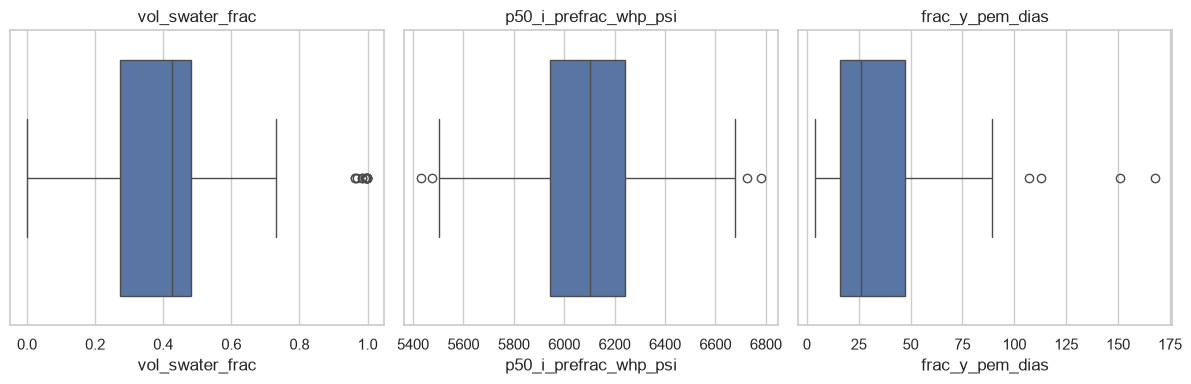

In [17]:
columnas = ['vol_swater_frac', 'p50_i_prefrac_whp_psi', 'frac_y_pem_dias']
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, columnas):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

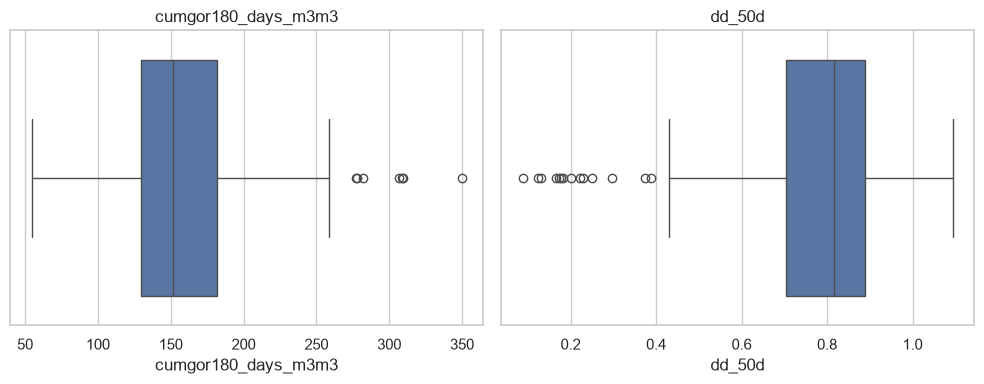

In [18]:

columnas2 = ['cumgor180_days_m3m3', 'dd_50d']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, columnas2):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

#### Cantidad de datos Outliers
| Variable | Atípicos | Ubicación | Observación |
|---|---|---|---|
| `vol_swater_frac` | 12 | Cola superior | Pozos con casi solo slickwater. Son el grupo analizado en el EDA. |
| `dd_50d` | 14 | Cola inferior | Variable excluida del modelo por ser posterior a la producción. |
| `cumgor180_days_m3m3` | 7 | Cola superior | Variable excluida del modelo por ser posterior a la producción. |
| `frac_y_pem_dias` | 4 | Cola superior | Variable excluida del modelo por ser posterior a la producción. |
| `p50_i_prefrac_whp_psi` | 4 | Ambas colas | Presiones previas a la fractura. |

En total hay 41 valores atípicos en 5 variables. Un mismo pozo puede aparecer en más de una variable.

----

#### Decisión final:
Estos valores se conservan, al ser un dataset real es posible que determinados valores atipicos sean productos de desiciones o tener causas operativas que lo justifiquen. Eliminarlos reduciría la información de los pozos de mayor producción, que es justamente el fenómeno que se quiere estudiar.

De ser posible es recomendable tener un experto de dominio del tema en cuestion en el equipo el cual pueda orientarnos sobre estos valores.


### 2.6 - Encoding

In [19]:
# One-Hot Encoding de la variable categórica 'zona'
# drop='first' usa Zona A como categoría de referencia
oh_encoder = OneHotEncoder(drop='first', sparse_output=False)
zona_codificada = oh_encoder.fit_transform(df[['zona']])

# Nombres de las columnas en minúscula: zona_b, zona_c, zona_d
# categories_[0] contiene ['Zona A', 'Zona B', 'Zona C', 'Zona D']; [1:] omite la referencia
nombres_zona = [f"zona_{cat.split()[-1].lower()}" for cat in oh_encoder.categories_[0][1:]]

# Reemplazo 'zona' por sus columnas binarias
zonas_dummies = pd.DataFrame(zona_codificada, columns=nombres_zona, index=df.index).astype(int)
df = pd.concat([df.drop(columns='zona'), zonas_dummies], axis=1)

print(df.columns.tolist())
print(df[nombres_zona].sum())

['tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', 'dd_50d', 'zona_b', 'zona_c', 'zona_d']
zona_b    106
zona_c     12
zona_d     22
dtype: int64


In [ ]:
#Verifico el encodeado
df.head(3)

,tvd_landing,ef_l_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,sat,omphi_,dd_50d,zona_b,zona_c,zona_d
0,3114.79,1860.0,0.748826,0.519440,0.0,6206.5,155.521252,1145.0,47.177778,121.7,7072.657427,144.510823,0.176144,0.073696,0.830962,1,0,0
1,3124.09,2460.0,0.740660,0.498118,0.0,6214.0,254.031469,1115.0,43.773611,121.6,7062.238177,105.029498,0.206746,0.066866,0.843503,0,0,0
2,3056.85,2368.0,0.787669,0.519240,0.0,5880.0,178.063669,861.0,54.831250,240.8,7251.706503,56.148262,0.315294,0.074453,0.911041,0,0,1



Se utilizó **One-Hot Encoding** con `OneHotEncoder` de scikit-learn.

#### Funcionamiento

Cada categoría se transforma en una columna binaria, con valor 1 si el pozo pertenece a esa zona y 0 en caso contrario. Con `drop='first'` se elimina una categoría como referencia. Se tomó `Zona A`, la primera en orden alfabético, por lo que las columnas resultantes son:

| Zona | `zona_b` | `zona_c` | `zona_d` |
|---|:---:|:---:|:---:|
| Zona A (referencia) | 0 | 0 | 0 |
| Zona B | 1 | 0 | 0 |
| Zona C | 0 | 1 | 0 |
| Zona D | 0 | 0 | 1 |


----
#### Por qué One-Hot Encoding

Se evaluaron cuatro alternativas:

- **`pd.get_dummies`:** produce la misma codificación para los datos disponibles, pero no aprende las categorías del entrenamiento. Cada lote genera sus propias columnas, por lo que la codificación de datos futuros puede no coincidir con la del modelo sin que el código lo advierta.
- **Label Encoding:** asigna un entero a cada zona (0, 1, 2, 3). Esto introduce un orden y una distancia que no existen: un modelo lineal interpretaría `Zona D` como "tres veces" `Zona B`. Está pensado para etiquetas de la variable objetivo, no para predictores nominales.
- **Binning (discretización):** agrupa valores numéricos en intervalos. No aplica a `zona`, que ya es categórica, y crear agrupaciones artificiales implicaría perder información.
- **One-Hot Encoding con `OneHotEncoder`:** representa cada zona sin imponer orden, y aprende las categorías durante el ajuste. Esto permite aplicar la misma codificación a datos nuevos, algo que el proyecto necesita para predicciones futuras.

----

#### Consideraciones

`OneHotEncoder` usa `handle_unknown='error'` por defecto: si aparece una zona que no estaba en el entrenamiento, la codificación se detiene con un error en lugar de asignar valores de forma silenciosa.

El encoder se ajusta sobre el conjunto de datos disponible. En la sección de modelado, la codificación se integrará en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada fold.


### 2.7 - Inconsistencia entre columnas y Formatos No estandarizados


Para este analisis voy a trabajar con las columnas "vol_swater_frac" y "vol_xlink_frac"

Los pozos que no tengan swater deben tener crosslinker o viceversa. Esto es por una razon de ingenieria a la hora de realizar una estimulacion hidraulica por lo que necesito hacer este cruce para ver si existe alguna inconsistencia respecto a estoy ver si los datos son correctos

In [21]:
cols_fluidos = ['vol_swater_frac', 'vol_xlink_frac']

# 1) Nulos: se cuentan antes de cualquier relleno
print("Nulos:\n", df[cols_fluidos].isna().sum())

# 2) Negativos: un volumen no puede ser menor que cero
print("Negativos:\n", (df[cols_fluidos] < 0).sum())

# 3) Presencia de cada fluido (volumen mayor que cero).
# Nota: NaN > 0 da False, por eso el paso 1 es necesario para interpretar esta columna
swater_usado = df['vol_swater_frac'] > 0
xlink_usado = df['vol_xlink_frac'] > 0

# 4) Tabla de combinaciones
print(pd.crosstab(swater_usado, xlink_usado,
                  rownames=['swater'], colnames=['xlink']))

# 5) Pozos sin ningún fluido (incumple la regla "al menos uno")
print("Pozos sin ningún fluido:", (~swater_usado & ~xlink_usado).sum())

# 6) Pozos con ambos fluidos (candidatos a revisar según el diccionario)
print("Pozos con ambos fluidos:", (swater_usado & xlink_usado).sum())

Nulos:
 vol_swater_frac    0
vol_xlink_frac     0
dtype: int64
Negativos:
 vol_swater_frac    0
vol_xlink_frac     0
dtype: int64
xlink   False  True 
swater              
False       0      1
True       57    168
Pozos sin ningún fluido: 0
Pozos con ambos fluidos: 168


In [22]:
# Suma de ambas proporciones por pozo
suma_fluidos = df['vol_swater_frac'] + df['vol_xlink_frac']

print("Suma mínima:", suma_fluidos.min())
print("Suma máxima:", suma_fluidos.max())

# Referencia: valores máximos individuales, para comparar escala
print(df[['vol_swater_frac', 'vol_xlink_frac']].max())

Suma mínima: 0.06
Suma máxima: 1.0
vol_swater_frac    0.999219
vol_xlink_frac     0.889765
dtype: float64


Se analizó la relación entre `vol_swater_frac` (slickwater) y `vol_xlink_frac` (crosslinker), considerando que un fluido está presente cuando su fracción es mayor que cero.

Ninguna de las dos columnas tiene valores nulos ni negativos. Todos los pozos utilizan al menos uno de los dos fluidos, por lo que la regla de presencia mínima se cumple en los 226 registros. Se identificaron 168 pozos con ambos fluidos, 57 con solo slickwater y 1 con solo crosslinker.


In [23]:
# Verificación de formatos y rangos según las reglas de gobernanza

# 1) Fracciones: deben estar en [0, 1], con tolerancia de 1e-4 por redondeo
fracciones = ['m_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'sat', 'omphi_']
TOL = 1e-4

resumen_fracciones = pd.DataFrame({
    'minimo': df[fracciones].min(),
    'maximo': df[fracciones].max(),
    'fuera_de_rango': [
        int(((df[c] < -TOL) | (df[c] > 1 + TOL)).sum()) for c in fracciones
    ],
}).round(6)
print("Fracciones (rango esperado [0, 1]):")
print(resumen_fracciones.to_string())

# 2) Variables que deben ser estrictamente positivas
positivas = ['tvd_landing', 'ef_l_m', 'p50_i_prefrac_whp_psi', '210d_kbbl',
             'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3',
             'ai_jifi_', 'ild_avg']
no_positivos = {c: int((df[c] <= 0).sum()) for c in positivas}
print("\nValores no positivos por variable (esperado: 0):")
print(pd.Series(no_positivos).to_string())

# 3) dd_50d: rango observado frente al límite propuesto en la gobernanza
print("\ndd_50d: rango observado")
print(f"minimo = {df['dd_50d'].min():.3f} | maximo = {df['dd_50d'].max():.3f}")
print(f"registros por encima de 1: {int((df['dd_50d'] > 1).sum())}")

# 4) Separador decimal: los valores deben ser float (no texto)
print("\nTipos de las variables numéricas:")
print(df.select_dtypes(include='number').dtypes.value_counts().to_string())

Fracciones (rango esperado [0, 1]):
                   minimo    maximo  fuera_de_rango
m_100_frac       0.062100  1.000002               0
vol_swater_frac  0.000000  0.999219               0
vol_xlink_frac   0.000000  0.889765               0
sat              0.161101  0.570928               0
omphi_           0.037664  0.101729               0

Valores no positivos por variable (esperado: 0):
tvd_landing              0
ef_l_m                   0
p50_i_prefrac_whp_psi    0
210d_kbbl                0
dias_efectivos           0
frac_y_pem_dias          0
cumgor180_days_m3m3      0
ai_jifi_                 0
ild_avg                  0

dd_50d: rango observado
minimo = 0.087 | maximo = 1.093
registros por encima de 1: 4

Tipos de las variables numéricas:
float64    15
int64       3


In [24]:
# Vista general: mínimo y máximo de todas las variables
df.describe().T[['min', 'max']]

,min,max
tvd_landing,2934.600000,3250.320000
ef_l_m,298.800000,3328.000000
m_100_frac,0.062100,1.000002
vol_swater_frac,0.000000,0.999219
vol_xlink_frac,0.000000,0.889765
p50_i_prefrac_whp_psi,5432.000000,6782.000000
210d_kbbl,31.727292,303.812580
dias_efectivos,382.000000,2926.000000
frac_y_pem_dias,4.000000,168.000000
cumgor180_days_m3m3,54.400000,349.600000



Para verificar que las variables estén en el formato y el rango esperados se usaron dos métodos complementarios.

#### Revisión visual

Como el diccionario de datos documenta la unidad y el significado de cada variable, es posible establecer de antemano el rango que puede tomar cada una. Con `df.describe().T` se comparan los mínimos y máximos observados contra ese rango. Esta revisión es rápida y permite detectar a simple vista errores de escala, como fracciones cargadas en porcentaje (máximos cercanos a 100) o valores negativos donde no corresponden.

----

#### Revisión por reglas

Para no depender solo de la inspección visual, se implementaron reglas específicas en código que informan automáticamente cuántos valores quedan fuera de rango:

- **Fracciones:** `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `sat` y `omphi_` deben estar en [0, 1], con una tolerancia de 10⁻⁴ por errores de redondeo.
- **Variables positivas:** `tvd_landing`, `ef_l_m`, `p50_i_prefrac_whp_psi`, `210d_kbbl`, `dias_efectivos`, `frac_y_pem_dias`, `cumgor180_days_m3m3`, `ai_jifi_` e `ild_avg` deben ser estrictamente mayores que cero.
- **`dd_50d`:** se compara el rango observado con el límite superior propuesto en la gobernanza (1).

Ambas revisiones se realizaron sobre los 226 pozos del conjunto de trabajo.


## 3. Criterios de Gobernanza de datos


Si este análisis formara parte de un proceso industrial real, sería necesario establecer un marco de gobernanza de datos que garantice la confiabilidad de los modelos predictivos. Se proponen las siguientes políticas y reglas.

**1. Responsabilidad de los datos (*Data Stewardship*).** Las disciplinas operativas (Ingeniería de Reservorios, Perforación y Completación) asumen el rol de *Data Owners*: definen el significado de cada variable y validan su calidad desde el origen. Los cambios en el dataset son aprobados por el *Data Owner* correspondiente en un plazo máximo de 5 días hábiles.

**2. Trazabilidad y linaje de datos.** Un diccionario de metadatos documenta, para cada variable, su unidad, el sistema de origen, la etapa operativa, el responsable y las fechas de medición y de procesamiento. La unidad de las fracciones (fracción o porcentaje) y el método de medición de cada variable deben confirmarse con el área fuente. Por ejemplo, debe confirmarse si `p50_i_prefrac_whp_psi` proviene de sensores en boca de pozo.

**3. Identificador del pozo y disponibilidad temporal.** Cada registro debe tener un identificador único de pozo, asignado por el sistema de origen y conservado en todas las versiones del dataset. Esto permite evitar que un mismo pozo aparezca en distintos *folds*. Además, cada variable debe tener registrada la fecha a partir de la cual está disponible, y un predictor solo se utiliza si está disponible antes del momento de la predicción. Variables como `dias_efectivos`, `cumgor180_days_m3m3`, `dd_50d` y `frac_y_pem_dias` se miden durante la producción y deben revisarse con este criterio.

**4. Control de versiones y seguridad.** Se mantiene un sistema de control de versiones sobre los datasets curados. Cualquier limpieza, imputación o eliminación genera una nueva versión documentada, y los datos crudos originales se conservan sin modificaciones. Se establecen políticas de acceso basadas en roles para proteger los datos sensibles de producción e inversión.

**5. Validación automática (reglas de calidad).** Los controles se ejecutan en el sistema de ingesta, antes de incorporar cada carga al dataset de trabajo. Las reglas concretas son:

* **Estructura del archivo:** las columnas sin nombre y las filas completamente vacías se eliminan en la ingesta, y la cantidad eliminada se registra en el log de carga. En el dataset analizado eran 10 columnas y 772 filas.
* **Zona:** valores categóricos estandarizados con formato "Zona X" (A, B, C, D), sin variantes tipográficas. Una zona nueva no se incorpora automáticamente: requiere validación del responsable antes de reentrenar el modelo.
* **Formato numérico:** `tvd_landing` y `ef_l_m` (nombrada `ef_L_m` en el diccionario) deben ser numéricas, estrictamente positivas y con el punto decimal como único separador.
* **Fracciones:** `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `sat` (`Sat` en el diccionario) y `omphi_` deben estar en el rango [0, 1], con una tolerancia de 10⁻⁴ por errores de redondeo. Los valores fuera de ese rango se reportan. En el dataset analizado todas cumplen la regla, y el máximo de `m_100_frac` (1,000002) está dentro de la tolerancia.
* **Presencia de fluidos:** al menos uno de los dos volúmenes (`vol_swater_frac`, `vol_xlink_frac`) debe ser mayor que cero. Los pozos con ambos fluidos se documentan como hallazgo a validar con el área técnica, sin tratarlos como error de carga. Lo mismo aplica a los pozos con un solo fluido.
* **Presiones:** `p50_i_prefrac_whp_psi` debe ser positiva. El responsable técnico define un rango de referencia para la formación a partir de datos históricos, y los valores fuera de ese rango se reportan para revisión.
* **Producción y tiempos:** `210d_kbbl` (en miles de barriles), `cumgor180_days_m3m3`, `dias_efectivos` y `frac_y_pem_dias` deben ser estrictamente positivas.
* **Otras variables:** `ai_jifi_` (adimensional) e `ild_avg` (ohm·m) deben ser positivas. Para `dd_50d`, el diccionario indica "Días / índice". El rango observado va de 0,087 a 1,093, y 4 registros superan el límite de referencia de 1. Estos casos se revisan con el responsable técnico antes de fijar el límite definitivo.

**6. Tratamiento de valores atípicos.** Los valores atípicos identificados con el criterio IQR se conservan y se marcan en el dataset, sin eliminarlos. Su validación queda a cargo del *Data Owner*. Eliminarlos solo puede hacerse con una justificación técnica documentada en una nueva versión del dataset.

# Parte 2 - Metodologia y Analisis exploratorio

## 4. Variable a predecir

Se seleccionó la variable `210d_kbbl`, que representa la producción acumulada de petróleo a los 210 días de producción, expresada en miles de barriles (kbbl). Es una variable numérica continua, por lo que el problema es de regresión.

La elección se justifica porque el objetivo de una fractura hidráulica es aumentar la producción de petróleo, y la producción a 210 días resume ese desempeño en un horizonte de tiempo.

---

### Alcance del modelo

El modelo utiliza el diseño de fractura **ejecutado** (volúmenes de fluidos, arena y longitud de la rama), junto con las condiciones de roca y de presión previas a la fractura. Con este enfoque, el modelo permite:

- Identificar qué características de diseño y de formación se asocian con mayor producción a 210 días.
- Comparar la producción esperada entre condiciones geológicas y de diseño observadas.

No permite decidir el diseño de una fractura antes de ejecutarla. Los resultados describen asociaciones y capacidad predictiva, no efectos causales del diseño sobre la producción.

---

### Características de la variable objetivo

La variable tiene 226 registros completos, sin valores faltantes. Su distribución es asimétrica hacia la derecha con valores entre 31,7 y 303,8 kbbl.

---

### Criterio de selección de predictores

Los predictores se eligieron por dos criterios: ser conocidos antes o durante la fractura, es decir, antes de la puesta en producción, y describir condiciones que pueden influir en la producción.

- **Profundidad y geometría del pozo:** `tvd_landing` (profundidad vertical del landing) y `ef_l_m` (longitud efectiva de la rama horizontal). Definen la posición del pozo en el reservorio y el alcance de la estimulación.
- **Diseño de estimulación ejecutado:** `m_100_frac` (suma de porcentajes de arena de malla 100), `vol_swater_frac` (proporción de slickwater) y `vol_xlink_frac` (proporción de fluido crosslinked).
- **Presión previa a la fractura:** `p50_i_prefrac_whp_psi` (presión de boca de pozo antes de la fractura).
- **Geología y geomecánica estática:** `ai_jifi_`, `ild_avg` (resistividad profunda), `sat` (saturación de fluidos) y `omphi_` (porosidad efectiva). Describen la calidad de la roca, que no depende del diseño de fractura.
- **Zona:** `zona`, variable categórica que identifica el bloque operativo. Se codifica con One-Hot Encoding, usando `Zona A` como categoría de referencia.

En total, el modelo usa 10 variables numéricas y 1 variable categórica, que se transforma en 3 columnas binarias. Son 13 variables de entrada.

---

### Variables excluidas del modelo

Las siguientes variables no se usan como predictores porque se conocen después de la puesta en producción. Incluirlas introduciría **fuga de información** (*leakage*): el modelo aprendería de datos que contienen el resultado que busca predecir, y su desempeño no reflejaría la capacidad real de predicción.

- **`dias_efectivos`:** días que el pozo produjo efectivamente, sin considerar cierres. Se acumula durante la producción.
- **`dd_50d`:** indicador de declinación a 50 días de producción. Requiere producir 50 días para conocerse.
- **`cumgor180_days_m3m3`:** relación gas-petróleo acumulada a 180 días. Requiere producir 180 días para conocerse.
- **`frac_y_pem_dias`:** días entre la fractura y la puesta en producción. Se conoce recién al iniciar la producción.



In [25]:
objetivo = '210d_kbbl'
print("Registros con objetivo:", df[objetivo].notna().sum(), "de", len(df)) #Aca me fijo que todas las filas tengan la variable objetivo
print("Nulos en objetivo:", df[objetivo].isna().sum()) #Cuantos nulos de la variable objetivo hay
print(df[objetivo].describe()) #Estadísticas descriptivas de la variable objetivo
print("Asimetría:", round(df[objetivo].skew(), 3)) #Medida de asimetría de la variable objetivo

# Relación con las variables de producción, que podrían ser fuga de información
candidatas = ['dias_efectivos', 'cumgor180_days_m3m3', 'dd_50d', 'frac_y_pem_dias']
print(df[[objetivo] + candidatas].corr()[objetivo].round(3)) #Correlación entre la variable objetivo y las variables candidatas

Registros con objetivo: 226 de 226
Nulos en objetivo: 0
count    226.000000
mean     127.487714
std       63.264054
min       31.727292
25%       76.661211
50%      102.565083
75%      172.903248
max      303.812580
Name: 210d_kbbl, dtype: float64
Asimetría: 0.743
210d_kbbl              1.000
dias_efectivos        -0.573
cumgor180_days_m3m3   -0.108
dd_50d                 0.395
frac_y_pem_dias        0.294
Name: 210d_kbbl, dtype: float64


## 5. Clasificación de variables


Las columnas del dataset se clasifican en tres grupos: la variable objetivo, las predictoras que utiliza el modelo y las variables excluidas por corresponder a mediciones posteriores a la puesta en producción. Los nombres corresponden a las columnas normalizadas en el código.

---

### Variable objetivo

| Variable | Tipo | Descripción |
|---|---|---|
| `210d_kbbl` | Cuantitativa continua | Producción acumulada de petróleo a los 210 días de producción (kbbl) |

---

### Predictoras numéricas (10)

Según el diccionario de datos, todas son de tipo numérico continuo.

| Variable | Categoría | Descripción | Unidad |
|---|---|---|---|
| `tvd_landing` | Profundidad | Profundidad vertical del landing | m |
| `ef_l_m` | Diseño de estimulación | Longitud efectiva de la rama horizontal | m |
| `m_100_frac` | Diseño de estimulación | Suma de porcentajes de arena de malla 100 | Fracción |
| `vol_swater_frac` | Diseño de estimulación | Proporción de slickwater utilizado en la fractura | Fracción |
| `vol_xlink_frac` | Diseño de estimulación | Proporción de fluido crosslinked utilizado en la fractura | Fracción |
| `p50_i_prefrac_whp_psi` | Diseño de estimulación | Presión de boca de pozo previa a la fractura (percentil 50) | psi |
| `ai_jifi_` | Geomecánica / geología | Atributo geológico de caracterización de roca | Adimensional |
| `ild_avg` | Geología estática | Resistividad profunda promedio | ohm·m |
| `sat` | Geología estática | Saturación de fluidos de la formación | Fracción |
| `omphi_` | Geología estática | Porosidad efectiva media | Fracción |

---
### Predictora categórica 

- **`zona`:** variable nominal con cuatro categorías (`Zona A`, `Zona B`, `Zona C` y `Zona D`). Se codifica con One-Hot Encoding usando `Zona A` como categoría de referencia.

---

### Variables derivadas

No se generaron otras variables derivadas para el modelo. La suma de `vol_swater_frac` y `vol_xlink_frac` se calculó solo para verificar la regla de proporciones y no se incluye como predictor.

---

### Variables excluidas

Son variables numéricas que se conocen después de la puesta en producción. Se excluyen para evitar fuga de información.

| Variable | Motivo de exclusión |
|---|---|
| `dias_efectivos` | Días produciendo efectivamente; se acumula durante la producción |
| `dd_50d` | Indicador de declinación a 50 días de producción |
| `cumgor180_days_m3m3` | Relación gas-petróleo acumulada a 180 días |
| `frac_y_pem_dias` | Días entre la fractura y la puesta en producción |


## 6. Problema de Regresion o Clasificacion

El presente proyecto se define como un problema de **regresión**, ya que la variable objetivo (`210d_kbbl`) es numérica y continua. El objetivo del modelo es estimar el volumen de petróleo producido a los 210 días, expresado en miles de barriles (kbbl).

Se descartó un enfoque de clasificación como definición del problema. Una alternativa habría sido transformar la variable en categorías, por ejemplo, pozos de alta y baja productividad según un umbral. Esa transformación reduce la información disponible: dos pozos con valores de 100 y 290 kbbl quedarían en la misma categoría si ambos superan el umbral. Además, obliga a fijar un corte arbitrario. Por eso se mantiene la regresión, que estima directamente el volumen esperado.

El desempeño como problema de regresión se evalúa con MAE, RMSE y R². MAE y RMSE se expresan en kbbl, la misma unidad de la variable objetivo. 

## 7. Medidas de tendencia Central y de dispersion

### 7.1 - Analisis de la tendencia 

In [64]:
objetivo = '210d_kbbl'
predictoras_modelo = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_'
]
# Verificación: deben ser 10 predictoras y todas existir en el DataFrame
assert len(predictoras_modelo) == 10
assert all(c in df.columns for c in predictoras_modelo + [objetivo])

cols = predictoras_modelo + [objetivo]

# Forma de la distribución: asimetría y curtosis (la normal vale 0)
forma = pd.DataFrame({
    'asimetria': df[cols].skew(),
    'curtosis': df[cols].kurt(),
}).round(3).sort_values('asimetria')

print(forma.to_string())

                       asimetria  curtosis
ai_jifi_                  -0.037    -0.824
p50_i_prefrac_whp_psi      0.011     0.212
tvd_landing                0.091    -0.760
ef_l_m                     0.210    -0.471
vol_xlink_frac             0.442    -1.354
sat                        0.535    -0.838
ild_avg                    0.657    -0.361
omphi_                     0.676    -0.315
210d_kbbl                  0.743    -0.552
m_100_frac                 0.835    -1.004
vol_swater_frac            1.210     2.716


#### Clasificación de las variables según su asimetría

Se usó como referencia orientativa el rango de asimetría: valores entre −0,5 y 0,5 corresponden a distribuciones aproximadamente simétricas, y valores por fuera de ese rango indican asimetría. Cuando el valor absoluto supera 1, la asimetría se considera fuerte.

**Aproximadamente simétricas (|asimetría| < 0,5):**

- `ai_jifi_` (−0,037)
- `p50_i_prefrac_whp_psi` (0,011)
- `tvd_landing` (0,091)
- `ef_l_m` (0,210)
- `vol_xlink_frac` (0,442)

**Asimétricas hacia la derecha (asimetría entre 0,5 y 1):**

- `sat` (0,535)
- `ild_avg` (0,657)
- `omphi_` (0,676)
- `210d_kbbl` (0,743)
- `m_100_frac` (0,835)

**Fuertemente asimétrica (asimetría mayor a 1):**

- `vol_swater_frac` (1,210)


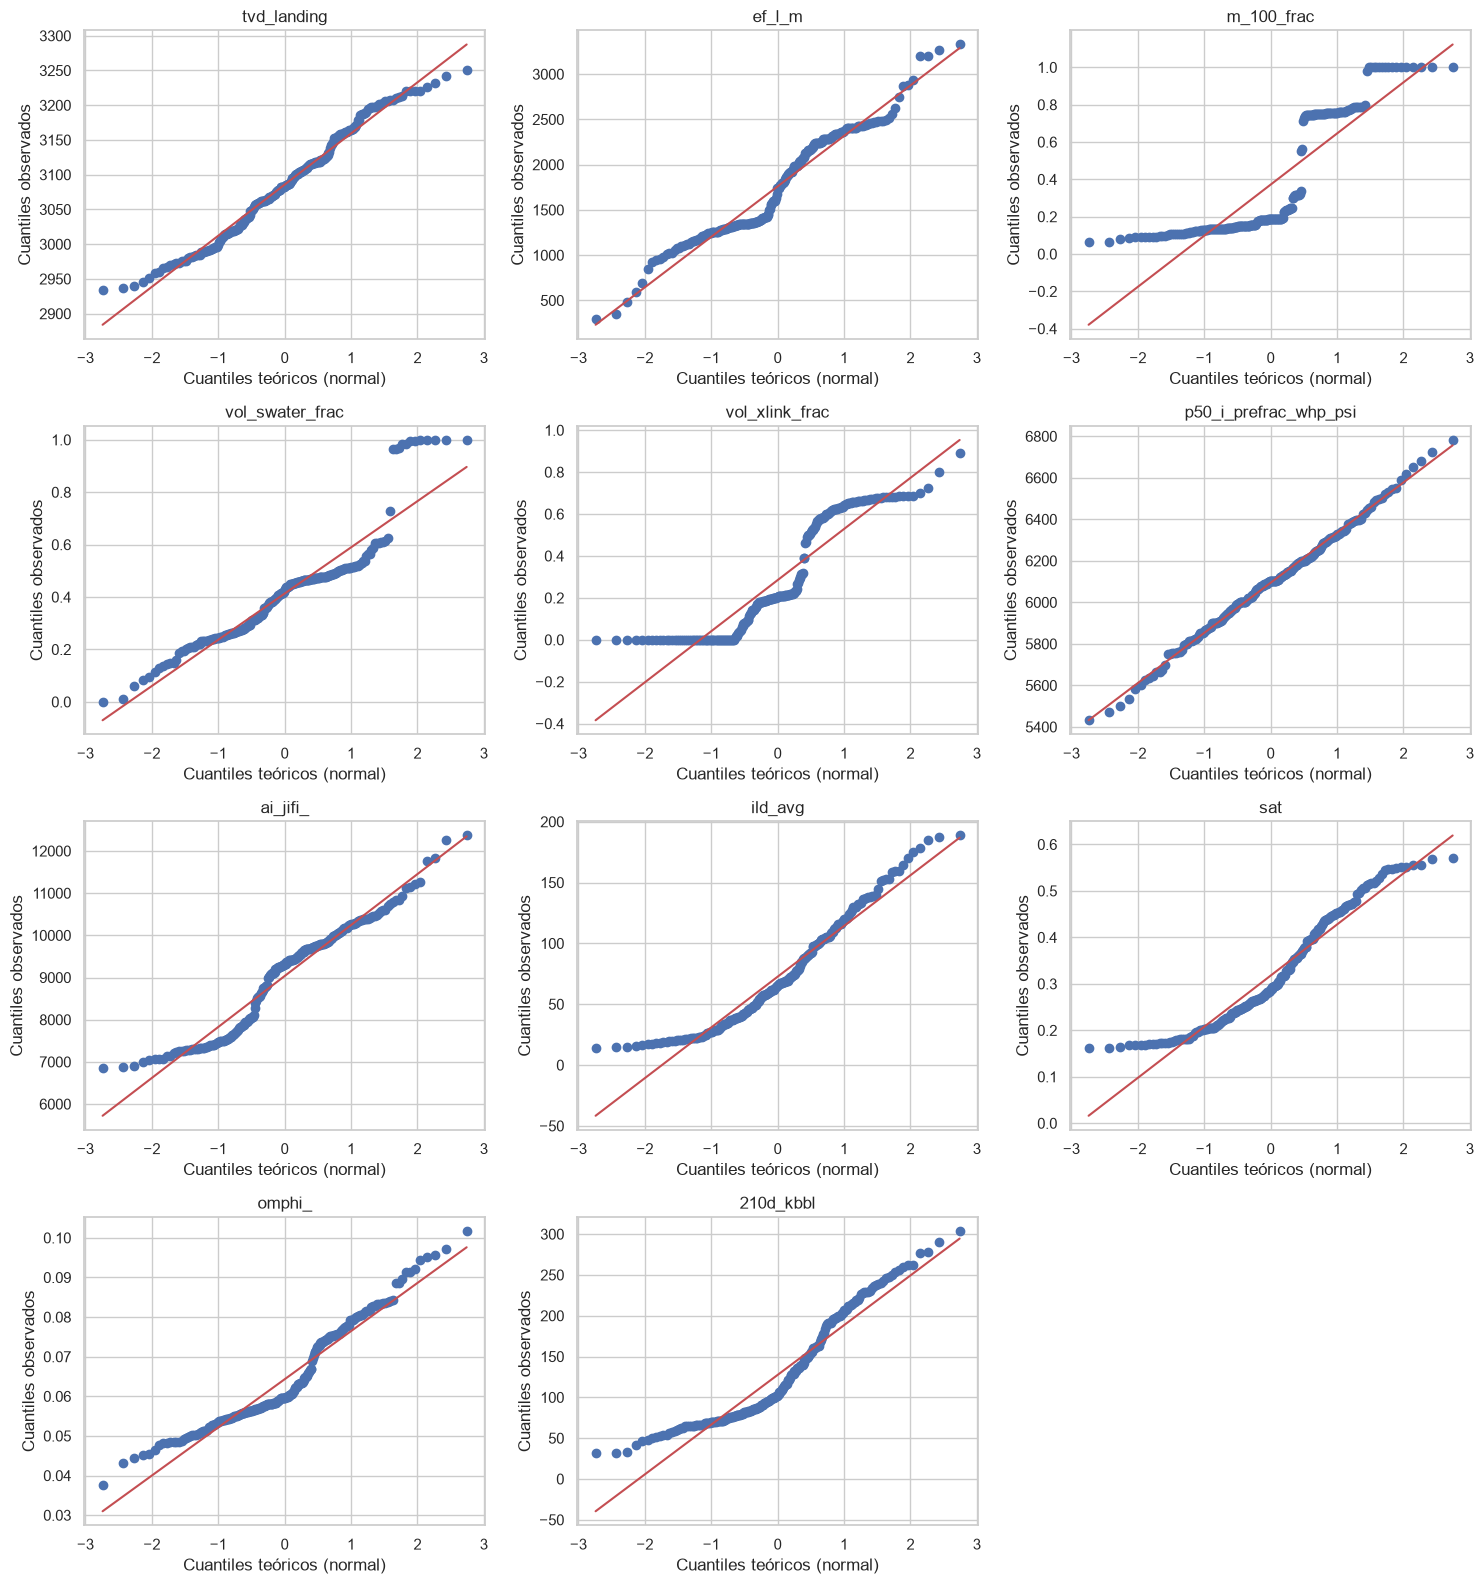

In [ ]:
# Grafico Q-Q (quantile-quantile) para evaluar normalidad de las variables
cols_qq = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', '210d_kbbl'
]
assert all(c in df.columns for c in cols_qq), "Revisá los nombres de columna"

n_cols = 3
n_rows = math.ceil(len(cols_qq) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cols_qq):
    valores = df[col].dropna()
    stats.probplot(valores, dist='norm', plot=ax)
    ax.set_title(col)
    ax.set_xlabel('Cuantiles teóricos (normal)')
    ax.set_ylabel('Cuantiles observados')

# Oculta los paneles sobrantes (11 variables en una grilla de 3 columnas)
for ax in axes[len(cols_qq):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()




Un gráfico Q-Q compara los cuantiles observados de cada variable con los de una normal. Si los puntos siguen la recta, la distribución es aproximadamente normal. Las desviaciones se leen así:

- **Curvatura o colas que se separan de la recta:** asimetría o colas más pesadas que la normal.
- **Tramo horizontal:** muchos valores repetidos o concentrados (por ejemplo, ceros).
- **Tramo muy empinado:** hueco en los datos, es decir, un rango con pocos pozos.

Las variables se agrupan según el tipo de desviación observada.

**Cercanas a la normal.** `p50_i_prefrac_whp_psi` tiene el mejor ajuste del conjunto. `tvd_landing` sigue la recta en el centro y solo se aparta en los extremos.

**Con huecos en el centro.** `ef_l_m` sigue la recta en el tramo central, pero tiene un hueco y su extremo superior queda por encima de la recta, lo que indica una cola hacia la derecha. Coincide con la distribución bimodal. `ai_jifi_` tiene forma de S: aunque su asimetría es casi nula (−0,037), ambos extremos se apartan de la recta y hay un hueco a

**Con grupos separados.** `m_100_frac` es la variable con desviaciones más marcadas. Se distinguen tres niveles: valores bajos entre 0,06 y 0,35, con una meseta entre 0,1 y 0,2; un grupo intermedio cerca de 0,7 a 0,8, y un grupo cerca de 1,0. Entre el primer y el segundo nivel hay un hueco. 

`vol_swater_frac` sigue la recta en el centro. Su cola superior tiene un grupo de unos 12 pozos con valores cercanos a 1,0, y hay un punto aislado alrededor de 0,73. En el extremo inferior hay pozos sin slickwater.

`vol_xlink_frac` tiene un tramo horizontal en 0. Corresponde a unos 57 pozos, es decir, alrededor del 25 % del conjunto, que no usan crosslinker. Después hay un hueco entre 0,2 y 0,4, y la cola superior llega a valores cercanos a 0,9.

**Con cola hacia la derecha.** `210d_kbbl`, `ild_avg`, `sat` y `omphi_` tienen los valores bajos agrupados por encima de la recta, lo que indica una cola inferior comprimida, y los valores altos se apartan hacia arriba. Esto es un patrón de asimetría positiva. En `ild_avg` la mayor desviación está en el extremo inferior, no en el superior.


## 8. Graficos de Distribución

### 8.1 - Defino Variables 

In [66]:
# Variables del modelo y objetivo
predictoras_modelo = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_'
]
objetivo = '210d_kbbl'
cols_dist = predictoras_modelo + [objetivo]

# Reconstruye la etiqueta de zona (Zona A = referencia)
zona_label = np.select(
    [df['zona_b'] == 1, df['zona_c'] == 1, df['zona_d'] == 1],
    ['Zona B', 'Zona C', 'Zona D'],
    default='Zona A'
)
df['zona_label'] = zona_label #Reconstruyo esta columna ya que si no tendriamos error al graficarla.


### 8.2 - Histogramas

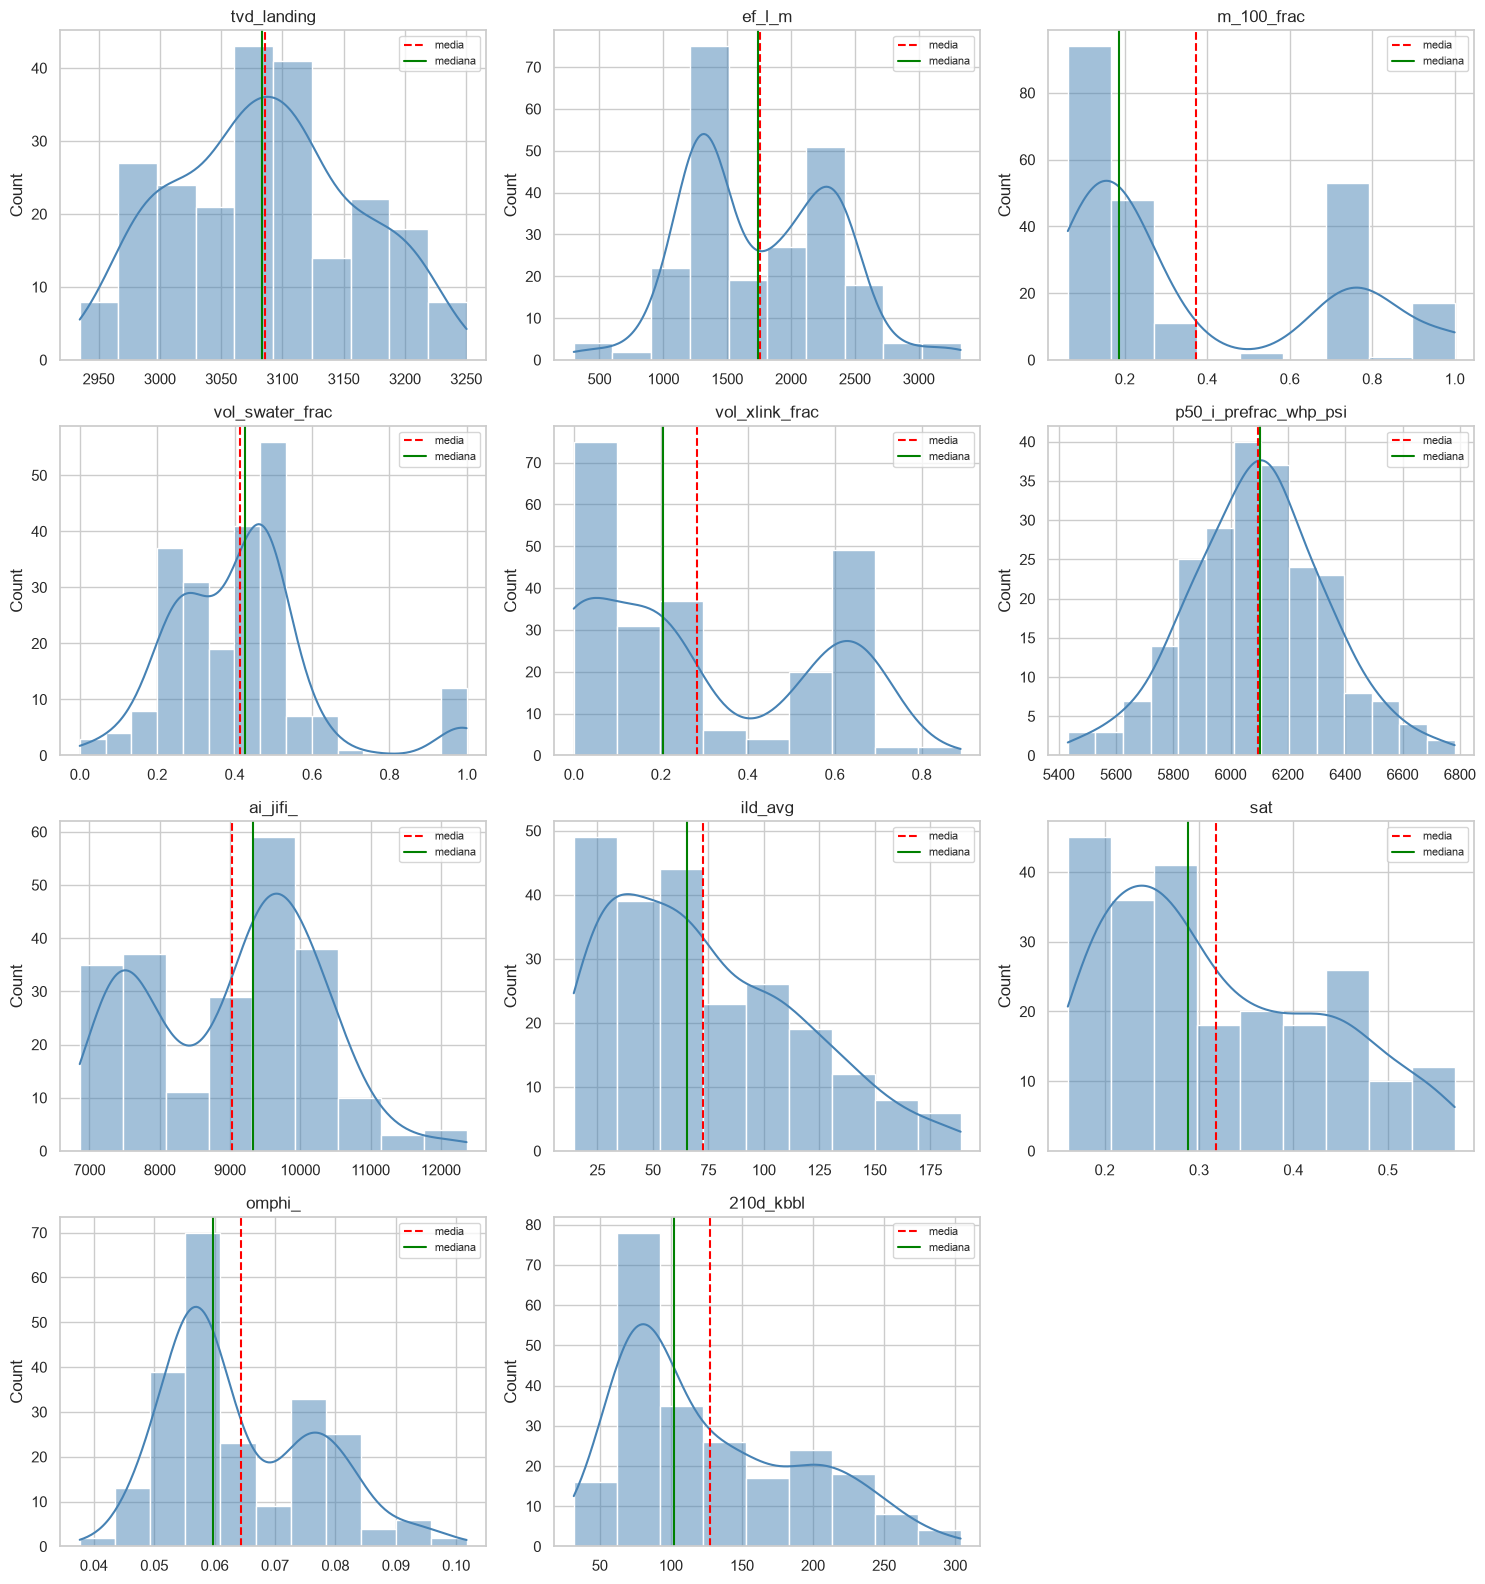

In [ ]:
n_cols = 3
n_rows = math.ceil(len(cols_dist) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cols_dist):
    sns.histplot(df[col], bins='auto', kde=True, ax=ax, color='steelblue')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label='media')
    ax.axvline(df[col].median(), color='green', linestyle='-', label='mediana')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.legend(fontsize=8)

for ax in axes[len(cols_dist):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


#### 8.2.1 Comprobación de huecos en la distribución

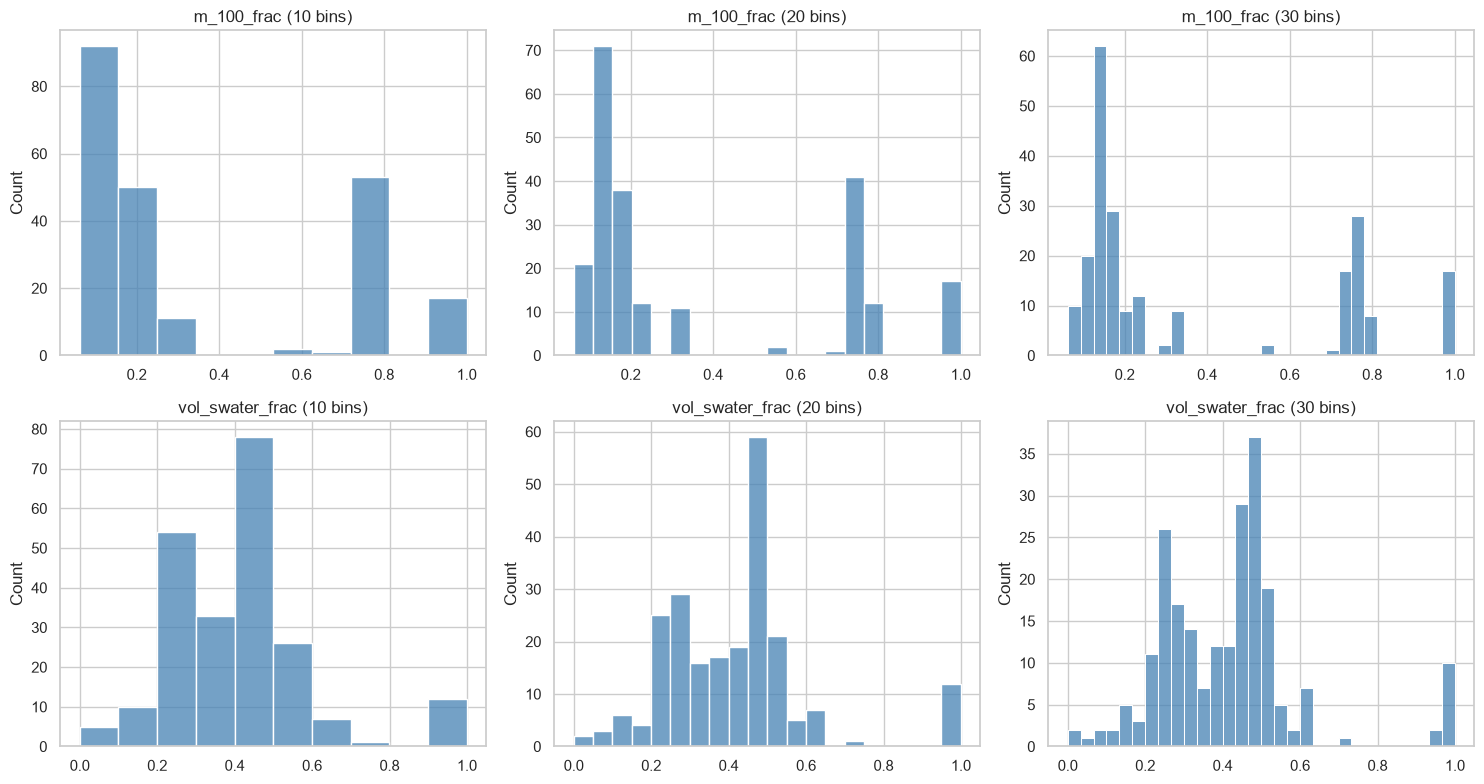

m_100_frac entre 0,4 y 0,7: 2
vol_swater_frac entre 0,65 y 0,95: 1


In [31]:
# Comprobación de huecos: mismos datos, distinto número de bins.
# Un hueco que persiste con 10, 20 y 30 bins es una característica de los datos.
variables_hueco = ['m_100_frac', 'vol_swater_frac']
bins_prueba = [10, 20, 30]

fig, axes = plt.subplots(len(variables_hueco), len(bins_prueba), figsize=(15, 4 * len(variables_hueco)))

for fila, col in zip(axes, variables_hueco):
    for ax, bins in zip(fila, bins_prueba):
        sns.histplot(df[col], bins=bins, kde=False, ax=ax, color='steelblue')
        ax.set_title(f'{col} ({bins} bins)')
        ax.set_xlabel('')

plt.tight_layout()
plt.show()

# Conteo de pozos en los intervalos sin datos. Se usa el mismo corte que en el texto:
# m_100_frac entre 0,4 y 0,7; vol_swater_frac entre 0,65 y 0,95
print("m_100_frac entre 0,4 y 0,7:", int(df['m_100_frac'].between(0.4, 0.7).sum()))
print("vol_swater_frac entre 0,65 y 0,95:", int(df['vol_swater_frac'].between(0.65, 0.95).sum()))

Observamos ciertos huecos en las variables `m_100_frac` y `vol_swater_frac`. 

Para descartar que los huecos observados en los histogramas sean un efecto del número de bins, se graficaron `m_100_frac` y `vol_swater_frac` con 10, 20 y 30 bins, y se contaron los pozos dentro de los intervalos sin datos.

##### Lectura de `m_100_frac`

El hueco entre 0,4 y 0,7 se mantiene con 10, 20 y 30 bins. Con 10 bins aparece como un espacio vacío, y con 20 y 30 se ven los mismos pocos pozos sueltos cerca de 0,55 (una barra de 2 pozos). El conteo confirma que hay 2 pozos en ese intervalo, así que no es un vacío total sino una zona casi sin datos.

Además, los grupos siguen separados: uno entre 0,05 y 0,35, otro entre 0,7 y 0,8 y un tercero cerca de 1,0. Con 30 bins se ve que el grupo alto se parte en dos picos (cerca de 0,75 y de 1,0), lo que es consistente con la observación del gráfico Q-Q de la sección 7.

**Conclusión:** el hueco es real. Hay una zona con 2 pozos en el intervalo, no un efecto del ancho del bin.

##### Lectura de `vol_swater_frac`

El intervalo entre 0,65 y 0,95 tiene 1 pozo, y el hueco aparece con 10 y 20 bins. Con 30 bins se ven puntos aislados cerca de 0,7 y 0,75, que son los que forman el conteo de 1. El grupo cercano a 1,0 queda claramente separado del resto, con unos 12 pozos, lo que coincide con el análisis de valores extremos.

**Conclusión:** el hueco es real. El grupo de alto slickwater está separado del pico principal, pero hay muy pocos pozos entre ambos.

### 8.3 - Relacion entre variables predictoras

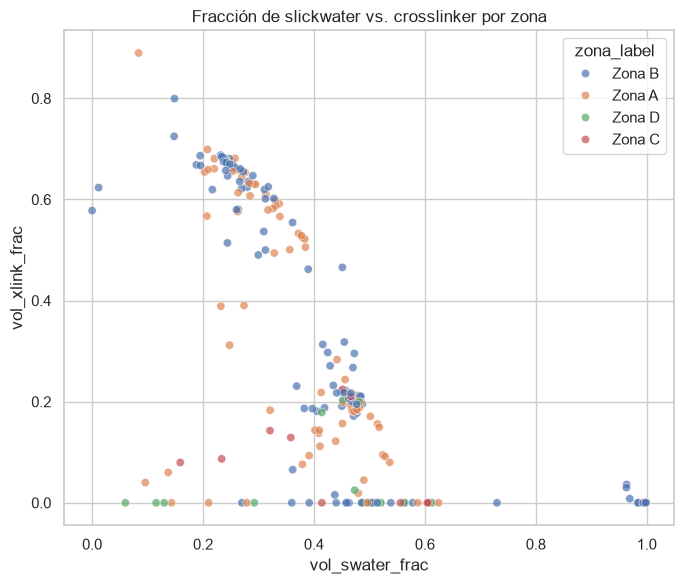

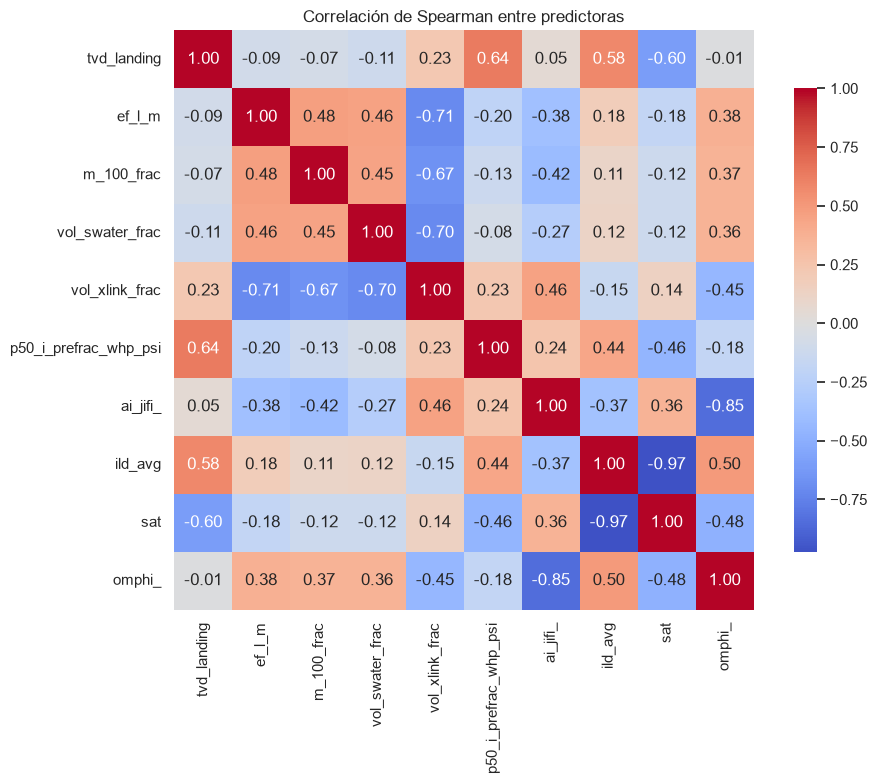

In [32]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x='vol_swater_frac', y='vol_xlink_frac',
                hue='zona_label', alpha=0.7, ax=ax)
ax.set_title('Fracción de slickwater vs. crosslinker por zona')
ax.set_xlabel('vol_swater_frac')
ax.set_ylabel('vol_xlink_frac')
plt.tight_layout()
plt.show()

# Matriz de correlación de Spearman entre predictoras (robusta a asimetría y extremos)
# Sirve para detectar colinealidad antes de entrenar el modelo
corr = df[predictoras_modelo].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlación de Spearman entre predictoras')
plt.tight_layout()
plt.show()



Esta sección busca detectar relaciones entre predictoras que puedan afectar la interpretación del modelo. Dos variables que miden casi lo mismo, o que se mueven juntas, aportan información redundante. Esto importa en regresión lineal, donde puede volver inestables los coeficientes.

**Relación entre slickwater y crosslinker.** El gráfico de dispersión muestra una relación negativa entre `vol_swater_frac` y `vol_xlink_frac`: a mayor fracción de slickwater, menor fracción de crosslinker. Se distinguen tres agrupamientos: pozos con slickwater bajo y crosslinker alto (entre 0,6 y 0,8), pozos con slickwater medio (0,4 a 0,5) y crosslinker cercano a 0,2, y el grupo de unos 12 pozos con slickwater cercano a 1,0 y sin crosslinker. La mayoría de los pozos queda por debajo de la recta de suma igual a 1, por lo que las dos fracciones no representan un volumen total fijo. Las zonas aparecen mezcladas en toda la distribución, sin una separación clara por bloque.

**Matriz de correlación de Spearman.** Se usó el coeficiente de Spearman porque no supone linealidad ni normalidad y es robusto a valores extremos. La matriz incluye las 10 predictoras del modelo y excluye el objetivo, porque el objetivo no es una predictora. Cada celda indica la correlación de rangos entre dos variables, entre −1 y 1. Los valores cercanos a ±1 indican información redundante. Como guía de lectura, se consideran de interés las correlaciones con valor absoluto mayor o igual a 0,5; no es un criterio formal de eliminación. Las relaciones más fuertes son:

| Par de variables | Correlación de Spearman |
|---|---|
| `ild_avg` y `sat` | −0,97 |
| `ai_jifi_` y `omphi_` | −0,85 |
| `vol_xlink_frac` y `ef_l_m` | −0,71 |
| `vol_xlink_frac` y `vol_swater_frac` | −0,70 |
| `vol_xlink_frac` y `m_100_frac` | −0,67 |
| `tvd_landing` y `p50_i_prefrac_whp_psi` | 0,64 |
| `tvd_landing` y `sat` | −0,60 |
| `tvd_landing` y `ild_avg` | 0,58 |

Las correlaciones de `ild_avg` con `sat` y de `ai_jifi_` con `omphi_` son muy altas, por lo que estas variables aportan información casi redundante.


### 8.4 - Relacion entre variable predictora y Objetivo

Pregunta: ¿La produccion a 210 dias cambia segun la zona y la longitud de rama?

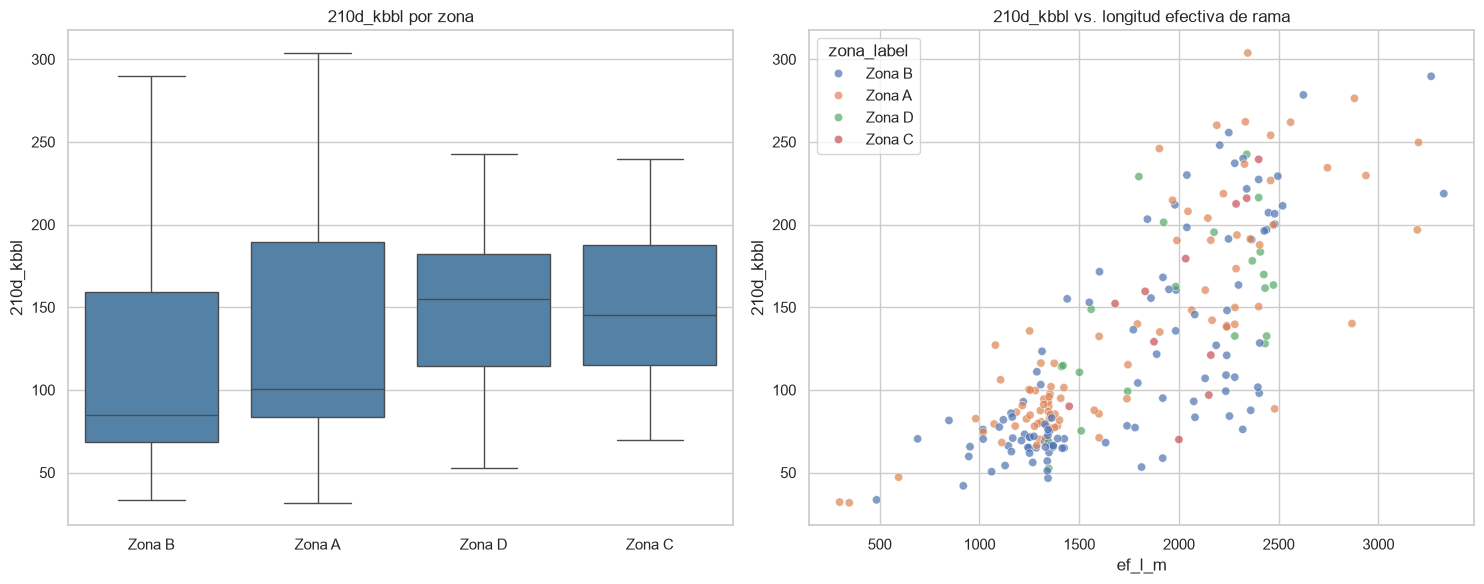

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=df, x='zona_label', y=objetivo, ax=axes[0], color='steelblue')
axes[0].set_title('210d_kbbl por zona')
axes[0].set_xlabel('')

sns.scatterplot(data=df, x='ef_l_m', y=objetivo, hue='zona_label', alpha=0.7, ax=axes[1])
axes[1].set_title('210d_kbbl vs. longitud efectiva de rama')
axes[1].set_xlabel('ef_l_m')

plt.tight_layout()
plt.show()


In [34]:

# Medianas por sextil de ef_l_m sobre el scatter (muestra la forma de la relación)
sextiles = pd.qcut(df['ef_l_m'], q=6)
medianas = df.groupby(sextiles, observed=True).agg(
    ef=('ef_l_m', 'median'),
    kbbl=(objetivo, 'median'),
)
axes[1].plot(medianas['ef'], medianas['kbbl'], 'o-', color='red', label='mediana por sextil')
axes[1].legend(fontsize=8)

print(df.groupby('zona_label')[objetivo].agg(n='count', mediana='median').round(1).to_string())

              n  mediana
zona_label              
Zona A       86    100.8
Zona B      106     85.1
Zona C       12    145.5
Zona D       22    155.2


In [35]:
# Mediana de la longitud efectiva de rama en cada zona
print(df.groupby('zona_label')['ef_l_m'].median().round(0).to_string())

zona_label
Zona A    1404.0
Zona B    1617.0
Zona C    2092.0
Zona D    2080.0


In [36]:
# Terciles de longitud de rama y mediana de 210d_kbbl por zona dentro de cada tercil
df['tercil_ef'] = pd.qcut(df['ef_l_m'], q=3, labels=['rama corta', 'rama media', 'rama larga'])

tabla_control = (
    df.groupby(['tercil_ef', 'zona_label'], observed=True)[objetivo]
      .agg(n='count', mediana='median')
      .round(1)
)
print(tabla_control.to_string())

                        n  mediana
tercil_ef  zona_label             
rama corta Zona A      33     84.8
           Zona B      41     69.3
           Zona D       2     60.6
rama media Zona A      26     99.5
           Zona B      34     99.6
           Zona C       6    140.7
           Zona D       9    114.7
rama larga Zona A      27    199.8
           Zona B      31    196.2
           Zona C       6    175.6
           Zona D      11    169.8



**Pregunta:** ¿la producción a 210 días cambia según la zona y según la longitud efectiva de la rama?

Para responderla se analizaron dos variables: la zona, que es categórica, y la longitud efectiva de la rama (`ef_l_m`), que es continua. Como las zonas no tienen la misma longitud de rama promedio, la comparación entre zonas se revisó dentro de cada tercil de `ef_l_m`.

---

#### Producción por zona

El boxplot muestra la distribución de `210d_kbbl` en cada zona. Las medianas son de 85,1 kbbl en la Zona B, 100,8 kbbl en la Zona A, 145,5 kbbl en la Zona C y 155,2 kbbl en la Zona D. La Zona B tiene la mediana más baja en el total, y las Zonas C y D las más altas. La Zona A tiene la caja más ancha, es decir, la mayor dispersión central.

El tamaño de los grupos es desigual: la Zona A tiene 86 pozos, la B 106, la C 12 y la D 22. Por eso las medianas de C y D son menos estables que las de A y B.

---

#### Producción según la longitud de rama

El gráfico de dispersión muestra una relación positiva entre `ef_l_m` y `210d_kbbl`, pero no lineal. Por debajo de 1.500 m la producción se concentra entre 50 y 120 kbbl. A partir de aproximadamente 2.000 m aparecen pozos con producciones de 150 a 300 kbbl. La dispersión dentro de cada tramo es grande, por lo que la longitud de rama explica una parte importante de la producción, pero no toda.

---

#### Control por longitud de rama

La mediana de `ef_l_m` es de 1.404 m en la Zona A, 1.617 m en la Zona B, 2.092 m en la Zona C y 2.080 m en la Zona D. La composición por longitud es distinta entre zonas, por lo que la diferencia en el total puede deberse en parte a la rama.

Entre la Zona A y la Zona B, la diferencia se concentra en las ramas cortas: 84,8 kbbl frente a 69,3 kbbl. En los terciles de rama media (99,5 y 99,6 kbbl) y larga (199,8 y 196,2 kbbl), las medianas son prácticamente iguales. La menor producción de la Zona B en el total se explica, por lo tanto, sobre todo por su menor producción en ramas cortas.

Las Zonas C y D tienen medianas altas en el total, pero esa diferencia se debe a su composición: la Zona C no tiene pozos de rama corta y la mayoría de la Zona D está en ramas largas. Dentro de cada tercil no presentan una diferencia estable respecto de A y B. Además, varias celdas tienen menos de 5 pozos (Zona D en rama corta, con 2 pozos; Zonas C y D en los demás terciles, con 6 a 11), por lo que sus medianas son orientativas.

---

#### Respuesta a la pregunta

- **Zona:** en el total, la Zona B tiene la producción más baja y las Zonas C y D las más altas. Una vez controlada la longitud de rama, la zona no muestra un efecto independiente y claro: entre A y B la única diferencia que se sostiene es la de la rama corta.
- **Longitud de rama:** la producción aumenta con `ef_l_m` de forma no lineal, con un salto alrededor de 2.000 m. La longitud explica la mayor parte de las diferencias observadas.

En conclusión, la producción a 210 días depende en mayor medida de la longitud efectiva de la rama que de la zona. 

# Parte 3 - Modelado predictivo


## 9. Elegí un modelo predictivo adecuado para el tipo de problema (ej: regresión lineal, k-NN; árbol de decisión).

In [68]:
#Importar XGBoost y LightGBM 
#Nota: No se porque pero cuando importaba el xgboost y el lightgbm me tiraba error en vs code. Tuve que modificar el codigo con IA para solucionarlo

try:
    import xgboost as xgb
    ClaseXGB = xgb.XGBRegressor
    USA_XGB_EXTERNO = True
    print("XGBoost cargado correctamente desde librería externa (xgboost.XGBRegressor).")
except (ImportError, AttributeError):
    ClaseXGB = GradientBoostingRegressor
    USA_XGB_EXTERNO = False
    print("Aviso: usando GradientBoostingRegressor nativo de scikit-learn.")

try:
    import lightgbm as lgb
    ClaseLGBM = lgb.LGBMRegressor
    USA_LGBM_EXTERNO = True
    print("LightGBM cargado correctamente desde librería externa (lightgbm.LGBMRegressor).")
except (ImportError, AttributeError):
    ClaseLGBM = HistGradientBoostingRegressor
    USA_LGBM_EXTERNO = False
    print("Aviso: usando HistGradientBoostingRegressor nativo de scikit-learn.")

# Selección de las 13 variables predictoras válidas (previas a la puesta en producción)
features = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_',
    'zona_b', 'zona_c', 'zona_d'
]
objetivo = '210d_kbbl'

# Verificación de integridad de columnas
assert all(c in df.columns for c in features + [objetivo]), "Faltan columnas en df"

X = df[features]
y = df[objetivo]

# Esquema de validación cruzada: 5 folds mezclados con semilla fija para reproducibilidad
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

resultados = {}

def evaluar(nombre, modelo):
    """
    Ejecuta validación cruzada de 5 folds y registra media y desvío 
    en validación (test) junto con el desempeño en entrenamiento (train)
    para diagnosticar sobreajuste.
    """
    res = cross_validate(
        modelo, X, y,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )
    resultados[nombre] = {
        'MAE train': -res['train_mae'].mean(),
        'MAE CV (media)': -res['test_mae'].mean(),
        'MAE CV (desvío)': res['test_mae'].std(),
        'RMSE CV (media)': -res['test_rmse'].mean(),
        'RMSE CV (desvío)': res['test_rmse'].std(),
        'R² train': res['train_r2'].mean(),
        'R² CV (media)': res['test_r2'].mean(),
        'R² CV (desvío)': res['test_r2'].std(),
    }
    print(
        f"{nombre:<52} | "
        f"MAE CV = {resultados[nombre]['MAE CV (media)']:5.2f} ± {resultados[nombre]['MAE CV (desvío)']:4.2f} | "
        f"R² CV = {resultados[nombre]['R² CV (media)']:6.3f}"
    )

XGBoost cargado correctamente desde librería externa (xgboost.XGBRegressor).
LightGBM cargado correctamente desde librería externa (lightgbm.LGBMRegressor).


In [71]:

# 1. Dummy: predice siempre la media del conjunto de entrenamiento (piso de comparación)
modelo_dummy = DummyRegressor(strategy='mean')

# 2. Regresión lineal
modelo_lineal = Pipeline([
    ('escala', RobustScaler()),
    ('lineal', LinearRegression()),
])

# 3. Árbol de decisión
modelo_arbol = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42,
)

# 4. Random Forest
modelo_bosque = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=5,
    max_features=0.5,
    random_state=42,
    n_jobs=-1,
)

# 5. XGBoost
if USA_XGB_EXTERNO:
    modelo_xgb = ClaseXGB(
        n_estimators=200,
        max_depth=3,            # Árboles cortos para evitar memorizar 180 pozos
        learning_rate=0.05,    
        min_child_weight=5,     # Mínimo peso por hoja
        subsample=0.8,          # 80% de pozos en cada árbol
        colsample_bytree=0.8,   # 80% de variables en cada árbol
        random_state=42,
        n_jobs=-1,
        verbosity=0,
    )
else:
    modelo_xgb = ClaseXGB(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        min_samples_leaf=5,
        subsample=0.8,
        max_features=0.8,
        random_state=42,
    )

# 6. LightGBM 
if USA_LGBM_EXTERNO:
    modelo_lgbm = ClaseLGBM(
        n_estimators=200,
        max_depth=3,
        num_leaves=7,           # Controla la cantidad máxima de hojas (<= 2^3 - 1)
        min_child_samples=10,   # Mínimo de pozos por hoja
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1,
    )
else:
    modelo_lgbm = ClaseLGBM(
        max_iter=200,
        max_depth=3,
        max_leaf_nodes=7,
        min_samples_leaf=10,
        learning_rate=0.05,
        random_state=42,
    )

# Evaluamos todos los modelos y guardamos en el diccionario 'resultados'
modelos_candidatos = {
    'Dummy (media)': modelo_dummy,
    'Regresión lineal': modelo_lineal,
    'Árbol de decisión (prof. 5, hoja 5)': modelo_arbol,
    'Random forest (200 árb., prof. 5, hoja 5, 50% var.)': modelo_bosque,
    'XGBoost (200 árb., prof. 3, lr=0.05)': modelo_xgb,
    'LightGBM (200 árb., prof. 3, hoja 10, lr=0.05)': modelo_lgbm,
}

resultados.clear()
for nombre, mod in modelos_candidatos.items():
    evaluar(nombre, mod)

Dummy (media)                                        | MAE CV = 54.07 ± 1.18 | R² CV = -0.019
Regresión lineal                                     | MAE CV = 24.29 ± 0.68 | R² CV =  0.770
Árbol de decisión (prof. 5, hoja 5)                  | MAE CV = 24.35 ± 2.15 | R² CV =  0.732
Random forest (200 árb., prof. 5, hoja 5, 50% var.)  | MAE CV = 22.51 ± 3.31 | R² CV =  0.786
XGBoost (200 árb., prof. 3, lr=0.05)                 | MAE CV = 21.74 ± 2.42 | R² CV =  0.795
LightGBM (200 árb., prof. 3, hoja 10, lr=0.05)       | MAE CV = 22.80 ± 2.81 | R² CV =  0.775


In [74]:
tabla_resultados = pd.DataFrame(resultados).T

# Detecta automáticamente el nombre de la columna de MAE de validación
col_mae_cv = 'MAE (media)' if 'MAE (media)' in tabla_resultados.columns else 'MAE CV (media)'

if 'MAE train' in tabla_resultados.columns:
    tabla_resultados['Brecha MAE (CV - Train)'] = (
        tabla_resultados[col_mae_cv] - tabla_resultados['MAE train']
    )

print(tabla_resultados.round(2).to_string())

                                                     MAE train  MAE CV (media)  MAE CV (desvío)  RMSE CV (media)  RMSE CV (desvío)  R² train  R² CV (media)  R² CV (desvío)  Brecha MAE (CV - Train)
Dummy (media)                                            53.79           54.07             1.18            63.30              1.95      0.00          -0.02            0.02                     0.28
Regresión lineal                                         21.96           24.29             0.68            30.10              1.09      0.81           0.77            0.01                     2.32
Árbol de decisión (prof. 5, hoja 5)                      15.46           24.35             2.15            32.35              3.07      0.90           0.73            0.04                     8.89
Random forest (200 árb., prof. 5, hoja 5, 50% var.)      15.72           22.51             3.31            28.84              4.08      0.89           0.79            0.05                     6.79
XGBoost (200 ár


#### Modelos evaluados

Para abordar la predicción de la producción acumulada de petróleo a 210 días (`210d_kbbl`) a partir de las 13 variables predictoras disponibles antes de la puesta en producción, se seleccionaron y compararon seis modelos pertenecientes a distintas familias algorítmicas:

1. **DummyRegressor (media):** predice siempre el valor promedio de `210d_kbbl` del conjunto de entrenamiento en cada partición. No posee capacidad de aprendizaje real y se incluye como línea base (*baseline*) para cuantificar la ganancia predictiva del resto de los modelos.
2. **Regresión Lineal Múltiple:** modelo paramétrico que estima una relación lineal aditiva entre los predictores y la producción acumulada. Se integró dentro de un `Pipeline` junto con un escalador  (`RobustScaler`)
3. **Árbol de Decisión de Regresión:** modelo no paramétrico basado en particiones binarias recursivas del espacio de predictores (`max_depth = 5`, `min_samples_leaf = 5`). Permite capturar relaciones no lineales e interacciones entre la geología, la zona y el diseño de fractura sin imponer una forma funcional previa.
4. **Random Forest (*Bagging*):** ensamble en paralelo compuesto por 200 árboles de decisión (`n_estimators = 200`, `max_depth = 5`, `min_samples_leaf = 5`, `max_features = 0.5`) entrenados sobre muestras *bootstrap* de los pozos y subconjuntos aleatorios de variables. Su propósito es reducir la varianza e inestabilidad propia de un árbol individual promediando sus predicciones.
5. **XGBoost (*Gradient Boosting* por niveles):** ensamble secuencial de 200 árboles (`max_depth = 3`, `learning_rate = 0.05`, `min_child_weight = 5`, `subsample = 0.8`, `colsample_bytree = 0.8`) donde cada árbol nuevo se entrena para corregir los errores residuales cometidos por los árboles anteriores, combinando reducción de sesgo con penalizaciones de regularización.
6. **LightGBM (*Gradient Boosting* por hojas basado en histogramas):** variante de *boosting* secuencial (`n_estimators = 200`, `max_depth = 3`, `num_leaves = 7`, `min_child_samples = 10`, `learning_rate = 0.05`) que agrupa las variables continuas en histogramas discretos y expande los árboles dividiendo la hoja que aporta la mayor reducción de pérdida (*leaf-wise*).

---

#### Metodología y criterios de comparación

Todos los modelos fueron evaluados bajo condiciones idénticas sobre los 226 pozos del conjunto de trabajo mediante **validación cruzada de 5 folds** mezclados aleatoriamente con semilla fija (`KFold(n_splits=5, shuffle=True, random_state=42)`). En cada iteración se entrenó con el 80 % de los registros (~181 pozos) y se evaluó sobre el 20 % restante (~45 pozos).

Dado que `210d_kbbl` es una variable cuantitativa continua, el desempeño se midió exclusivamente con métricas de **regresión**:
- **MAE (*Mean Absolute Error*, en kbbl):** mide la magnitud promedio del error absoluto en las mismas unidades físicas de la variable objetivo, penalizando los desvíos de forma lineal.
- **RMSE (*Root Mean Squared Error*, en kbbl):** eleva los errores al cuadrado antes de promediarlos y aplica la raíz cuadrada, por lo que castiga con mayor severidad los errores grandes en pozos individuales.
- **R² (Coeficiente de Determinación, adimensional):** cuantifica la proporción de la variabilidad total de `210d_kbbl` explicada por el modelo frente a predecir la media simple.

Se descartó el uso de métricas propias de clasificación (*Accuracy*, *Precision*, *Recall* y *F1-score*) como criterio de evaluación y selección del modelo, ya que estas evalúan aciertos discretos de pertenencia a una categoría y requieren discretizar artificialmente la producción mediante un umbral arbitrario, perdiendo sensibilidad sobre la magnitud real del error en barriles. Asimismo, se registraron las métricas sobre los datos de entrenamiento (`MAE train` y `R² train`) y la **brecha de error (`MAE CV - MAE train`)** para diagnosticar objetivamente el grado de sobreajuste (*overfitting*) de cada familia.

---

#### Resultados obtenidos

La siguiente tabla resume la media y el desvío estándar entre los 5 *folds* de validación cruzada, junto con el comportamiento en entrenamiento:

| Modelo | MAE train (kbbl) | MAE CV (kbbl) | RMSE CV (kbbl) | R² train | R² CV | Brecha MAE (CV − Train) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Dummy (media)** | 53,79 | 54,07 ± 1,18 | 63,30 ± 1,95 | 0,00 | −0,02 ± 0,02 | 0,28 |
| **Regresión lineal** | 21,96 | 24,29 ± 0,68 | 30,10 ± 1,09 | 0,81 | 0,77 ± 0,01 | **2,32** |
| **Árbol de decisión (prof. 5, hoja 5)** | 15,46 | 24,35 ± 2,15 | 32,35 ± 3,07 | 0,90 | 0,73 ± 0,04 | 8,89 |
| **Random forest (200 árb., prof. 5, hoja 5, 50% var.)** | 15,72 | 22,51 ± 3,31 | 28,84 ± 4,08 | 0,89 | 0,79 ± 0,05 | 6,79 |
| **XGBoost (200 árb., prof. 3, lr=0.05)** | 7,49 | **21,74 ± 2,42** | **28,24 ± 3,43** | 0,98 | **0,80 ± 0,04** | 14,25 |
| **LightGBM (200 árb., prof. 3, hoja 10, lr=0.05)** | 9,62 | 22,80 ± 2,81 | 29,62 ± 2,81 | 0,96 | 0,78 ± 0,04 | 13,18 |

**Lectura técnica de los resultados:**
- **Superación del piso de referencia:** los cinco modelos predictivos superan ampliamente al `DummyRegressor` (`MAE = 54,07 kbbl`), reduciendo el error absoluto medio a más de la mitad.
- **Componente lineal dominante:** la **Regresión Lineal** alcanza por sí sola un `R² CV = 0,77 ± 0,01` y un `MAE CV = 24,29 ± 0,68 kbbl`.
- **Rendimiento de los modelos basados en árboles:** el **Árbol de Decisión** individual no logra superar a la Regresión Lineal (`MAE CV = 24,35 kbbl`, `R² CV = 0,73`) y triplica su dispersión entre *folds* (`± 2,15 kbbl`). Los ensambles logran reducir el error promedio en validación: **XGBoost** obtiene el menor MAE medio (`21,74 kbbl`, `RMSE = 28,24 kbbl`, `R² = 0,80`), seguido por **Random Forest** (`22,51 kbbl`, `R² = 0,79`) y **LightGBM** (`22,80 kbbl`, `R² = 0,78`).
- **Compromiso entre error medio, estabilidad y sobreajuste:** a pesar de que `XGBoost`, `Random Forest` y `LightGBM` mejoran el MAE promedio de la Regresión Lineal en `2,55 kbbl`, `1,78 kbbl` y `1,49 kbbl` respectivamente, esa ventaja es comparable o inferior al desvío estándar entre *folds* de los propios ensambles (`± 2,42` a `± 3,31 kbbl`). Además, dado el tamaño reducido de cada *fold* de entrenamiento (~181 pozos), los modelos de *Boosting* muestran un marcado sobreajuste: alcanzan un ajuste casi perfecto en entrenamiento (`R² train` de `0,96` a `0,98` y `MAE train` de `7,49` a `9,62 kbbl`), generando una brecha de más de `13 a 14 kbbl` respecto de validación, frente a una brecha mínima de `2,32 kbbl` y un desvío entre *folds* de apenas `0,68 kbbl` en la Regresión Lineal.

---

#### Selección del modelo final

Para elegir el modelo de forma rigurosa no se toma únicamente el menor promedio puntual de una métrica aislada, sino el equilibrio entre **capacidad de generalización, estabilidad entre particiones, bajo sobreajuste e interpretabilidad operativa**:

- **Modelo seleccionado como referencia principal y candidato final: Regresión Lineal.** Es el modelo que mejor generaliza sobre el tamaño de muestra disponible: presenta la menor brecha entre entrenamiento y validación (`2,32 kbbl`), la mayor estabilidad entre los 5 *folds* (`MAE desvío = 0,68 kbbl`, `R² desvío = 0,01`), un desempeño predictivo competitivo (`R² = 0,77`) y plena trazabilidad de sus coeficientes para un entorno de ingeniería.
- **Modelos que se conservan para el ajuste de hiperparámetros (Puntos 10 y 11):** con el objetivo de verificar si el control estricto de la complejidad permite reducir el sobreajuste observado en los métodos no paramétricos y consolidar una ventaja estadísticamente robusta frente a la Regresión Lineal, en las secciones siguientes se analizan y optimizan los hiperparámetros fundamentales de los modelos basados en árboles (**Árbol de Decisión**, **Random Forest** y *Gradient Boosting*). La decisión definitiva hacia producción se ratificará tras evaluar si dicha optimización logra superar de manera consistente la estabilidad del modelo lineal.

## 10. Hiperparámetros fundamentales de los modelos

### ¿Qué es un hiperparámetro?

En aprendizaje automático supervisado es fundamental distinguir entre **parámetros** e **hiperparámetros**:

- **Parámetros del modelo:** son los valores internos que el algoritmo aprende automáticamente a partir de los datos de entrenamiento para minimizar el error (por ejemplo, los coeficientes $\beta_j$ y la ordenada al origen en una regresión lineal, o las variables y umbrales de corte elegidos en cada nodo de un árbol de decisión).
- **Hiperparámetros:** son configuraciones externas definidas **antes** del entrenamiento que gobiernan la estructura, la complejidad y el proceso de aprendizaje del algoritmo (por ejemplo, la profundidad máxima de un árbol o la tasa de aprendizaje en un modelo de *boosting*). Su elección controla directamente el equilibrio entre **subajuste** (*underfitting*, sesgo alto) y **sobreajuste** (*overfitting*, varianza alta).

---

### Modelo seleccionado como referencia final: Regresión Lineal

La regresión lineal ordinaria (`LinearRegression` de `scikit-learn`) **no posee hiperparámetros fundamentales de complejidad o regularización** que requieran optimización, ya que sus coeficientes se calculan de forma analítica minimizando el error cuadrático medio.

- Su configuración estructural principal, `fit_intercept`, se mantiene en `True` para estimar la ordenada al origen.
- El escalado de las variables numéricas con `StandardScaler` dentro del `Pipeline` no constituye un hiperparámetro del modelo, sino un paso de preprocesamiento que se ajusta exclusivamente con los datos de entrenamiento de cada *fold* para evitar fuga de información.


---

### Hiperparámetros fundamentales de los modelos basados en árboles y ensambles

A diferencia de la regresión lineal, los modelos no paramétricos evaluados en el Punto 9 dependen críticamente de sus hiperparámetros, especialmente en un conjunto de datos de tamaño reducido (~181 pozos de entrenamiento por *fold*).

#### A. Árbol de Decisión de Regresión (`DecisionTreeRegressor`)

Sus dos hiperparámetros fundamentales regulan de forma directa el tamaño del árbol y evitan que memorice pozos individuales:

| Hiperparámetro | Función | Efecto si aumenta | Efecto si disminuye |
| :--- | :--- | :--- | :--- |
| **`max_depth`** | Máximo de niveles de divisiones sucesivas desde la raíz hasta las hojas. | El árbol captura relaciones más finas e interacciones complejas, pero aumenta el riesgo de sobreajuste. | El árbol es más simple y estable, pero con mayor riesgo de subajuste. |
| **`min_samples_leaf`** | Cantidad mínima de pozos que debe contener cada nodo hoja terminal. | Las hojas promedian más pozos, suavizando las predicciones y reduciendo el sobreajuste. | Se permiten hojas con muy pocos pozos, generando predicciones inestables y sensibles a valores extremos. |

Otros hiperparámetros como `min_samples_split`, `max_features` o `ccp_alpha` también inciden en la poda y complejidad, pero se dejan en sus valores por defecto para evitar ampliar innecesariamente el espacio de búsqueda con esta cantidad de observaciones.

#### B. Random Forest (`RandomForestRegressor` — *Bagging*)

Al ser un ensamble paralelo de árboles entrenados sobre muestras *bootstrap*, comparte los hiperparámetros de complejidad del árbol individual y suma dos configuraciones propias del ensamble:

| Hiperparámetro | Función | Efecto principal |
| :--- | :--- | :--- |
| **`n_estimators`** | Cantidad de árboles en el bosque. | Más árboles reducen la varianza del promedio hasta estabilizarse (a partir de ~200 árboles la mejora suele ser marginal y solo crece el costo computacional). |
| **`max_depth`** | Profundidad máxima de cada árbol del bosque. | Controla cuán específicos se vuelven los árboles individuales respecto del entrenamiento. |
| **`min_samples_leaf`** | Mínimo de pozos exigidos en cada hoja. | Evita que los árboles ajusten ruido o casos aislados. |
| **`max_features`** | Proporción de variables evaluadas al buscar el mejor corte en cada nodo. | Valores menores (ej. `0.33` o `0.5`) aumentan la diversidad entre árboles (descorrelación) y reducen la varianza; valores cercanos a `1.0` hacen los árboles más parecidos entre sí. |

#### C. XGBoost (`XGBRegressor` — *Gradient Boosting* por niveles)

Al construir árboles de forma secuencial donde cada árbol corrige los residuos del anterior, incorpora hiperparámetros que regulan tanto el ritmo de aprendizaje como la regularización estructural:

| Hiperparámetro | Función | Efecto principal |
| :--- | :--- | :--- |
| **`learning_rate`** ($\eta$) | Factor de contracción que pondera el aporte de cada nuevo árbol. | Valores bajos (ej. `0.01`–`0.05`) hacen el aprendizaje más gradual y generalizable, pero requieren más árboles (`n_estimators`). Valores altos aceleran el ajuste y favorecen el sobreajuste. |
| **`n_estimators`** | Número total de árboles secuenciales (rondas de *boosting*). | A diferencia de Random Forest, agregar demasiados árboles en *boosting* **sí puede empeorar el sobreajuste** si no se compensa con un `learning_rate` bajo. |
| **`max_depth`** | Profundidad máxima de cada árbol (crecimiento por niveles). | En *boosting* suelen usarse árboles poco profundos (`2` a `4`) para modelar interacciones acotadas sin memorizar el conjunto de entrenamiento. |
| **`min_child_weight`** | Peso mínimo (en regresión cuadrática, cantidad mínima de pozos) requerido en un nodo hijo para permitir una división. | Valores mayores restringen divisiones en grupos pequeños de pozos, frenando el sobreajuste. |
| **`subsample` y `colsample_bytree`** | Fracción de pozos y de variables muestreadas aleatoriamente para construir cada árbol. | Valores menores a `1.0` (ej. `0.7`–`0.8`) introducen aleatoriedad (*boosting* estocástico) y reducen la varianza entre *folds*. |



#### D. LightGBM (`LGBMRegressor` — *Gradient Boosting* por hojas basado en histogramas)

Comparte la lógica secuencial de *boosting* (`learning_rate`, `n_estimators`, `subsample`, `colsample_bytree`), pero como expande los árboles por hoja (*leaf-wise*) en lugar de por nivel, su control de complejidad se apoya en dos parámetros críticos para muestras pequeñas:

| Hiperparámetro | Función | Efecto principal |
| :--- | :--- | :--- |
| **`num_leaves`** | Número máximo de hojas totales que puede tener un árbol. | Es el controlador principal de complejidad en LightGBM. Debe mantenerse acotado (típicamente $\le 2^{\text{max\_depth}} - 1$, ej. `4` a `15`) para evitar árboles asimétricos muy profundos que sobreajusten. |
| **`min_child_samples`** | Número mínimo de pozos requeridos en una hoja (equivalente a `min_samples_leaf`). | En datasets de ~180 pozos de entrenamiento por *fold*, es determinante: valores muy bajos memorizan ruido y valores demasiado altos (como el defecto de `20`) pueden impedir divisiones útiles. |
| **`max_depth`** | Límite máximo de profundidad del árbol. | Actúa como resguardo adicional junto a `num_leaves` para evitar ramas excesivamente largas. |
| **`learning_rate` y `n_estimators`** | Ritmo de corrección de residuos y cantidad de iteraciones. | Regulan el compromiso entre velocidad de convergencia y capacidad de generalización. |

---

### ¿Qué mejoraría al optimizar estos hiperparámetros?

En los resultados iniciales del Punto 9 (con configuraciones provisorias) se detectaron dos debilidades claras en los modelos basados en árboles y ensambles frente a la regresión lineal (`brecha MAE = 2,32 kbbl` y `desvío CV = ± 0,68 kbbl`):

1. **Reducción del sobreajuste (*brecha entrenamiento vs. validación*):** el árbol de decisión mostró una brecha de `8,89 kbbl` (`MAE train = 15,46` vs. `MAE CV = 24,35`), Random Forest de `6,79 kbbl` (`15,72` vs. `22,51`), LightGBM de `13,18 kbbl` (`9,62` vs. `22,80`) y XGBoost de `14,25 kbbl` (`7,49` vs. `21,74`). Restringir la profundidad, aumentar el tamaño mínimo de hoja y ajustar la tasa de aprendizaje busca **reducir la memorización** de los pozos de entrenamiento.
2. **Mayor estabilidad entre particiones (*folds*):** los desvíos del MAE entre los 5 *folds* fueron entre 3 y 5 veces mayores en los modelos de árboles (`± 2,15` a `± 3,31 kbbl`) que en la regresión lineal (`± 0,68 kbbl`). Una configuración mejor regularizada debería generar errores más parejos frente a cambios en la muestra de entrenamiento.
3. **Búsqueda del punto óptimo de generalización:** permitiría comprobar con evidencia si, una vez controlado el sobreajuste, algún modelo no lineal logra reducir el error de validación (`MAE` y `RMSE`) de forma consistente y estable por encima de la regresión lineal, o si por el contrario se confirma que el modelo lineal sigue siendo la mejor opción para este tamaño de muestra.

---

### ¿Cómo se pueden optimizar los hiperparámetros?

Existen distintos enfoques sistemáticos para buscar buenas combinaciones de hiperparámetros. En todos los casos, la búsqueda debe ejecutarse **mediante validación cruzada exclusivamente sobre los datos de entrenamiento**, sin utilizar el conjunto de prueba para tomar decisiones y evitar así la fuga de información (*data leakage*):

1. **Comparación manual / controlada de configuraciones:** se definen a priori combinaciones representativas (por ejemplo, configuraciones simples, intermedias y complejas) basadas en el conocimiento del problema y del tamaño muestral. Es transparente, rápida y permite observar directamente cómo varía el sesgo y la varianza al mover cada parámetro.
2. **Búsqueda en grilla (*Grid Search* — `GridSearchCV`):** evalúa de manera exhaustiva **todas las combinaciones posibles** dentro de una grilla discreta predefinida usando validación cruzada de $k$ *folds*. Garantiza encontrar el mejor punto dentro de la grilla definida, aunque su costo computacional crece exponencialmente al sumar muchos hiperparámetros.
3. **Búsqueda aleatoria (*Random Search* — `RandomizedSearchCV`):** muestrea al azar un número fijo de combinaciones a partir de rangos o distribuciones de probabilidad. Suele ser más eficiente que *Grid Search* cuando el espacio de búsqueda es grande o cuando solo algunos hiperparámetros tienen fuerte impacto sobre la métrica.
4. **Optimización bayesiana (por ejemplo, *Optuna* o *Hyperopt*):** construye un modelo probabilístico del desempeño en función de los hiperparámetros y utiliza los resultados de iteraciones anteriores para priorizar las regiones más prometedoras del espacio de búsqueda. Es especialmente útil en modelos complejos (como XGBoost o LightGBM) con muchos hiperparámetros continuos.


## 11. Entrenamiento y comparación de configuraciones

### 11.1 - Entrenamiento del modelo principal: Regresion Lineal

In [75]:
from sklearn.compose import ColumnTransformer

objetivo = '210d_kbbl'
features = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_',
    'zona_b', 'zona_c', 'zona_d'
]

# Clasificación del punto 7: asimétricas (|asimetría| >= 0,5) vs. aproximadamente simétricas
asimetricas = ['m_100_frac', 'vol_swater_frac', 'sat', 'ild_avg', 'omphi_']
simetricas  = ['tvd_landing', 'ef_l_m', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', 'ai_jifi_']
dummies_zona = ['zona_b', 'zona_c', 'zona_d']          
assert set(asimetricas + simetricas + dummies_zona) == set(features)

X = df[features]
y = df[objetivo]

# 1) Partición única: el 20 % de prueba se reserva y no se usa hasta el punto 12
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Entrenamiento: {X_train.shape[0]} pozos | Prueba (reservada): {X_test.shape[0]} pozos")

# 2) Preprocesamiento por columnas: cada grupo recibe su escalador
preprocesador = ColumnTransformer([
    ('robust', RobustScaler(), asimetricas),   # mediana e IQR: robusto a colas largas
    ('std', StandardScaler(), simetricas),     # media y desvío
    ('zona', 'passthrough', dummies_zona),     # binarias: se dejan tal cual
])

# 3) Pipeline: el preprocesador se ajusta solo con los datos que recibe en cada fit
modelo_lineal = Pipeline([
    ('preprocesamiento', preprocesador),
    ('lineal', LinearRegression()),
])

# 4) Verificación de fit/transform: los parámetros del escalador salen solo del entrenamiento
preprocesador.fit(X_train)                       # aprende mediana/IQR/media/desvío de train
X_train_esc = preprocesador.transform(X_train)   # aplica esa transformación a train
X_test_esc = preprocesador.transform(X_test)     # aplica la misma transformación a test (sin re-ajustar)

rs = preprocesador.named_transformers_['robust']
print("Mediana de train usada por RobustScaler (primeras 3):")
print(pd.Series(rs.center_, index=asimetricas).round(3).head(3).to_string())
print("\nMediana real de train:")
print(X_train[asimetricas].median().round(3).head(3).to_string())

# 5) Validación cruzada de 5 folds sobre el entrenamiento (la prueba no entra)
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}
res_lineal = cross_validate(modelo_lineal, X_train, y_train, cv=cv5,
                            scoring=scoring, return_train_score=True)
resumen_lineal = pd.DataFrame({
    'media': {
        'MAE train': -res_lineal['train_mae'].mean(),
        'MAE CV': -res_lineal['test_mae'].mean(),
        'RMSE CV': -res_lineal['test_rmse'].mean(),
        'R² train': res_lineal['train_r2'].mean(),
        'R² CV': res_lineal['test_r2'].mean(),
    },
    'desvío': {
        'MAE CV': res_lineal['test_mae'].std(),
        'RMSE CV': res_lineal['test_rmse'].std(),
        'R² CV': res_lineal['test_r2'].std(),
    }
}).round(3)
print("\nRegresión lineal - validación cruzada 5 folds (solo entrenamiento):")
print(resumen_lineal.to_string())

# 6) Ajuste final sobre todo el entrenamiento
modelo_lineal.fit(X_train, y_train)
coef = pd.Series(modelo_lineal.named_steps['lineal'].coef_,
                 index=modelo_lineal.named_steps['preprocesamiento'].get_feature_names_out())
print(f"\nOrdenada al origen: {modelo_lineal.named_steps['lineal'].intercept_:.2f}")
print("Coeficientes (sobre variables escaladas):")
print(coef.round(2).sort_values().to_string())

Entrenamiento: 180 pozos | Prueba (reservada): 46 pozos
Mediana de train usada por RobustScaler (primeras 3):
m_100_frac         0.187
vol_swater_frac    0.432
sat                0.283

Mediana real de train:
m_100_frac         0.187
vol_swater_frac    0.432
sat                0.283

Regresión lineal - validación cruzada 5 folds (solo entrenamiento):
            media  desvío
MAE train  21.449     NaN
MAE CV     24.869   2.262
RMSE CV    29.751   2.727
R² train    0.822     NaN
R² CV       0.761   0.064

Ordenada al origen: 129.01
Coeficientes (sobre variables escaladas):
std__ai_jifi_                -12.63
zona__zona_b                 -12.33
robust__ild_avg              -10.92
zona__zona_c                  -8.99
robust__sat                   -7.97
std__vol_xlink_frac           -5.09
std__p50_i_prefrac_whp_psi     0.64
zona__zona_d                   4.58
robust__vol_swater_frac        4.91
std__tvd_landing              10.53
robust__m_100_frac            10.89
robust__omphi_           

#### Pipeline
En un Pipeline, fit aprende los parámetros de cada transformador (mediana e IQR en RobustScaler, media y desvío en StandardScaler) usando solo los datos que recibe, y transform aplica esos parámetros sin recalcularlos. Por eso ajustamos el preprocesador con el entrenamiento y después solo transformamos la prueba: si ajustáramos con todos los datos, la información de prueba se filtraría en el escalado (fuga de información). RobustScaler usa mediana y rango intercuartílico, así que no se desplaza por las colas largas de variables como vol_swater_frac. Las dummies de zona ya son binarias y no se escalan.

---

#### Resultado
En validación cruzada de 5 folds sobre el entrenamiento, el MAE medio es de 24,87 ± 2,26 kbbl, el RMSE de 29,75 ± 2,73 kbbl y el R² de 0,761 ± 0,064. El MAE de entrenamiento es de 21,45 kbbl, así que la brecha es de unos 3,4 kbbl: el modelo lineal generaliza razonablemente bien. Estos valores difieren un poco de los del punto 9 (24,29 kbbl) porque antes la validación usaba los 226 pozos y ahora usa solo los 180 de entrenamiento.


 pozos_entrenamiento  MAE train  MAE validación  brecha
                  28      17.01           35.03   18.02
                  57      19.82           26.89    7.07
                  86      20.31           25.00    4.69
                 115      20.86           25.12    4.26
                 144      21.45           24.87    3.42


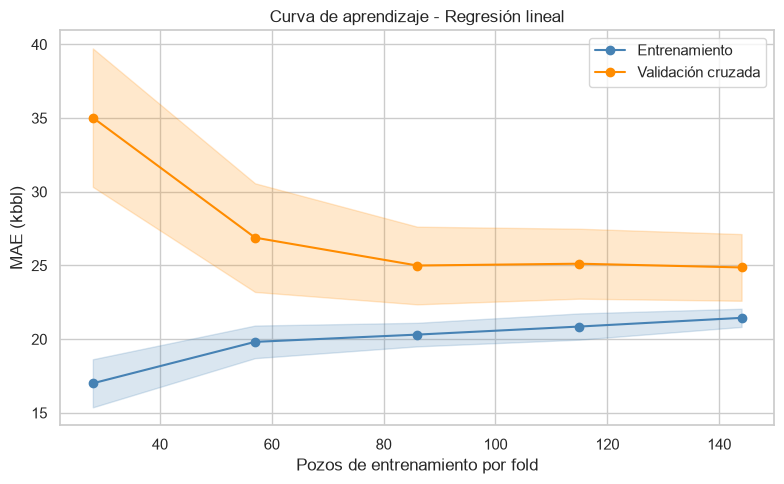

In [76]:
# %% BLOQUE 2 - Curva de aprendizaje
from sklearn.model_selection import learning_curve

tamanios = np.linspace(0.2, 1.0, 5)   # 20 %, 40 %, 60 %, 80 % y 100 % del entrenamiento de cada fold
tam_abs, train_sc, val_sc = learning_curve(
    modelo_lineal, X_train, y_train,
    train_sizes=tamanios, cv=cv5,
    scoring='neg_mean_absolute_error', shuffle=True, random_state=42,
)
mae_train = -train_sc.mean(axis=1); sd_train = train_sc.std(axis=1)
mae_val = -val_sc.mean(axis=1);     sd_val = val_sc.std(axis=1)

tabla_lc = pd.DataFrame({
    'pozos_entrenamiento': tam_abs,
    'MAE train': mae_train.round(2),
    'MAE validación': mae_val.round(2),
    'brecha': (mae_val - mae_train).round(2),
})
print(tabla_lc.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tam_abs, mae_train, 'o-', label='Entrenamiento', color='steelblue')
ax.fill_between(tam_abs, mae_train - sd_train, mae_train + sd_train, color='steelblue', alpha=0.2)
ax.plot(tam_abs, mae_val, 'o-', label='Validación cruzada', color='darkorange')
ax.fill_between(tam_abs, mae_val - sd_val, mae_val + sd_val, color='darkorange', alpha=0.2)
ax.set_xlabel('Pozos de entrenamiento por fold')
ax.set_ylabel('MAE (kbbl)')
ax.set_title('Curva de aprendizaje - Regresión lineal')
ax.legend()
plt.tight_layout(); plt.show()

#### Learning Curve
La curva de aprendizaje muestra cómo cambia el error de entrenamiento y el de validación a medida que aumenta la cantidad de datos. Si ambas curvas convergen en un valor alto, el modelo está subajustado (sesgo alto): no alcanza para captar la relación. Si el error de entrenamiento es bajo y el de validación queda lejos, hay sobreajuste (varianza alta). Más datos ayudan sobre todo en el segundo caso.

---

#### Resultado
Con pocos pozos (28 por fold), el modelo memoriza bien el entrenamiento (MAE de 17,0 kbbl) pero generaliza mal (35,0 kbbl), con una brecha de 18 kbbl. A medida que crece el entrenamiento, el error de entrenamiento sube (21,4 kbbl con 144 pozos) y el de validación baja hasta estabilizarse cerca de 25 kbbl. Con 144 pozos la brecha es de 3,4 kbbl y las dos curvas se acercan.

---

#### Lectura de la curva
El modelo lineal tiene poca varianza: a partir de unos 100 pozos por fold el error de validación deja de mejorar, lo que sugiere que agregar datos aporta poco y que el límite está en la información disponible (sesgo) más que en la cantidad de muestra. Esto es un punto de comparación para el resto de los modelos del punto 11: si un árbol se comporta distinto, con brechas grandes que no se cierran, eso confirmaría un problema de varianza. Los desvíos son grandes con 28 pozos, así que la estimación inicial es poco confiable.

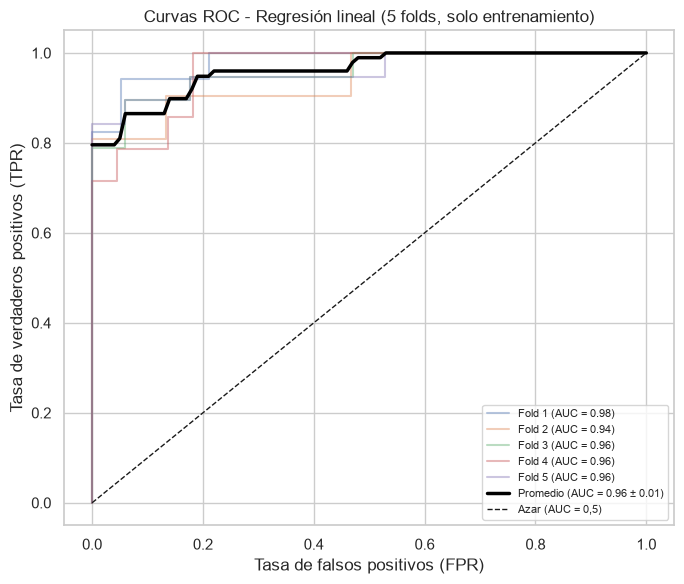

AUC por fold: [0.981 0.943 0.96  0.961 0.96 ]
AUC promedio: 0.961 ± 0.012


In [42]:
# %% BLOQUE 3 - Curvas ROC y AUC 
from sklearn.metrics import roc_curve, roc_auc_score

# Para usar ROC hay que binarizar la producción:
# "alta" = 210d_kbbl por encima de la mediana del fold de entrenamiento.
# La predicción continua se usa como puntaje: el AUC mide si el modelo ordena bien los pozos.
fig, ax = plt.subplots(figsize=(7, 6))
aucs = []
fpr_grid = np.linspace(0, 1, 101)
tprs = []

for i, (idx_tr, idx_val) in enumerate(cv5.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

    umbral = y_tr.median()                 # umbral calculado solo con el fold de entrenamiento
    etiqueta_val = (y_val > umbral).astype(int)

    modelo_fold = clone(modelo_lineal).fit(X_tr, y_tr)
    puntaje = modelo_fold.predict(X_val)   # predicción continua usada como puntaje

    fpr, tpr, _ = roc_curve(etiqueta_val, puntaje)
    auc_fold = roc_auc_score(etiqueta_val, puntaje)
    aucs.append(auc_fold)
    ax.plot(fpr, tpr, alpha=0.4, label=f'Fold {i} (AUC = {auc_fold:.2f})')
    tprs.append(np.interp(fpr_grid, fpr, tpr))

tpr_media = np.mean(tprs, axis=0); tpr_media[-1] = 1.0
ax.plot(fpr_grid, tpr_media, color='black', lw=2.5,
        label=f'Promedio (AUC = {np.mean(aucs):.2f} ± {np.std(aucs):.2f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0,5)')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR)')
ax.set_title('Curvas ROC - Regresión lineal (5 folds, solo entrenamiento)')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

print("AUC por fold:", np.round(aucs, 3))
print(f"AUC promedio: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

#### Curva ROC y AUC
La curva ROC muestra, para cada umbral de decisión, la tasa de verdaderos positivos (pozos de alta producción detectados) frente a la tasa de falsos positivos (pozos de baja producción marcados como altos). El AUC es el área bajo esa curva y puede interpretarse como la probabilidad de que un pozo de alta producción reciba un puntaje mayor que uno de baja producción elegido al azar. Un AUC de 0,5 equivale a azar y 1,0 a ordenamiento perfecto.

---

#### Decisiones: 
La producción es continua, así que la clase “alta” se define con la mediana del entrenamiento de cada fold. Ese umbral se calcula sin mirar la validación, para evitar fuga de información. La predicción continua funciona como puntaje, sin necesidad de un umbral de decisión adicional. Como el AUC depende de cómo se binariza la variable, es una evaluación complementaria: no reemplaza a MAE, RMSE ni R².

---

#### Resultado. 
El AUC promedio es de 0,961 ± 0,012, con valores entre 0,943 y 0,981 según el fold. Las cinco curvas están muy por encima de la diagonal de azar y son similares entre sí.


### 11.2 - Regresion Lineal: Hiperparametros (Regresion Ridge) y validacion 5fold

In [43]:
# BLOQUE 1 - Tres configuraciones de Ridge (regresión lineal regularizada)
from sklearn.linear_model import Ridge

# Las tres configuraciones se fijan antes de evaluarlas, en escala logarítmica:
# alpha muy chico (casi regresión lineal ordinaria), intermedio y fuerte.
configuraciones_ridge = {
    'Ridge alpha=0.1 (casi OLS)': 0.1,
    'Ridge alpha=10 (intermedia)': 10.0,
    'Ridge alpha=1000 (fuerte)': 1000.0,
}

# Cada configuración usa su propia copia del preprocesamiento dentro del Pipeline
modelos_ridge = {
    nombre: Pipeline([
        ('preprocesamiento', clone(preprocesador)),
        ('ridge', Ridge(alpha=alpha)),
    ])
    for nombre, alpha in configuraciones_ridge.items()
}

tabla_config = pd.DataFrame({
    'alpha': list(configuraciones_ridge.values()),
    'penalización': ['muy baja', 'media', 'alta'],
}, index=list(configuraciones_ridge.keys()))
print(tabla_config.to_string())

                              alpha penalización
Ridge alpha=0.1 (casi OLS)      0.1     muy baja
Ridge alpha=10 (intermedia)    10.0        media
Ridge alpha=1000 (fuerte)    1000.0         alta


#### ¿Por qué estas tres configuraciones?

La regresión Ridge agrega a la suma de errores cuadrados una penalización alpha · Σβj² sobre los coeficientes. Cuanto mayor es alpha, más se encogen los coeficientes hacia cero y más simple es el modelo. Con alpha = 0 se obtiene la regresión lineal ordinaria.

Elegí tres valores antes de evaluarlos, separados por órdenes de magnitud, para cubrir extremos y un punto intermedio:

alpha = 0,1: penalización casi nula. Sirve como control: si se parece a la regresión lineal, la penalización no está cambiando nada.
alpha = 10: penalización moderada. Es la configuración que más puede reducir la varianza sin perder demasiada información.
alpha = 1000: penalización fuerte. Sirve para ver el extremo opuesto: el modelo queda subajustado.

Las tres configuraciones permiten leer la curva completa de complejidad, desde sobreajuste potencial hasta subajuste. Usar valores en escala logarítmica es habitual porque el efecto de alpha es multiplicativo, no lineal.

Un detalle importante: como la penalización depende de la escala de las variables, el escalado va dentro del Pipeline, así cada fold escala con sus propios datos.

In [77]:
# BLOQUE 2 - Validación cruzada de 5 folds para las tres configuraciones

cv5 = KFold(n_splits=5, shuffle=True, random_state=42)   # mismos folds que en el resto del notebook
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

# La regresión lineal de referencia (bloque 1 del punto 11.1) se compara con las tres configuraciones
modelos_comparados = {'Regresión lineal (referencia)': modelo_lineal, **modelos_ridge}
resultados_lineal = {}
detalle_folds = {}

for nombre, modelo in modelos_comparados.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv5,
                         scoring=scoring, return_train_score=True)
    resultados_lineal[nombre] = {
        'MAE train': -res['train_mae'].mean(),
        'MAE CV (media)': -res['test_mae'].mean(),
        'MAE CV (desvío)': res['test_mae'].std(),
        'RMSE CV (media)': -res['test_rmse'].mean(),
        'RMSE CV (desvío)': res['test_rmse'].std(),
        'R² CV (media)': res['test_r2'].mean(),
        'R² CV (desvío)': res['test_r2'].std(),
    }
    detalle_folds[nombre] = -res['test_mae']   # MAE de cada uno de los 5 folds

tabla_lineal = pd.DataFrame(resultados_lineal).T
tabla_lineal['Brecha (CV - train)'] = tabla_lineal['MAE CV (media)'] - tabla_lineal['MAE train']
print("Validación cruzada 5 folds (solo entrenamiento, 180 pozos):")
print(tabla_lineal.round(2).to_string())

print("\nMAE por fold (kbbl):")
print(pd.DataFrame(detalle_folds, index=[f'Fold {i}' for i in range(1, 6)]).T.round(2).to_string())

mejor = tabla_lineal['MAE CV (media)'].idxmin()
print(f"\nMenor MAE medio en CV: {mejor}")

Validación cruzada 5 folds (solo entrenamiento, 180 pozos):
                               MAE train  MAE CV (media)  MAE CV (desvío)  RMSE CV (media)  RMSE CV (desvío)  R² CV (media)  R² CV (desvío)  Brecha (CV - train)
Regresión lineal (referencia)      21.45           24.87             2.26            29.75              2.73           0.76            0.06                 3.42
Ridge alpha=0.1 (casi OLS)         21.45           24.85             2.25            29.73              2.71           0.76            0.06                 3.40
Ridge alpha=10 (intermedia)        21.79           24.06             1.72            29.01              1.98           0.78            0.04                 2.28
Ridge alpha=1000 (fuerte)          41.61           41.92             3.54            49.28              3.45           0.37            0.03                 0.32

MAE por fold (kbbl):
                               Fold 1  Fold 2  Fold 3  Fold 4  Fold 5
Regresión lineal (referencia)   21.52   26.

#### Explicacion de validacion cruzada 

Qué es la validación cruzada de 5 folds. Los 180 pozos de entrenamiento se dividen en cinco grupos de tamaño parecido. En cada una de las cinco iteraciones, cuatro grupos (unos 144 pozos) entrenan el modelo y el grupo restante (unos 36 pozos) lo evalúa. Así, cada pozo se usa para validar exactamente una vez. Al final se promedian las cinco métricas (media) y se calcula su dispersión (desvío).

Por qué es bueno hacerla? Con una sola partición, el resultado depende de qué pozos quedaron en validación: con 180 pozos, cambiar unos pocos puede modificar mucho el error. Promediar cinco particiones da una estimación más estable, y el desvío entre folds informa cuán sensible es el modelo a los datos que recibe. Además, permite comparar modelos con los mismos folds, de modo que la diferencia se debe al modelo y no a la partición.

---

#### Resultados.
La configuración con alpha = 10 tiene el menor MAE medio: 24,06 ± 1,72 kbbl, frente a 24,87 ± 2,26 kbbl de la regresión lineal. El RMSE baja de 29,75 a 29,01 kbbl y el R² sube de 0,76 a 0,78. Además, la dispersión entre folds es menor.

----

#### Lectura
La mejora es de unos 0,8 kbbl, que es menos que el desvío de cualquiera de las dos. Por fold, alpha = 10 mejora claramente en los folds 4 y 5 (25,26 y 23,61 kbbl frente a 27,56 y 25,53) y es igual o levemente peor en el 1. Por lo tanto, la ventaja no es consistente en todos los folds, y no puede afirmarse de forma concluyente que Ridge sea mejor.


### 11.3 - Optimizacion de otros modelos

En los puntos anteriores se evaluo los modelos en datos de entrenamientos con hiperparametros seleccionados por mi. Sin embargo me surgio la siguiente duda ¿Es posible que la regresion lineal deje de ser nuestro modelo predilecto ante la optimizacion de hiperparametros de los modelos anteriores (Arbol de decision, Random Forest, XGBoost, LightGBM)?

La intencion de este apartado es eso. Optimizaremos hiperparametros, luego entrenaremos el modelo y finalmente tomaremos la desicion de que modelo seria mejor para nosotros.

#### 11.3.1 - Optimizacion de Arbol de Decision

In [45]:
#BLOQUE 1 - Optimización de hiperparámetros del árbol de decisión (GridSearchCV, solo entrenamiento)
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# Los árboles no necesitan escalado: las particiones no dependen de la escala de las variables
arbol_base = DecisionTreeRegressor(random_state=42)

# Grilla de búsqueda: profundidad máxima y tamaño mínimo de hoja
grilla_arbol = {
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_leaf': [3, 5, 10, 15, 20],
}

# GridSearchCV usa solo X_train/y_train y los 5 folds definidos en el punto 11
busqueda_arbol = GridSearchCV(
    estimator=arbol_base,
    param_grid=grilla_arbol,
    cv=cv5,
    scoring='neg_mean_absolute_error',   # maximizar -MAE = minimizar MAE
    n_jobs=-1,
    refit=True,                          # reentrena el mejor modelo con todo el entrenamiento
)
busqueda_arbol.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_arbol.best_params_)
print(f"MAE CV del mejor modelo (optimista: se eligió con estos mismos folds): "
      f"{-busqueda_arbol.best_score_:.2f} kbbl")

# Tabla de las 10 mejores combinaciones, ordenadas por MAE medio
resultados_grid = pd.DataFrame(busqueda_arbol.cv_results_)
tabla_grid_arbol = (
    resultados_grid[['param_max_depth', 'param_min_samples_leaf',
                     'mean_test_score', 'std_test_score']]
    .assign(**{'MAE CV (media)': lambda d: -d['mean_test_score'],
               'MAE CV (desvío)': lambda d: d['std_test_score']})
    .drop(columns=['mean_test_score', 'std_test_score'])
    .sort_values('MAE CV (media)')
    .head(10)
)
print("\nTop 10 combinaciones (menor MAE CV):")
print(tabla_grid_arbol.round(2).to_string(index=False))

Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 3}
MAE CV del mejor modelo (optimista: se eligió con estos mismos folds): 27.02 kbbl

Top 10 combinaciones (menor MAE CV):
param_max_depth  param_min_samples_leaf  MAE CV (media)  MAE CV (desvío)
              5                       3           27.02             2.38
              8                       3           27.25             1.46
              6                       3           27.29             2.82
           None                       3           27.40             1.10
              4                       3           27.66             2.51
              4                      10           27.99             1.80
              3                      10           28.03             1.60
              5                      10           28.20             1.13
              4                      15           28.22             1.73
              4                       5           28.26             3.25


#### GridSearchCV

GridSearchCV prueba todas las combinaciones de una grilla de hiperparámetros, evalúa cada una con validación cruzada y se queda con la que tiene menor error medio. Para el árbol, los dos hiperparámetros que más controlan la complejidad son max_depth (cuántos niveles de divisiones puede tener) y min_samples_leaf (cuántos pozos mínimos debe tener una hoja). Una profundidad grande o hojas pequeñas permiten memorizar el entrenamiento; restricciones muy fuertes llevan a subajuste.

---

#### Decisiones.
La grilla combina profundidades de 2 a 8 y sin límite, con hojas de 3 a 20 pozos. La búsqueda usa los mismos 5 folds del punto 11 y solo los 180 pozos de entrenamiento. El criterio es el MAE, la métrica principal de la consigna.

---

#### Resultado.
La mejor combinación es max_depth = 5 y min_samples_leaf = 3, con un MAE de 27,02 kbbl en validación cruzada. Ese número es optimista, porque el mismo conjunto de folds eligió la combinación. Para tener una estimación honesta hay que usar la validación anidada del bloque 2.


In [78]:
# BLOQUE 2 - Evaluación del árbol optimizado con validación cruzada 5 folds

# Validación cruzada anidada:
#   - externa (5 folds): estima el desempeño del PROCEDIMIENTO de optimización con datos no vistos
#   - interna (5 folds, dentro de cada fold externo): elige los hiperparámetros
# Así el número no queda inflado por haber elegido los hiperparámetros con esos mismos datos.

cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)  # folds externos distintos del interno
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

res_anidada = cross_validate(
    busqueda_arbol, X_train, y_train,
    cv=cv_externa, scoring=scoring, return_train_score=False,
)

resumen_arbol = pd.DataFrame({
    'Árbol optimizado (CV anidada 5x5)': {
        'MAE CV (media)': -res_anidada['test_mae'].mean(),
        'MAE CV (desvío)': res_anidada['test_mae'].std(),
        'RMSE CV (media)': -res_anidada['test_rmse'].mean(),
        'RMSE CV (desvío)': res_anidada['test_rmse'].std(),
        'R² CV (media)': res_anidada['test_r2'].mean(),
        'R² CV (desvío)': res_anidada['test_r2'].std(),
    }
}).T
print(resumen_arbol.round(2).to_string())

# Comparación con la regresión lineal y Ridge del punto 11.2 (mismo entrenamiento)
mae_lineal_ref = resultados_lineal['Regresión lineal (referencia)']['MAE CV (media)']
mae_ridge_ref = resultados_lineal['Ridge alpha=10 (intermedia)']['MAE CV (media)']
print(f"\nReferencia: regresión lineal MAE CV = {mae_lineal_ref:.2f} kbbl | "
      f"Ridge alpha=10 MAE CV = {mae_ridge_ref:.2f} kbbl")

# Entrenamiento final del árbol optimizado con todo el entrenamiento (la prueba sigue reservada)
arbol_final = busqueda_arbol.best_estimator_
print("\nÁrbol final entrenado con 180 pozos. Profundidad real:", arbol_final.get_depth(),
      "| hojas:", arbol_final.get_n_leaves())

                                   MAE CV (media)  MAE CV (desvío)  RMSE CV (media)  RMSE CV (desvío)  R² CV (media)  R² CV (desvío)
Árbol optimizado (CV anidada 5x5)           27.73             3.22            37.55              3.35           0.62            0.03

Referencia: regresión lineal MAE CV = 24.87 kbbl | Ridge alpha=10 MAE CV = 24.06 kbbl

Árbol final entrenado con 180 pozos. Profundidad real: 5 | hojas: 20


#### Validacion anidada
En la validación anidada hay dos niveles de folds. El externo (5 folds) mide el desempeño con pozos que no participaron en la elección de hiperparámetros. En cada fold externo, el interno (otra validación de 5 folds) busca la mejor combinación con los datos de ese fold de entrenamiento. Así se estima el error del procedimiento completo (buscar + entrenar), y no el de una combinación elegida con los mismos datos que después se evalúan.

Por qué es necesario? Si reportáramos los 27,02 kbbl del bloque 1 como desempeño, estaríamos midiendo sobre los mismos datos con los que elegimos. Ese número es optimista. La validación anidada es la forma de medir sin esa trampa.

#### Resultado
El MAE honesto del árbol optimizado es de 27,73 ± 3,22 kbbl, con R² de 0,62. Comparado con la regresión lineal (24,87 kbbl) y con Ridge alpha = 10 (24,06 kbbl), el árbol es peor y además más variable entre folds: el desvío de 3,22 kbbl es mayor que la diferencia con las alternativas lineales.

#### Lectura
La optimización no mejoró el árbol de manera significativa frente a la versión sin ajustar del punto 9 (24,35 kbbl), y sí lo hizo más inestable. Esto no significa que el árbol sea mala opción en general, sino que, con 36 pozos por fold de validación, cada partición cambia mucho el resultado. El desvío de los folds es parte de la respuesta: un modelo con desvío alto no es confiable con este tamaño de muestra.


 pozos_entrenamiento  MAE train  MAE validación  brecha
                  28      13.52           32.32   18.81
                  57      10.79           32.59   21.79
                  86      11.41           27.71   16.30
                 115      11.67           26.46   14.79
                 144      13.50           27.02   13.51


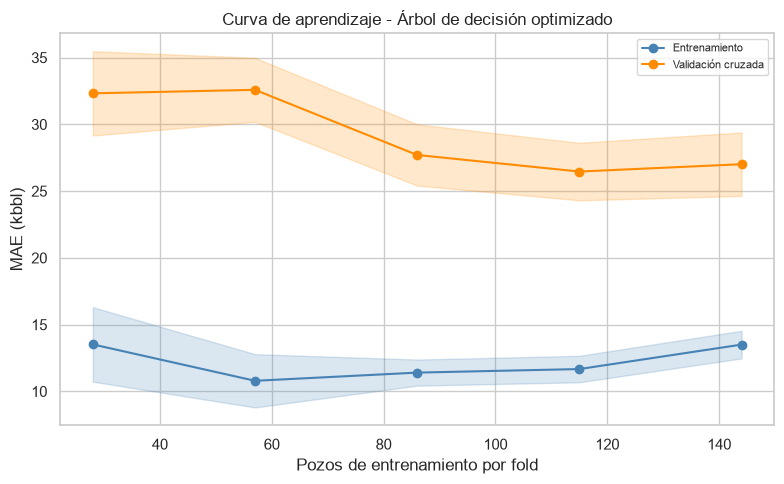

In [47]:
#BLOQUE 3 - Curva de aprendizaje del árbol optimizado (sobreajuste o subajuste)
from sklearn.model_selection import learning_curve

tamanios = np.linspace(0.2, 1.0, 5)   # 20 %, 40 %, 60 %, 80 % y 100 % del entrenamiento de cada fold
tam_abs, train_sc, val_sc = learning_curve(
    arbol_final, X_train, y_train,
    train_sizes=tamanios, cv=cv5,
    scoring='neg_mean_absolute_error', shuffle=True, random_state=42,
)
mae_train = -train_sc.mean(axis=1); sd_train = train_sc.std(axis=1)
mae_val = -val_sc.mean(axis=1);     sd_val = val_sc.std(axis=1)

tabla_lc_arbol = pd.DataFrame({
    'pozos_entrenamiento': tam_abs,
    'MAE train': mae_train.round(2),
    'MAE validación': mae_val.round(2),
    'brecha': (mae_val - mae_train).round(2),
})
print(tabla_lc_arbol.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tam_abs, mae_train, 'o-', label='Entrenamiento', color='steelblue')
ax.fill_between(tam_abs, mae_train - sd_train, mae_train + sd_train, color='steelblue', alpha=0.2)
ax.plot(tam_abs, mae_val, 'o-', label='Validación cruzada', color='darkorange')
ax.fill_between(tam_abs, mae_val - sd_val, mae_val + sd_val, color='darkorange', alpha=0.2)
ax.set_xlabel('Pozos de entrenamiento por fold')
ax.set_ylabel('MAE (kbbl)')
ax.set_title('Curva de aprendizaje - Árbol de decisión optimizado')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

La curva de aprendizaje compara el error de entrenamiento con el de validación al variar la cantidad de datos. Si la brecha es grande y no se cierra al agregar pozos, el modelo tiene varianza alta (sobreajuste): memoriza el entrenamiento y no generaliza. Si ambas curvas convergen en un error alto, tiene sesgo alto (subajuste).

---

#### Resultado
Resultado Con 144 pozos, el error de entrenamiento es de 13,5 kbbl y el de validación de 27,0 kbbl. La brecha es de 13,5 kbbl, frente a 3,4 kbbl de la regresión lineal. Además, la brecha se reduce muy poco al aumentar los datos (de 18,8 kbbl con 28 pozos a 13,5 kbbl con 144), y el error de validación casi no baja a partir de unos 115 pozos. El modelo está claramente sobreajustado.

--- 
#### Lectura
La optimización de max_depth y min_samples_leaf redujo la complejidad, pero no alcanzó para eliminar la varianza. El árbol con 5 niveles y 20 hojas sigue aprendiendo particularidades de cada conjunto de entrenamiento. Con 180 pozos y 13 predictoras, el árbol individual tiende a ser inestable, y eso se refleja en el desvío de 3 kbbl del bloque 2. La curva también indica que agregar datos ayudaría poco: el error de validación se estabiliza.



#### 11.3.2 - Optimizacion Random Forest

In [48]:
# BLOQUE 1 - Optimización de hiperparámetros de random forest (GridSearchCV, solo entrenamiento)

# Random forest: los árboles no necesitan escalado, así que el modelo va directo.
# n_estimators se fija en 200
bosque_base = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)

# Grilla: profundidad, tamaño mínimo de hoja y proporción de variables por árbol
grilla_rf = {
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [3, 5, 10, 15],
    'max_features': [0.33, 0.5, 1.0],
}

busqueda_rf = GridSearchCV(
    estimator=bosque_base,
    param_grid=grilla_rf,
    cv=cv5,                              # mismos 5 folds del punto 11
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    refit=True,                          # reentrena el mejor modelo con todo el entrenamiento
)
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print(f"MAE CV del mejor modelo (optimista: se eligió con estos mismos folds): "
      f"{-busqueda_rf.best_score_:.2f} kbbl")

resultados_grid_rf = pd.DataFrame(busqueda_rf.cv_results_)
tabla_grid_rf = (
    resultados_grid_rf[['param_max_depth', 'param_min_samples_leaf', 'param_max_features',
                        'mean_test_score', 'std_test_score']]
    .assign(**{'MAE CV (media)': lambda d: -d['mean_test_score'],
               'MAE CV (desvío)': lambda d: d['std_test_score']})
    .drop(columns=['mean_test_score', 'std_test_score'])
    .sort_values('MAE CV (media)')
    .head(10)
)
print("\nTop 10 combinaciones (menor MAE CV):")
print(tabla_grid_rf.round(2).to_string(index=False))

Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}
MAE CV del mejor modelo (optimista: se eligió con estos mismos folds): 22.95 kbbl

Top 10 combinaciones (menor MAE CV):
param_max_depth  param_min_samples_leaf  param_max_features  MAE CV (media)  MAE CV (desvío)
           None                       3                0.50           22.95             1.30
              8                       3                0.50           23.00             1.25
              5                       3                0.50           23.02             1.25
           None                       3                1.00           23.03             1.02
              5                       3                1.00           23.06             1.06
              8                       3                1.00           23.08             1.03
              5                       5                0.50           23.23             1.40
              8                       3        

Random forest promedia muchos árboles, cada uno entrenado con una muestra bootstrap de los pozos y con un subconjunto aleatorio de variables en cada corte. Eso reduce la varianza del árbol individual. Por eso, a diferencia del árbol simple, el hiperparámetro max_features aparece en la grilla: controla cuántas variables se evalúan en cada división, y cuanto menor es, más diversos son los árboles y más se descorrelacionan sus errores.

---

###### Decisiones
Fijé n_estimators = 200 porque, en bagging, a partir de cierta cantidad de árboles la mejora es marginal. Busqué max_depth, min_samples_leaf y max_features. Usé los mismos 5 folds y solo los 180 pozos de entrenamiento.

---

###### Resultado
La mejor combinación es sin límite de profundidad, min_samples_leaf = 3 y max_features = 0.5, con un MAE de 22,95 kbbl. Como en el árbol, ese número es optimista porque los mismos folds eligieron la combinación. La validación anidada del bloque 2 da la estimación honesta.

Las diez mejores combinaciones están entre 22,95 y 23,32 kbbl, con desvíos de 0,8 a 1,4 kbbl. La superficie es muy plana: la diferencia entre la mejor y la décima es de unos 0,4 kbbl, menor que cualquier desvío. Esto importa para la decisión final: no hay una configuración que se destaque claramente, y la elección es poco sensible a los hiperparámetros dentro de este rango. Además, aparecen valores pequeños de min_samples_leaf (3 y 5), en línea con lo que vimos en el árbol simple.

In [49]:
#BLOQUE 2 - Evaluación del random forest optimizado con validación cruzada 5 folds (anidada)
from sklearn.model_selection import cross_validate, KFold

# Validación anidada: el externo estima el desempeño del procedimiento (buscar + entrenar)
# con pozos que no participaron en la elección; el interno elige los hiperparámetros.
cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

res_rf_anidada = cross_validate(
    busqueda_rf, X_train, y_train,
    cv=cv_externa, scoring=scoring, return_train_score=False,
)

resumen_rf = pd.DataFrame({
    'Random forest optimizado (CV anidada 5x5)': {
        'MAE CV (media)': -res_rf_anidada['test_mae'].mean(),
        'MAE CV (desvío)': res_rf_anidada['test_mae'].std(),
        'RMSE CV (media)': -res_rf_anidada['test_rmse'].mean(),
        'RMSE CV (desvío)': res_rf_anidada['test_rmse'].std(),
        'R² CV (media)': res_rf_anidada['test_r2'].mean(),
        'R² CV (desvío)': res_rf_anidada['test_r2'].std(),
    }
}).T
print(resumen_rf.round(2).to_string())

# Referencias del mismo entrenamiento
print(f"\nReferencia: regresión lineal MAE CV = {mae_lineal_ref:.2f} kbbl | "
      f"Ridge alpha=10 MAE CV = {mae_ridge_ref:.2f} kbbl | "
      f"Árbol optimizado (anidada) MAE CV = {-res_anidada['test_mae'].mean():.2f} kbbl")

rf_final = busqueda_rf.best_estimator_
print("\nRandom forest final entrenado con 180 pozos. Profundidad máxima real:",
      max(e.get_depth() for e in rf_final.estimators_))

                                           MAE CV (media)  MAE CV (desvío)  RMSE CV (media)  RMSE CV (desvío)  R² CV (media)  R² CV (desvío)
Random forest optimizado (CV anidada 5x5)           22.08             2.02            28.96              2.32           0.77            0.03

Referencia: regresión lineal MAE CV = 24.87 kbbl | Ridge alpha=10 MAE CV = 24.06 kbbl | Árbol optimizado (anidada) MAE CV = 27.73 kbbl

Random forest final entrenado con 180 pozos. Profundidad máxima real: 13


Con la validación anidada, el random forest optimizado tiene un MAE de 22,08 ± 2,02 kbbl, un RMSE de 28,96 ± 2,32 kbbl y un R² de 0,77 ± 0,03. Es la estimación honesta: los pozos de validación externa no participaron en la búsqueda de hiperparámetros.

---

##### Comparación
Frente a la regresión lineal (24,87 kbbl) y al árbol optimizado (27,73 kbbl), random forest tiene el menor error medio en este entrenamiento. La diferencia con la lineal es de unos 2,8 kbbl, mayor que el desvío de cualquiera de los dos. El árbol simple quedó claramente atrás, lo que confirma que el promedio de árboles reduce la inestabilidad que vimos en el bloque anterior.


 pozos_entrenamiento  MAE train  MAE validación  brecha
                  28      16.20           26.95   10.75
                  57      15.03           24.84    9.80
                  86      13.66           23.49    9.83
                 115      12.67           23.40   10.73
                 144      12.57           22.79   10.21


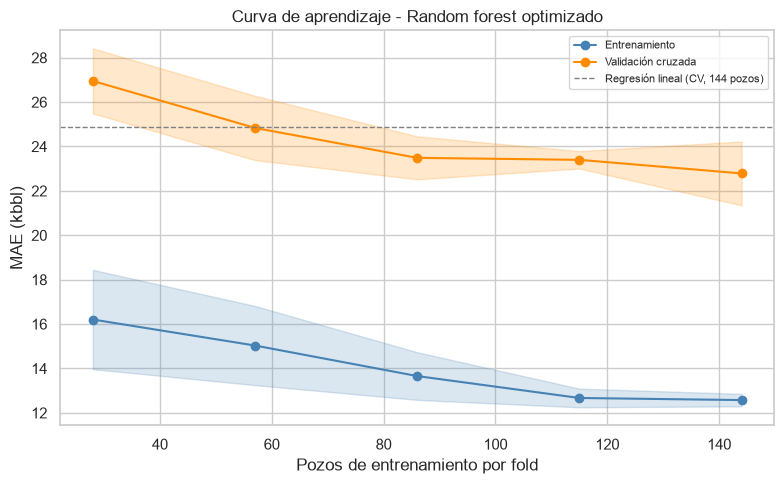

In [50]:
#BLOQUE 3 - Curva de aprendizaje del random forest optimizado
from sklearn.model_selection import learning_curve

tamanios = np.linspace(0.2, 1.0, 5)
tam_abs, train_sc, val_sc = learning_curve(
    rf_final, X_train, y_train,
    train_sizes=tamanios, cv=cv5,
    scoring='neg_mean_absolute_error', shuffle=True, random_state=42,
)
mae_train = -train_sc.mean(axis=1); sd_train = train_sc.std(axis=1)
mae_val = -val_sc.mean(axis=1);     sd_val = val_sc.std(axis=1)

tabla_lc_rf = pd.DataFrame({
    'pozos_entrenamiento': tam_abs,
    'MAE train': mae_train.round(2),
    'MAE validación': mae_val.round(2),
    'brecha': (mae_val - mae_train).round(2),
})
print(tabla_lc_rf.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tam_abs, mae_train, 'o-', label='Entrenamiento', color='steelblue')
ax.fill_between(tam_abs, mae_train - sd_train, mae_train + sd_train, color='steelblue', alpha=0.2)
ax.plot(tam_abs, mae_val, 'o-', label='Validación cruzada', color='darkorange')
ax.fill_between(tam_abs, mae_val - sd_val, mae_val + sd_val, color='darkorange', alpha=0.2)
ax.axhline(mae_lineal_ref, color='gray', ls='--', lw=1, label='Regresión lineal (CV, 144 pozos)')
ax.set_xlabel('Pozos de entrenamiento por fold')
ax.set_ylabel('MAE (kbbl)')
ax.set_title('Curva de aprendizaje - Random forest optimizado')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Con 144 pozos, el error de entrenamiento es de 12,6 kbbl y el de validación de 22,8 kbbl. La brecha es de unos 10 kbbl, mayor que la de la regresión lineal (3,4 kbbl), pero menor que la del árbol simple (13,5 kbbl). La validación mejora de forma sostenida: baja de 27,0 kbbl con 28 pozos a 22,8 con 144, y todavía no se estabiliza del todo.

La brecha no se cierra, así que el modelo sigue teniendo varianza alta: aprende bastante del entrenamiento, pero no todo se generaliza. Sin embargo, el error de validación es menor que el del árbol y que el de la regresión lineal en el tramo final, lo que indica que el promedio de árboles aporta capacidad predictiva real y no solo ruido. Como la curva sigue bajando, agregar datos mejoraría el resultado más que en la regresión lineal, cuya curva ya estaba casi plana.

Random forest es el primer modelo de esta sección que mejora el error de validación de la regresión lineal de forma consistente en la validación anidada.

#### 11.3.3 - Optimizacion XGBoost

In [51]:
# %% BLOQUE 1 - Optimización de hiperparámetros de XGBoost con Optuna (solo entrenamiento)
import optuna
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 60   # número de combinaciones que prueba Optuna; se fija antes de ejecutar

def objetivo_xgb(trial):
    """Función a minimizar: MAE medio en validación cruzada 5 folds sobre el entrenamiento."""
    params = {
        'max_depth': trial.suggest_int('max_depth', 2, 5),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 400, step=50),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
    }
    modelo = XGBRegressor(**params, random_state=42, n_jobs=-1, verbosity=0)
    scores = cross_val_score(modelo, X_train, y_train, cv=cv5,
                             scoring='neg_mean_absolute_error')
    return -scores.mean()

# TPE: muestreador bayesiano que usa los resultados previos para elegir los siguientes ensayos
estudio_xgb = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)
estudio_xgb.optimize(objetivo_xgb, n_trials=N_TRIALS)

print("Mejores hiperparámetros:", estudio_xgb.best_params)
print(f"MAE CV de la mejor combinación (optimista: se eligió con estos mismos folds): "
      f"{estudio_xgb.best_value:.2f} kbbl")

top_xgb = (
    estudio_xgb.trials_dataframe()
    .assign(**{'MAE CV (media)': lambda d: d['value']})
    .sort_values('MAE CV (media)')
    .head(10)
    [['MAE CV (media)', 'params_max_depth', 'params_learning_rate', 'params_n_estimators',
      'params_min_child_weight', 'params_subsample', 'params_colsample_bytree',
      'params_reg_lambda']]
)
print("\nTop 10 ensayos (menor MAE CV):")
print(top_xgb.round(3).to_string(index=False))

c:\Users\Alam\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mejores hiperparámetros: {'max_depth': 2, 'learning_rate': 0.02535636620123447, 'n_estimators': 350, 'min_child_weight': 3, 'subsample': 0.747479121523895, 'colsample_bytree': 0.907281583701623, 'reg_lambda': 4.605195386763916}
MAE CV de la mejor combinación (optimista: se eligió con estos mismos folds): 22.28 kbbl

Top 10 ensayos (menor MAE CV):
 MAE CV (media)  params_max_depth  params_learning_rate  params_n_estimators  params_min_child_weight  params_subsample  params_colsample_bytree  params_reg_lambda
         22.280                 2                 0.025                  350                        3             0.747                    0.907              4.605
         22.309                 2                 0.026                  350                        3             0.762                    0.912              6.359
         22.321                 2                 0.033                  400                        8             0.783                    0.892              9

Optuna es un marco de optimización de hiperparámetros. Cada ensayo propone una combinación, la evalúa con validación cruzada y registra el resultado. El muestreador TPE usa los ensayos anteriores para decidir dónde buscar: concentra los ensayos en las zonas que dieron buen error y explora menos las que dieron malo. Con siete hiperparámetros, esto es más eficiente que una grilla completa, que crecería de forma exponencial.

##### Decisiones
Fijé 60 ensayos y un rango para cada hiperparámetro antes de ejecutar: profundidad de 2 a 5, tasa de aprendizaje de 0,01 a 0,2 en escala logarítmica, de 50 a 400 árboles, peso mínimo por hoja de 1 a 15, submuestreo de pozos y de variables entre 0,6 y 1, y penalización L2 entre 0,1 y 10. La semilla del muestreador es fija, así que el resultado es reproducible.

##### Resultado. 
La mejor combinación es profundidad 2, tasa de aprendizaje 0,025, 350 árboles, peso mínimo 3, submuestreo de pozos 0,75, de variables 0,91 y penalización L2 de 4,6. Su MAE en validación cruzada es de 22,28 kbbl.



In [52]:
#BLOQUE 2 - Evaluación de XGBoost optimizado con Optuna: validación anidada 5x5
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def optimizar_fold(X_tr, y_tr, n_trials):
    """Optimiza XGBoost con Optuna usando solo el entrenamiento del fold externo."""
    def objetivo(trial):
        params = {
            'max_depth': trial.suggest_int('max_depth', 2, 5),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'n_estimators': trial.suggest_int('n_estimators', 50, 400, step=50),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        }
        modelo = XGBRegressor(**params, random_state=42, n_jobs=-1, verbosity=0)
        scores = cross_val_score(modelo, X_tr, y_tr, cv=cv5,
                                 scoring='neg_mean_absolute_error')
        return -scores.mean()

    estudio = optuna.create_study(direction='minimize',
                                  sampler=optuna.samplers.TPESampler(seed=42))
    estudio.optimize(objetivo, n_trials=n_trials)
    return XGBRegressor(**estudio.best_params, random_state=42, n_jobs=-1, verbosity=0)

# Validación externa: cada fold evalúa el procedimiento completo (optimizar + entrenar)
cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)
filas_anidadas = []
for i, (idx_tr, idx_val) in enumerate(cv_externa.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

    modelo_fold = optimizar_fold(X_tr, y_tr, n_trials=N_TRIALS)
    modelo_fold.fit(X_tr, y_tr)
    pred = modelo_fold.predict(X_val)

    filas_anidadas.append({
        'Fold': i,
        'MAE': mean_absolute_error(y_val, pred),
        'RMSE': np.sqrt(mean_squared_error(y_val, pred)),
        'R²': r2_score(y_val, pred),
    })

tabla_xgb_anidada = pd.DataFrame(filas_anidadas)
print(tabla_xgb_anidada.round(3).to_string(index=False))

resumen_xgb = pd.DataFrame({
    'XGBoost optimizado con Optuna (CV anidada 5x5)': {
        'MAE CV (media)': tabla_xgb_anidada['MAE'].mean(),
        'MAE CV (desvío)': tabla_xgb_anidada['MAE'].std(),
        'RMSE CV (media)': tabla_xgb_anidada['RMSE'].mean(),
        'RMSE CV (desvío)': tabla_xgb_anidada['RMSE'].std(),
        'R² CV (media)': tabla_xgb_anidada['R²'].mean(),
        'R² CV (desvío)': tabla_xgb_anidada['R²'].std(),
    }
}).T
print("\n" + resumen_xgb.round(2).to_string())

# Modelo final: reentrenado con todo el entrenamiento y con la mejor combinación del bloque 1
xgb_final = XGBRegressor(**estudio_xgb.best_params, random_state=42, n_jobs=-1, verbosity=0)
xgb_final.fit(X_train, y_train)

 Fold    MAE   RMSE    R²
    1 18.214 26.483 0.801
    2 23.987 30.628 0.775
    3 23.625 31.128 0.778
    4 24.358 31.040 0.730
    5 19.296 25.207 0.789

                                                MAE CV (media)  MAE CV (desvío)  RMSE CV (media)  RMSE CV (desvío)  R² CV (media)  R² CV (desvío)
XGBoost optimizado con Optuna (CV anidada 5x5)            21.9              2.9             28.9              2.83           0.77            0.03


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.907281583701623
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


En la validación anidada, cada fold externo se usa como validación una sola vez, y el procedimiento completo (buscar con Optuna y entrenar) se ejecuta con los datos de los otros cuatro folds. Así el error que medimos corresponde a pozos que nunca participaron en la elección de hiperparámetros, a diferencia del 22,28 kbbl del bloque 1.

El resultado es prácticamente idéntico al de random forest optimizado con grilla (22,08 ± 2,02 kbbl). La diferencia de 0,2 kbbl está muy por debajo de cualquiera de los desvíos. XGBoost tiene el menor promedio, pero random forest tiene menor dispersión entre folds. Ambos superan la regresión lineal (24,87 kbbl), aunque esa cifra es de la validación simple del punto 11.2 y no es estrictamente comparable. La dispersión entre folds, de casi 6 kbbl entre el mejor y el peor, muestra que el resultado depende mucho de qué pozos quedan en cada validación.


 pozos_entrenamiento  MAE train  MAE validación  brecha
                  28       5.52           27.07   21.55
                  57       8.04           23.86   15.81
                  86       9.59           22.31   12.72
                 115      10.66           22.58   11.92
                 144      12.06           22.42   10.36


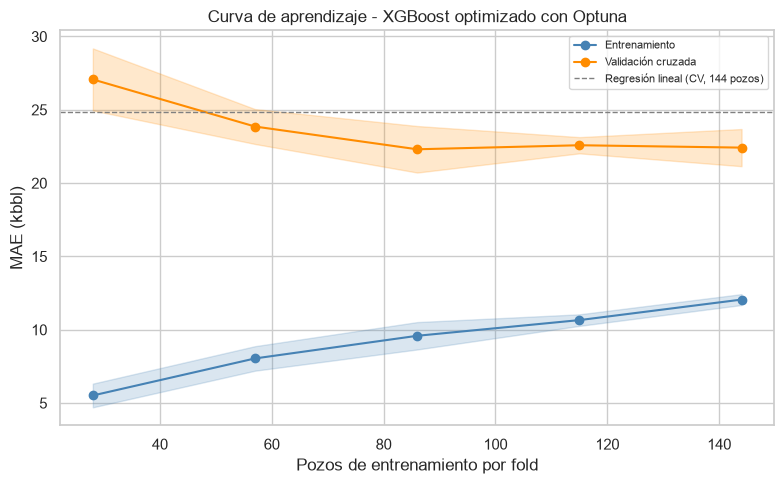

In [53]:
# BLOQUE 3 - Curva de aprendizaje de XGBoost optimizado
from sklearn.model_selection import learning_curve

tamanios = np.linspace(0.2, 1.0, 5)
tam_abs, train_sc, val_sc = learning_curve(
    xgb_final, X_train, y_train,
    train_sizes=tamanios, cv=cv5,
    scoring='neg_mean_absolute_error', shuffle=True, random_state=42,
)
mae_train = -train_sc.mean(axis=1); sd_train = train_sc.std(axis=1)
mae_val = -val_sc.mean(axis=1);     sd_val = val_sc.std(axis=1)

tabla_lc_xgb = pd.DataFrame({
    'pozos_entrenamiento': tam_abs,
    'MAE train': mae_train.round(2),
    'MAE validación': mae_val.round(2),
    'brecha': (mae_val - mae_train).round(2),
})
print(tabla_lc_xgb.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tam_abs, mae_train, 'o-', label='Entrenamiento', color='steelblue')
ax.fill_between(tam_abs, mae_train - sd_train, mae_train + sd_train, color='steelblue', alpha=0.2)
ax.plot(tam_abs, mae_val, 'o-', label='Validación cruzada', color='darkorange')
ax.fill_between(tam_abs, mae_val - sd_val, mae_val + sd_val, color='darkorange', alpha=0.2)
ax.axhline(mae_lineal_ref, color='gray', ls='--', lw=1, label='Regresión lineal (CV, 144 pozos)')
ax.set_xlabel('Pozos de entrenamiento por fold')
ax.set_ylabel('MAE (kbbl)')
ax.set_title('Curva de aprendizaje - XGBoost optimizado con Optuna')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Como en los bloques anteriores, comparamos el error de entrenamiento con el de validación al variar la cantidad de pozos. Una brecha que no se cierra indica varianza alta. Dos curvas que se estabilizan en un error alto indican que más datos ya no ayudan.

Con 28 pozos por fold, el error de entrenamiento es de 5,5 kbbl y el de validación de 27,1 kbbl, una brecha de 21,6 kbbl. Con 144 pozos, la brecha baja a 10,4 kbbl: el error de entrenamiento sube a 12,1 y el de validación baja a 22,4 kbbl. La validación ya está prácticamente estable desde unos 86 pozos, entre 22,3 y 22,6 kbbl

El modelo sigue sobreajustado: aprende muy bien el entrenamiento, con 5 a 12 kbbl de error, pero la generalización no alcanza ese nivel. Sin embargo, la mejora del error de validación tiene un límite: a partir de unos 90 pozos, agregar datos no reduce el error. Comparado con random forest, la brecha final es algo menor (10,4 frente a 10,2, prácticamente igual) y el error de validación también (22,4 frente a 22,8), por lo que las dos curvas son muy parecidas.

#### 11.3.4 - Comparamos nuevamente Ridge

A pesar de haber entrenado ridge anteriormente decido hacerlo de nuevo con la misma familia y metodologia que se viene tratando en este apartado asi podemos evaluar todo en las misma condiciones y tener el fundamento final para decidir el modelo mas exacto.

In [79]:
# BLOQUE - Validación anidada de Ridge (mismo esquema que árbol, random forest y XGBoost)
# Grilla de alpha definida a priori, en escala logarítmica
grilla_ridge = {'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]}

# El escalado va dentro del Pipeline: cada búsqueda interna escala con sus propios datos
ridge_pipe = Pipeline([('preprocesamiento', clone(preprocesador)), ('ridge', Ridge())])
busqueda_ridge = GridSearchCV(ridge_pipe, grilla_ridge, cv=cv5,
                              scoring='neg_mean_absolute_error', refit=True)

# Validación externa con los mismos folds que los demás modelos anidados
cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)
filas = []
for i, (idx_tr, idx_val) in enumerate(cv_externa.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    busq = clone(busqueda_ridge).fit(X_tr, y_tr)
    pred = busq.predict(X_val)
    filas.append({'Fold': i, 'alpha elegido': busq.best_params_['ridge__alpha'],
                  'MAE': mean_absolute_error(y_val, pred),
                  'RMSE': np.sqrt(mean_squared_error(y_val, pred)),
                  'R²': r2_score(y_val, pred)})
tabla_ridge = pd.DataFrame(filas)
print(tabla_ridge.round(3).to_string(index=False))
print(f"\nMAE {tabla_ridge['MAE'].mean():.2f} ± {tabla_ridge['MAE'].std():.2f} | "
      f"RMSE {tabla_ridge['RMSE'].mean():.2f} ± {tabla_ridge['RMSE'].std():.2f} | "
      f"R² {tabla_ridge['R²'].mean():.2f} ± {tabla_ridge['R²'].std():.2f}")

# Regresión lineal con el mismo esquema externo (sin búsqueda), para comparar en igualdad de condiciones
filas_lin = []
for idx_tr, idx_val in cv_externa.split(X_train):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    pred = clone(modelo_lineal).fit(X_tr, y_tr).predict(X_val)
    filas_lin.append(mean_absolute_error(y_val, pred))
print(f"Regresión lineal, mismo esquema externo: MAE {np.mean(filas_lin):.2f} ± {np.std(filas_lin, ddof=1):.2f}")
print(f"Regresión lineal, MAE por fold: {np.round(filas_lin, 2)}")

 Fold  alpha elegido    MAE   RMSE    R²
    1             10 22.584 27.068 0.792
    2             10 23.407 28.613 0.803
    3             10 25.922 31.986 0.765
    4             10 26.048 30.779 0.735
    5             10 18.669 22.897 0.826

MAE 23.33 ± 3.02 | RMSE 28.27 ± 3.55 | R² 0.78 ± 0.04
Regresión lineal, mismo esquema externo: MAE 23.65 ± 2.39
Regresión lineal, MAE por fold: [22.03 24.19 26.   25.62 20.4 ]


Con validación anidada, Ridge tiene un MAE de 23,33 ± 3,02 kbbl, un RMSE de 28,27 ± 3,55 kbbl y un R² de 0,78 ± 0,04. La regresión lineal, evaluada con el mismo esquema externo, tiene 23,65 ± 2,39 kbbl.

Estabilidad de la elección: En los cinco folds externos la búsqueda eligió alpha = 10. Que la misma configuración aparezca en todas las particiones indica que la penalización intermedia es robusta, y no una elección casual de un fold.

Lectura. La regularización aporta una mejora pequeña frente a la lineal (0,3 kbbl) que está muy dentro del ruido entre folds. Es decir, en este conjunto de datos, Ridge y la regresión lineal son prácticamente equivalentes. Por eso el valor de Ridge en este caso es sobre todo de estabilidad de los coeficientes, no de error.


### 11.4 - Conclusion Modelo Final


**Pregunta de partida.** En las subsecciones anteriores, los modelos se evaluaron con hiperparámetros elegidos a mano. Por eso surgió la duda de si la regresión lineal sigue siendo la mejor opción una vez que los árboles, random forest, XGBoost y LightGBM se optimizan. Esta sección responde esa pregunta.

**Qué se hizo.** Para cada familia de árboles se definió una búsqueda de hiperparámetros y se ejecutó solo sobre los 180 pozos de entrenamiento. El árbol de decisión y random forest se optimizaron con `GridSearchCV`, sobre grillas de profundidad, tamaño mínimo de hoja y proporción de variables. XGBoost se optimizó con Optuna (muestreador TPE, 60 ensayos, espacio definido de antemano). La regresión lineal y Ridge se evaluaron con una grilla de `alpha`. Después, cada modelo se evaluó con validación anidada de 5 folds, y para cada uno se hizo una curva de aprendizaje.

**Por qué se hizo así.** Elegir la mejor combinación con los mismos folds que luego se reportan produce un resultado optimista. La validación anidada separa ambos pasos: el fold externo mide el procedimiento completo (buscar y entrenar) con pozos que no participaron en la búsqueda. Así las cuatro familias se comparan con el mismo criterio. Los folds externos son los mismos para todos los modelos, lo que permite comparaciones pareadas. Los 46 pozos de prueba quedaron reservados para el punto 12, para evitar que se usen en la elección del modelo.

**Resultados.** Con validación anidada, los modelos quedaron así:

| Modelo | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| XGBoost (Optuna) | 21,90 ± 2,90 | 28,9 ± 2,8 | 0,77 ± 0,03 |
| Random forest (grilla) | 22,08 ± 2,02 | 28,96 ± 2,32 | 0,77 ± 0,03 |
| Ridge (alpha = 10) | 23,33 ± 3,02 | 28,27 ± 3,55 | 0,78 ± 0,04 |
| Regresión lineal | 23,65 ± 2,39 | — | 0,76 |

Las curvas de aprendizaje muestran que random forest sigue mejorando con más datos, mientras que XGBoost y los árboles simples se estabilizan antes, con brechas entre entrenamiento y validación de entre 10 y 14 kbbl en los modelos de árboles. La regresión lineal tiene la brecha más chica, de unos 3 kbbl.

**Interpretación.** XGBoost y random forest empatan en error medio, y ambos quedan algo por debajo de la regresión lineal. La diferencia de 1,3 a 1,7 kbbl es parecida al desvío entre folds. En la comparación pareada de XGBoost contra Ridge, la diferencia por fold no es estadísticamente significativa con cinco folds. Por lo tanto, no puede afirmarse que los árboles sean superiores. Lo que sí se sostiene es que la optimización no cambió de forma sustancial el panorama: ningún modelo llega a un error que permita decisiones finas, con un MAE de unos 22 kbbl sobre una mediana de 102,6 kbbl.

**Modelo final elegido.** Para el entorno productivo elegimos **random forest optimizado** (sin límite de profundidad, `min_samples_leaf = 3`, `max_features = 0.5`, 200 árboles), entrenado con los 180 pozos de entrenamiento. Las razones son: error equivalente al mejor modelo, menor dispersión entre folds que XGBoost (2,02 frente a 2,90 kbbl), búsqueda más simple y menos sensible a los hiperparámetros, mejora todavía visible con más datos y posibilidad de medir la importancia de las variables. La regresión lineal (o Ridge) queda como referencia interpretable: si el uso previsto requiere explicar el efecto de cada variable con coeficientes, la decisión cambia hacia Ridge, con un error prácticamente igual.


## 12. Métricas de evaluación

### 12.1 - Entrenar modelo elegido (Random Forest)

In [55]:

# Hiperparámetros fijados en 11.3 (no se buscan de nuevo)
rf_modelo = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,          # sin límite de profundidad
    min_samples_leaf=3,
    max_features=0.5,
    random_state=42,
    n_jobs=-1,
)

# Entrenamiento solo con los 180 pozos de entrenamiento
rf_modelo.fit(X_train, y_train)

# Predicción sobre los 46 pozos de prueba (primera y única vez)
pred_test = rf_modelo.predict(X_test)

mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
r2_test = r2_score(y_test, pred_test)

mediana_test = y_test.median()
print(f"Pozos de prueba: {len(y_test)}")
print(f"MAE:  {mae_test:.2f} kbbl")
print(f"RMSE: {rmse_test:.2f} kbbl")
print(f"R²:   {r2_test:.3f}")
print(f"MAE relativo a la mediana de prueba ({mediana_test:.1f} kbbl): {mae_test / mediana_test:.1%}")

# Comparación con la estimación de validación anidada del punto 11.3
print("\nComparación con validación anidada (11.3):")
print(f"  MAE CV anidada: 22.08 ± 2.02 kbbl  |  MAE prueba: {mae_test:.2f} kbbl")
print(f"  Diferencia prueba - CV: {mae_test - 22.08:+.2f} kbbl "
      f"({(mae_test - 22.08) / 2.02:+.2f} desvíos de CV)")

Pozos de prueba: 46
MAE:  23.45 kbbl
RMSE: 29.85 kbbl
R²:   0.793
MAE relativo a la mediana de prueba (94.8 kbbl): 24.7%

Comparación con validación anidada (11.3):
  MAE CV anidada: 22.08 ± 2.02 kbbl  |  MAE prueba: 23.45 kbbl
  Diferencia prueba - CV: +1.37 kbbl (+0.68 desvíos de CV)


En este caso, el modelo se entrenó con los 180 pozos de entrenamiento, con los hiperparámetros fijados en 11.3, y se predijo una sola vez sobre los 46 pozos de prueba.

#### Resultado
En los 46 pozos de prueba, el random forest tiene un MAE de 23,45 kbbl, un RMSE de 29,85 kbbl y un R² de 0,793. El error medio equivale al 24,7 % de la mediana de la prueba (94,8 kbbl).

#### Comparación con la validación anidada
El MAE de prueba está 1,37 kbbl por encima de la estimación de validación anidada (22,08 kbbl), es decir, a unos 0,7 desvíos de CV. Esa diferencia es compatible con el ruido de un conjunto de 46 pozos y no indica un problema de sobreajuste ni de protocolo. El R² de prueba (0,79) también es coherente con el de validación (0,77).

### 12.2 - MAE, RMSE y R² en kbbl, con la misma definición que en validación cruzada

In [80]:

def metricas_regresion(y_real, y_pred):
    """Misma definición que en validación cruzada: MAE, RMSE = raíz del MSE, y R² estándar."""
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R²': r2_score(y_real, y_pred),
    }

# Métricas en prueba del random forest entrenado en 12.1
metricas_prueba = metricas_regresion(y_test, pred_test)

# Versión relativa: MAE como porcentaje de la mediana de la prueba
mediana_test = float(np.median(y_test))
mae_relativo_test = metricas_prueba['MAE'] / mediana_test

# Referencia: validación anidada del mismo modelo (11.3), con media y desvío entre folds
referencia_cv = {
    'MAE': (22.08, 2.02),
    'RMSE': (28.96, 2.32),
    'R²': (0.77, 0.03),
}

tabla_12_2 = pd.DataFrame({
    'Prueba (46 pozos)': {
        'MAE (kbbl)': metricas_prueba['MAE'],
        'RMSE (kbbl)': metricas_prueba['RMSE'],
        'R²': metricas_prueba['R²'],
    },
    'Validación anidada 5x5 (media ± desvío)': {
        'MAE (kbbl)': f"{referencia_cv['MAE'][0]:.2f} ± {referencia_cv['MAE'][1]:.2f}",
        'RMSE (kbbl)': f"{referencia_cv['RMSE'][0]:.2f} ± {referencia_cv['RMSE'][1]:.2f}",
        'R²': f"{referencia_cv['R²'][0]:.2f} ± {referencia_cv['R²'][1]:.2f}",
    },
}).T
print(tabla_12_2.round(3).to_string())
print(f"\nMediana de prueba: {mediana_test:.1f} kbbl")
print(f"MAE relativo a la mediana de prueba: {mae_relativo_test:.1%}")

                                           MAE (kbbl)   RMSE (kbbl)           R²
Prueba (46 pozos)                           23.446623     29.852064     0.793038
Validación anidada 5x5 (media ± desvío)  22.08 ± 2.02  28.96 ± 2.32  0.77 ± 0.03

Mediana de prueba: 94.8 kbbl
MAE relativo a la mediana de prueba: 24.7%



Las tres métricas son parecidas en ambos conjuntos. El MAE de prueba queda levemente por encima de la validación, y el R² queda levemente por encima, lo que es compatible con la variabilidad esperada de un conjunto de 46 pozos. 

En términos prácticos. Un MAE de 23,4 kbbl equivale al 24,7 % de la mediana de producción de la prueba (94,8 kbbl). Es un error medio considerable, y sirve como referencia para cualquier uso del modelo: las estimaciones de un pozo típico pueden alejarse de su valor real en ese orden de magnitud.

Aclaración. Un R² de 0,79 no es prueba suficiente de utilidad industrial. Describe cuánta variabilidad se explica dentro de este conjunto, pero no dice si el error es aceptable para una decisión concreta

### 12.3 - Comparacion entre prueba y validacion cruzada

In [57]:

# Reproduce la validación anidada del random forest de 11.3 para obtener el MAE de cada fold externo
grilla_rf = {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [3, 5, 10, 15],
             'max_features': [0.33, 0.5, 1.0]}
busqueda_rf_11_3 = GridSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    grilla_rf, cv=cv5, scoring='neg_mean_absolute_error', refit=True, n_jobs=-1)

cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)
mae_folds_cv = []
for idx_tr, idx_val in cv_externa.split(X_train):
    busq = clone(busqueda_rf_11_3).fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
    mae_folds_cv.append(mean_absolute_error(y_train.iloc[idx_val], busq.predict(X_train.iloc[idx_val])))
mae_folds_cv = np.array(mae_folds_cv)

mae_cv_media = mae_folds_cv.mean()
mae_cv_desvio = mae_folds_cv.std(ddof=1)   # desvío muestral (n - 1)
mae_prueba = mean_absolute_error(y_test, pred_test)

print("MAE por fold (validación anidada):", np.round(mae_folds_cv, 2))
print(f"Media ± desvío CV: {mae_cv_media:.2f} ± {mae_cv_desvio:.2f} kbbl")
print(f"MAE en prueba: {mae_prueba:.2f} kbbl")
print(f"Diferencia prueba - CV: {mae_prueba - mae_cv_media:+.2f} kbbl "
      f"({(mae_prueba - mae_cv_media) / mae_cv_desvio:+.2f} desvíos)")
print(f"Rango de los folds: {mae_folds_cv.min():.2f} a {mae_folds_cv.max():.2f} kbbl")
print(f"Folds con MAE menor que el de prueba: {(mae_folds_cv < mae_prueba).sum()} de 5")

MAE por fold (validación anidada): [18.63 23.11 23.74 23.94 20.97]
Media ± desvío CV: 22.08 ± 2.26 kbbl
MAE en prueba: 23.45 kbbl
Diferencia prueba - CV: +1.37 kbbl (+0.61 desvíos)
Rango de los folds: 18.63 a 23.94 kbbl
Folds con MAE menor que el de prueba: 3 de 5


El MAE de prueba es de 23,45 kbbl. La media de los folds es de 22,08 kbbl, con un rango entre 18,6 y 23,9 kbbl. El MAE de prueba queda dentro de ese rango y es mayor que el de tres de los cinco folds. La diferencia con la media es de +1,37 kbbl, equivalente a unos 0,6 desvíos.

La prueba no contradice la validación cruzada: el error observado en pozos nuevos está en el rango esperado. Además, el modelo final se entrenó con 180 pozos, mientras que cada fold de validación se entrenó con 144. En principio, esto debería favorecer al modelo final, así que el hecho de que su error de prueba sea algo mayor no sugiere que la validación haya sido optimista en este caso. Con un solo conjunto de 46 pozos no se puede afirmar nada más fuerte que esto.


### 12.4- Gráfico de valores observados contra predichos y un gráfico de residuos

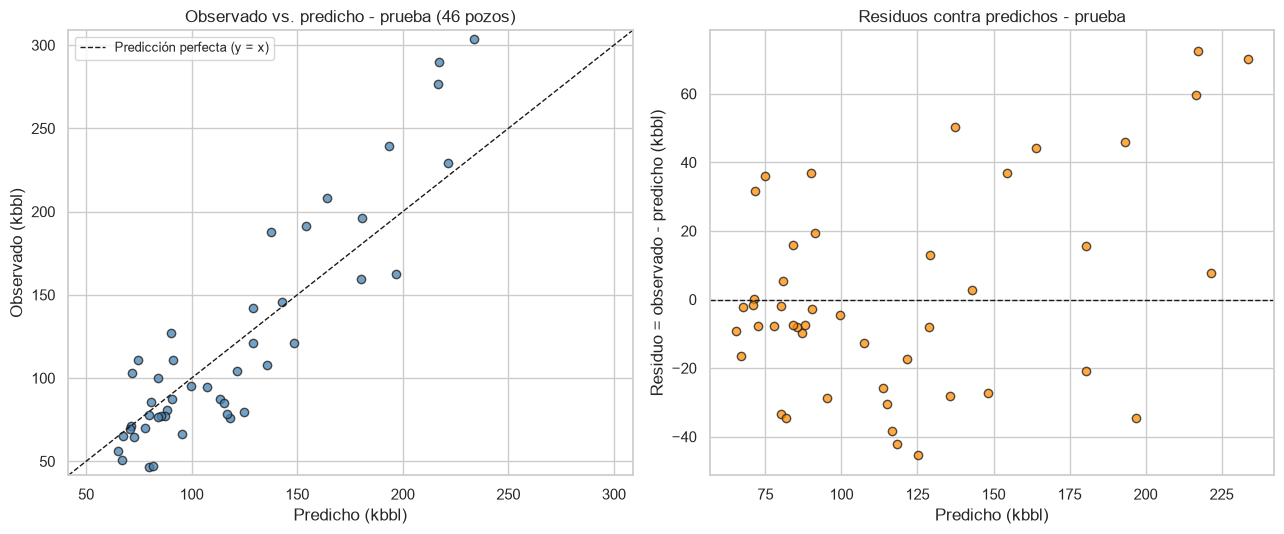

Residuo medio: +1.10 kbbl (sesgo del modelo)
Residuo mediano: -6.04 kbbl
Pozos con subestimación (residuo > 0): 18 de 46
Correlación de Spearman |residuo| vs predicho: +0.53 (p = 0.000)

Error por tercil de predicción:
         n  sesgo_medio   MAE
tercil                       
bajo    16        -2.56  13.7
medio   15       -14.47  22.0
alto    15        20.56  35.3

zona_label coincide con las dummies de X_test: True

Los 5 pozos con mayor error absoluto:
      zona  observado  predicho  residuo
32  Zona B      289.7     217.1     72.6
13  Zona A      303.8     233.8     70.0
11  Zona A      276.4     216.6     59.7
17  Zona A      187.7     137.4     50.3
15  Zona C      239.5     193.4     46.1


In [58]:

residuos = y_test.values - pred_test   # residuo = observado - predicho

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Gráfico 1: observados contra predichos, con la diagonal y = x como referencia
lim_min = min(y_test.min(), pred_test.min()) - 5
lim_max = max(y_test.max(), pred_test.max()) + 5
ax1.scatter(pred_test, y_test, color='steelblue', edgecolor='k', alpha=0.75)
ax1.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', lw=1, label='Predicción perfecta (y = x)')
ax1.set_xlim(lim_min, lim_max); ax1.set_ylim(lim_min, lim_max)
ax1.set_xlabel('Predicho (kbbl)')
ax1.set_ylabel('Observado (kbbl)')
ax1.set_title('Observado vs. predicho - prueba (46 pozos)')
ax1.legend(fontsize=9)

# Gráfico 2: residuos contra predichos, con la línea en cero
ax2.scatter(pred_test, residuos, color='darkorange', edgecolor='k', alpha=0.75)
ax2.axhline(0, color='k', ls='--', lw=1)
ax2.set_xlabel('Predicho (kbbl)')
ax2.set_ylabel('Residuo = observado - predicho (kbbl)')
ax2.set_title('Residuos contra predichos - prueba')

plt.tight_layout(); plt.show()

# Estadísticos que describen los gráficos
print(f"Residuo medio: {residuos.mean():+.2f} kbbl (sesgo del modelo)")
print(f"Residuo mediano: {np.median(residuos):+.2f} kbbl")
print(f"Pozos con subestimación (residuo > 0): {(residuos > 0).sum()} de {len(residuos)}")
rho_abs, p_abs = stats.spearmanr(pred_test, np.abs(residuos))
print(f"Correlación de Spearman |residuo| vs predicho: {rho_abs:+.2f} (p = {p_abs:.3f})")

# Error por tercil de predicción
tercil = pd.qcut(pred_test, 3, labels=['bajo', 'medio', 'alto'])
print("\nError por tercil de predicción:")
print(pd.DataFrame({'residuo': residuos, 'abs': np.abs(residuos), 'tercil': tercil})
      .groupby('tercil', observed=True)
      .agg(n=('residuo', 'size'), sesgo_medio=('residuo', 'mean'), MAE=('abs', 'mean'))
      .round(2).to_string())

# Zona de cada pozo de prueba, tomada de zona_label (alineada con X_test por índice)
zona_test = df.loc[X_test.index, 'zona_label'].values
assert len(zona_test) == len(y_test), "Longitud distinta a y_test"

# Chequeo de consistencia: la zona de cada pozo debe coincidir con sus dummies
# (Zona A es la referencia: todas las dummies en 0)
zona_desde_dummies = np.select(
    [X_test['zona_b'] == 1, X_test['zona_c'] == 1, X_test['zona_d'] == 1],
    ['Zona B', 'Zona C', 'Zona D'],
    default='Zona A'
)
coinciden = np.all(pd.Series(zona_test).astype(str).str.strip().values == zona_desde_dummies)
print(f"\nzona_label coincide con las dummies de X_test: {coinciden}")

# Pozos con mayor error absoluto
top = (pd.DataFrame({'zona': zona_test, 'observado': y_test.values,
                     'predicho': pred_test, 'residuo': residuos})
       .assign(abs_res=lambda d: d['residuo'].abs())
       .sort_values('abs_res', ascending=False).head(5))
print("\nLos 5 pozos con mayor error absoluto:")
print(top.drop(columns='abs_res').round(1).to_string())


**Concepto.** En el gráfico de observados contra predichos, cada pozo es un punto. Si el modelo fuera perfecto, todos caerían sobre la diagonal y = x. Los puntos por encima de la diagonal son pozos subestimados (el modelo predijo menos de lo que produjeron) y los que están por debajo son sobreestimados. El gráfico de residuos muestra el mismo error centrado en cero, con el valor predicho en el eje horizontal. Lo que se busca ahí es que no haya un patrón sistemático: una nube centrada, con dispersión constante, indica que el modelo no tiene un sesgo que dependa del nivel de producción.

**Resultado.** El residuo medio es de +1,1 kbbl, prácticamente cero, pero la mediana es de −6,0 kbbl. Esa diferencia indica que la distribución de los errores es asimétrica: algunos pozos con errores positivos grandes elevan el promedio. Hay 18 pozos subestimados y 28 sobreestimados entre los 46 de prueba.

**Patrón principal: el error crece con la producción predicha.** En el gráfico de residuos, la dispersión es chica para predicciones menores de 100 kbbl (en general dentro de ±15 kbbl) y se amplía de forma marcada para predicciones mayores de 150 kbbl, donde aparecen residuos de +40 a +72 kbbl. La correlación de Spearman entre el error absoluto y el valor predicho es de +0,53 (p < 0,001), lo que confirma el patrón. Al dividir los pozos en tercios por predicción, el MAE sube de 13,7 kbbl en el tercio bajo a 22,0 en el medio y 35,3 en el alto.

**Sesgo según el rango.** En el tercio alto, el sesgo medio es de +20,6 kbbl: el modelo subestima sistemáticamente a los pozos más productivos. En el gráfico de observados contra predichos, esos puntos quedan por encima de la diagonal. En el tercio medio, el sesgo es negativo (−14,5 kbbl): varios pozos de producción intermedia quedan con residuos de −20 a −45 kbbl, es decir, sobreestimados. En el tercio bajo el sesgo es casi nulo (−2,6 kbbl).

**Interpretación.** Este patrón es el esperable en random forest. Cada predicción es un promedio de valores observados en el entrenamiento, así que el modelo tiende a comprimir las predicciones hacia el centro del rango: los pozos muy productivos quedan subestimados porque el modelo no puede predecir valores muy por encima de lo que vio en entrenamiento, y los de producción intermedia quedan algo sobreestimados por el mismo efecto. Por eso el error absoluto no es uniforme: es mayor donde la producción es mayor.

**Pozos con mayor error.** Los cinco pozos con mayor error absoluto tienen producciones observadas entre 188 y 304 kbbl, y en los cinco el modelo subestima entre 46 y 73 kbbl. Tres pertenecen a la Zona A, uno a la Zona B y uno a la Zona C. Son casos reales de alta productividad y no errores de datos, así que se describen y no se eliminan. Conviene tenerlos en cuenta para cualquier uso del modelo en pozos de alta producción.

**Implicancia para el uso.** El modelo es menos confiable justamente en los pozos más productivos, que suelen ser los de mayor interés en una decisión de inversión. Esto no cambia la decisión de 11.3, pero debe declararse como limitación: la estimación es razonable para pozos de producción baja y media, y debe leerse con cautela en pozos de alta producción, donde puede subestimar el valor real en decenas de kbbl.


### 12.5 - ROC y AUC

Umbral (mediana de entrenamiento): 108.0 kbbl
Pozos de alta producción en prueba: 18 de 46


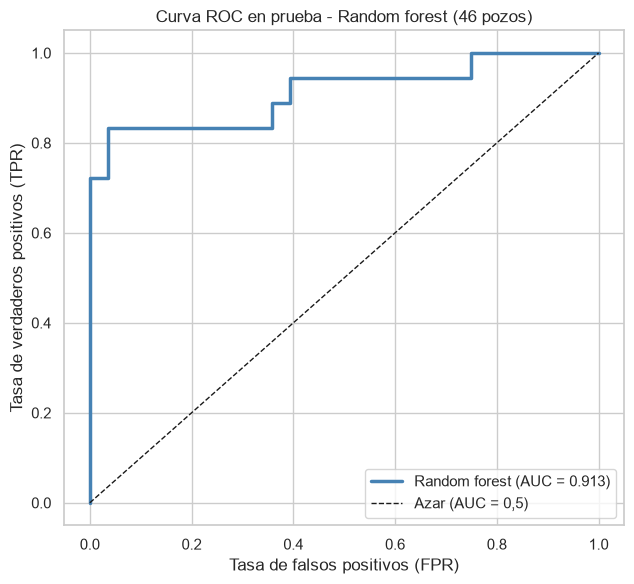


ROC AUC en prueba: 0.913
AUC por fold (referencia): [0.99  0.976 0.962 0.888 0.971]
AUC CV: 0.957 ± 0.040


In [59]:

# Umbral definido solo con el entrenamiento: mediana de 210d_kbbl en los 180 pozos de entrenamiento
umbral_train = float(y_train.median())
etiqueta_test = (y_test > umbral_train).astype(int)   # 1 = alta producción, 0 = baja
print(f"Umbral (mediana de entrenamiento): {umbral_train:.1f} kbbl")
print(f"Pozos de alta producción en prueba: {etiqueta_test.sum()} de {len(etiqueta_test)}")

# La predicción continua del random forest se usa como puntaje
fpr, tpr, umbrales = roc_curve(etiqueta_test, pred_test)
auc_test = roc_auc_score(etiqueta_test, pred_test)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color='steelblue', lw=2.5, label=f'Random forest (AUC = {auc_test:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0,5)')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR)')
ax.set_title('Curva ROC en prueba - Random forest (46 pozos)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print(f"\nROC AUC en prueba: {auc_test:.3f}")

# Referencia: AUC por fold externo de 11.3, con los hiperparámetros fijados en 11.3
cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)
aucs_cv = []
for idx_tr, idx_val in cv_externa.split(X_train):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    umbral_fold = float(y_tr.median())   # umbral de cada fold, calculado solo con su entrenamiento
    rf_fold = RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_leaf=3,
                                    max_features=0.5, random_state=42, n_jobs=-1)
    rf_fold.fit(X_tr, y_tr)
    aucs_cv.append(roc_auc_score((y_val > umbral_fold).astype(int), rf_fold.predict(X_val)))
aucs_cv = np.array(aucs_cv)
print(f"AUC por fold (referencia): {np.round(aucs_cv, 3)}")
print(f"AUC CV: {aucs_cv.mean():.3f} ± {aucs_cv.std(ddof=1):.3f}")


La producción es continua, así que la clase “alta” se define como 210d_kbbl por encima de la mediana de los 180 pozos de entrenamiento: 108,0 kbbl. El umbral se calcula solo con el entrenamiento; usar la mediana de la prueba sería usar la prueba para definir la variable de evaluación. Con ese umbral, 18 de los 46 pozos de prueba son de alta producción. La predicción continua del random forest se usa como puntaje, sin necesidad de un umbral de decisión adicional. Como el AUC depende de cómo se binariza la variable, es un complemento: no reemplaza a MAE, RMSE ni R².

Resultado: En los 46 pozos de prueba, el AUC es de 0,913. Como referencia, en los cinco folds de validación externa el AUC del mismo modelo fue de 0,957 ± 0,040, con valores entre 0,888 y 0,990. El AUC de prueba queda dentro de ese rango, algo por debajo de la media. La diferencia de 0,04 es menor que el desvío entre folds.

El modelo separa bien los pozos de alta producción de los de baja, aunque su error en kbbl sea considerable. Esto es coherente con los resultados del apartado anterior: el modelo ordena correctamente, pero comprime las predicciones hacia el centro, así que los pozos más productivos quedan subestimados en magnitud sin perder necesariamente su posición relativa en el ranking. Un AUC alto no significa que las predicciones en kbbl sean precisas, y tampoco que sirva para fijar un umbral de decisión sin un análisis de costos.


### 12.6 - Bootstrap

In [60]:

rng = np.random.default_rng(42)
B = 2000                       # número de remuestreos
n = len(y_test)
y_t = y_test.values
p_t = pred_test
etiq = (y_t > umbral_train).astype(int)

res_boot = {'MAE': [], 'RMSE': [], 'R²': [], 'ROC AUC': []}
for _ in range(B):
    idx = rng.integers(0, n, n)              # remuestreo con reemplazo de los 46 pozos
    yb, pb, eb = y_t[idx], p_t[idx], etiq[idx]
    if eb.min() == eb.max():                 # si la muestra quedó con una sola clase, el AUC no existe
        continue
    res_boot['MAE'].append(mean_absolute_error(yb, pb))
    res_boot['RMSE'].append(np.sqrt(mean_squared_error(yb, pb)))
    res_boot['R²'].append(r2_score(yb, pb))
    res_boot['ROC AUC'].append(roc_auc_score(eb, pb))

# Estimación puntual (la de 12.2 y 12.6) e intervalo percentil del 95 %
puntual = {
    'MAE': mae_test,
    'RMSE': rmse_test,
    'R²': r2_test,
    'ROC AUC': auc_test,
}
tabla_12_7 = pd.DataFrame({
    m: {
        'Estimación': puntual[m],
        'Error estándar (bootstrap)': np.std(v, ddof=1),
        'IC 95 % inferior': np.percentile(v, 2.5),
        'IC 95 % superior': np.percentile(v, 97.5),
    } for m, v in res_boot.items()
}).T
print(f"Remuestreos válidos: {len(res_boot['MAE'])} de {B}")
print(tabla_12_7.round(3).to_string())

# Ancho del intervalo del MAE, para leer su precisión
ancho_mae = np.percentile(res_boot['MAE'], 97.5) - np.percentile(res_boot['MAE'], 2.5)
print(f"\nAncho del IC 95 % del MAE: {ancho_mae:.1f} kbbl")
print(f"Proporción de remuestreos con MAE mayor que el de la validación anidada (22,08): "
      f"{np.mean(np.array(res_boot['MAE']) > 22.08):.0%}")

Remuestreos válidos: 2000 de 2000
         Estimación  Error estándar (bootstrap)  IC 95 % inferior  IC 95 % superior
MAE          23.447                       2.698            18.366            29.044
RMSE         29.852                       2.961            24.113            35.692
R²            0.793                       0.039             0.690             0.837
ROC AUC       0.913                       0.050             0.798             0.995

Ancho del IC 95 % del MAE: 10.7 kbbl
Proporción de remuestreos con MAE mayor que el de la validación anidada (22,08): 69%


El bootstrap estima la incertidumbre de una métrica sin suponer una distribución particular. Se remuestrean con reemplazo los 46 pozos de prueba (cada remuestreo tiene 46 pozos, pero algunos aparecen repetidos y otros no aparecen), se calcula la métrica en cada remuestreo y la dispersión de esos valores aproxima la incertidumbre de la estimación. El intervalo de confianza del 95 % se toma como los percentiles 2,5 y 97,5 de esa distribución. Es un procedimiento que solo reordena los datos ya observados, así que no reajusta el modelo ni cambia la decisión tomada.

----

Se realizaron 2.000 remuestreos con semilla fija, para que el resultado sea reproducible. Todos fueron válidos. Para el AUC se descartaría un remuestreo que dejara una sola clase, aunque en este caso no ocurrió. El umbral de alta producción sigue siendo el de entrenamiento (108,0 kbbl), para no usar la prueba en su definición.

#### Resultados.
 Con los intervalos del 95 %:

MAE: 23,4 kbbl, con intervalo entre 18,4 y 29,0 kbbl.
RMSE: 29,9 kbbl, con intervalo entre 24,1 y 35,7 kbbl.
R²: 0,79, con intervalo entre 0,69 y 0,84.
ROC AUC: 0,91, con intervalo entre 0,80 y 0,99.

El intervalo del MAE tiene un ancho de unos 11 kbbl. Eso significa que, con 46 pozos, el error medio real podría estar en cualquier punto entre unos 18 y 29 kbbl, y el resultado puntual de 23,4 es solo la mejor estimación dentro de ese rango. Lo mismo vale para el RMSE y el R². El intervalo del AUC es el más amplio en proporción, porque la clase de alta producción tiene solo 18 pozos. Con el umbral de 108 kbbl, el límite superior queda cerca de 1, pero no hay que leer ese dato como precisión.


La incertidumbre muestra que las diferencias de unos pocos kbbl entre modelos no pueden leerse como ventajas firmes con este tamaño de muestra. La decisión de usar random forest se apoya en la validación anidada de 11.3, y el bootstrap confirma que el error del modelo es alto en términos absolutos: un error medio que podría ser de casi 30 kbbl en el extremo superior. Cualquier uso del modelo debe declarar ese intervalo, no solo el valor puntual.


#### Conclusiones
**Qué se hizo** 
El random forest seleccionado en 11.3 se entrenó una sola vez con los 180 pozos de entrenamiento, con hiperparámetros fijos (sin límite de profundidad, min_samples_leaf = 3, max_features = 0.5, 200 árboles). Después se evaluó sobre los 46 pozos de prueba, que no habían participado en ninguna decisión. Sobre esa evaluación se reportaron las métricas de regresión, se comparó con la validación cruzada, se revisaron los residuos, se calculó el ROC AUC como complemento y se estimó la incertidumbre por bootstrap.

En prueba, el modelo tiene un MAE de 23,4 kbbl, un RMSE de 29,9 kbbl y un R² de 0,79. El MAE equivale al 24,7 % de la mediana de la prueba (94,8 kbbl). El ROC AUC para distinguir pozos de alta producción (por encima de 108,0 kbbl, la mediana de entrenamiento) es de 0,91.

---

#### Patrón de error
El error no es uniforme: crece con la producción predicha. Los pozos de producción baja tienen un MAE de unos 14 kbbl, mientras que en el tercio de mayor producción llega a unos 35 kbbl. En ese tercio el modelo subestima de forma sistemática (sesgo medio de +21 kbbl), y los cinco pozos con mayor error son casos de alta productividad que el modelo subestima entre 46 y 73 kbbl. Esto es un efecto esperable de random forest, que promedia valores observados y tiende a comprimir las predicciones hacia el centro del rango.

**Qué significa en la práctica:** El modelo ordena bien los pozos (el AUC lo confirma), pero sus estimaciones en kbbl son orientativas. Un error medio de unos 23 kbbl sobre pozos con mediana de 95 kbbl no alcanza para decisiones finas por pozo. Es más confiable para pozos de producción baja y media que para los de alta producción, justamente donde suele estar el mayor interés económico.

---

#### Conclusión
El random forest es un modelo con capacidad predictiva real: explica cerca del 80 % de la variabilidad de la producción en pozos no vistos y separa razonablemente bien los pozos de alta producción. Su error absoluto, sin embargo, es considerable, y su incertidumbre es amplia con el tamaño de muestra disponible. La recomendación es usarlo como estimación orientativa, siempre informando el intervalo y la limitación en el extremo alto, y no como herramienta de decisión sobre pozos individuales. Mejorar la precisión requiere más datos y, posiblemente, variables que no están en el dataset actual.

La evaluación se basa en un solo conjunto de 46 pozos, así que cualquier conclusión fina sobre diferencias entre modelos carece de poder estadístico. El modelo no fue reentrenado con los 226 pozos para este análisis; si se usa en producción, conviene reentrenarlo y declarar que sus métricas de prueba corresponden a la versión de 180 pozos. Tampoco se puede afirmar causalidad: el modelo describe asociaciones entre las variables de diseño, geología y estimulación y la producción, no efectos de intervenir sobre ellas.

## 13. ¿Qué modelo funcionó mejor? ¿Cuál usarías en un entorno productivo? Justificá.

### 13.1 - Comparativas de modelos

In [61]:

def por_fold(y_real, pred):
    return (mean_absolute_error(y_real, pred),
            np.sqrt(mean_squared_error(y_real, pred)),
            r2_score(y_real, pred))

cv_externa = KFold(n_splits=5, shuffle=True, random_state=7)

# Random forest: búsqueda interna por grilla (la misma de 11.3)
rf_busq = GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
                       {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [3, 5, 10, 15],
                        'max_features': [0.33, 0.5, 1.0]},
                       cv=cv5, scoring='neg_mean_absolute_error', refit=True, n_jobs=-1)
# Regresión lineal: sin búsqueda (referencia)
lineal = clone(modelo_lineal)

resultados_anidados = {'Random forest (grilla)': [], 'Regresión lineal': []}
for idx_tr, idx_val in cv_externa.split(X_train):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    resultados_anidados['Random forest (grilla)'].append(
        por_fold(y_val, clone(rf_busq).fit(X_tr, y_tr).predict(X_val)))
    resultados_anidados['Regresión lineal'].append(
        por_fold(y_val, lineal.fit(X_tr, y_tr).predict(X_val)))

# Valores por fold ya obtenidos en 11.3 (XGBoost con Optuna y Ridge con grilla de alpha)
resultados_anidados['XGBoost (Optuna)'] = list(zip(
    [18.214, 23.987, 23.625, 24.358, 19.296],
    [26.483, 30.628, 31.128, 31.040, 25.207],
    [0.801, 0.775, 0.778, 0.730, 0.789]))
resultados_anidados['Ridge (grilla de alpha)'] = list(zip(
    [22.584, 23.407, 25.922, 26.048, 18.669],
    [27.068, 28.613, 31.986, 30.779, 22.897],
    [0.792, 0.803, 0.765, 0.735, 0.826]))

filas = {}
for nombre, folds in resultados_anidados.items():
    f = np.array(folds)
    filas[nombre] = {
        'MAE media': f[:, 0].mean(), 'MAE desvío': f[:, 0].std(ddof=1),
        'RMSE media': f[:, 1].mean(), 'RMSE desvío': f[:, 1].std(ddof=1),
        'R² media': f[:, 2].mean(), 'R² desvío': f[:, 2].std(ddof=1),
    }
tabla_13_1 = pd.DataFrame(filas).T
print(tabla_13_1.round(2).to_string())

                         MAE media  MAE desvío  RMSE media  RMSE desvío  R² media  R² desvío
Random forest (grilla)       22.08        2.26       28.96         2.59      0.77       0.03
Regresión lineal             23.65        2.39       28.55         3.01      0.78       0.03
XGBoost (Optuna)             21.90        2.90       28.90         2.83      0.77       0.03
Ridge (grilla de alpha)      23.33        3.02       28.27         3.55      0.78       0.04


Realizo la comparativa nuevamente aunque se haya visto en apartados anteriores. De esta forma estructuro bien los puntos del informe

**Resultado.**
| Modelo | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| XGBoost (Optuna) | 21,90 ± 2,90 | 28,90 ± 2,83 | 0,77 ± 0,03 |
| Random forest (grilla) | 22,08 ± 2,26 | 28,96 ± 2,59 | 0,77 ± 0,03 |
| Ridge (grilla de alpha) | 23,33 ± 3,02 | 28,27 ± 3,55 | 0,78 ± 0,04 |
| Regresión lineal | 23,65 ± 2,39 | 28,55 ± 3,01 | 0,78 ± 0,03 |

**Qué funcionó mejor, según la métrica.** La respuesta depende de qué se mire. Por MAE medio, el mejor es XGBoost, seguido muy de cerca por random forest. Por RMSE, el mejor es Ridge, seguido por la regresión lineal. Por R², los dos modelos lineales empatan en 0,78 y los de árboles en 0,77. Ningún modelo es mejor en todas las métricas.

**Qué tan grandes son las diferencias.** Las diferencias de MAE entre los cuatro modelos van de 0,2 a 1,8 kbbl, y los desvíos son de 2 a 3 kbbl. XGBoost y random forest difieren en 0,18 kbbl, mucho menos que cualquiera de sus desvíos. Los modelos de árboles quedan 1,4 a 1,7 kbbl por debajo de los lineales en MAE, una diferencia menor que la dispersión entre folds. Con cinco folds, ninguna de estas diferencias se puede considerar concluyente. En la comparación pareada de XGBoost contra Ridge, por fold, la diferencia no es estadísticamente significativa.

**Lectura.** Los cuatro modelos tienen un desempeño prácticamente equivalente en esta muestra. A la pregunta de qué funcionó mejor, la respuesta es que XGBoost tiene el menor error absoluto medio, pero esa ventaja no es firme, y los modelos lineales son competitivos en RMSE y R². La decisión de cuál usar no puede basarse en una métrica aislada, sino en la estabilidad, la complejidad y el uso previsto, lo que se desarrolla en 13.2.


### 13.2 - Modelo elegido para un entorno productivo


**Criterios considerados.**

| Criterio | Random forest | XGBoost | Regresión lineal / Ridge |
|---|---|---|---|
| Error medio (MAE, validación anidada) | 22,08 kbbl | 21,90 kbbl | 23,33 a 23,65 kbbl |
| Dispersión entre folds (MAE) | 2,26 kbbl | 2,90 kbbl | 2,39 a 3,02 kbbl |
| Sensibilidad a hiperparámetros | Baja: superficie de error plana | Baja, pero con 7 hiperparámetros y mayor riesgo de sobreajuste en la búsqueda | No aplica (Ridge tiene un solo hiperparámetro) |
| Comportamiento con más datos (curva de aprendizaje) | Validación todavía mejorando | Validación casi estable desde unos 90 pozos | Validación casi estable desde unos 100 pozos |
| Complejidad de la búsqueda y reentrenamiento | Media (grilla de 48 combinaciones) | Alta (búsqueda bayesiana con 60 ensayos, dependencia de librerías externas) | Baja |
| Interpretabilidad | Parcial: importancia de variables | Parcial: importancia de variables, menos directa | Alta: coeficientes con signo y magnitud |
| Error en prueba (46 pozos) | 23,4 kbbl (IC 95 %: 18,4 a 29,0) | No evaluado (decisión de 12.4) | No evaluado (decisión de 12.4) |

**Decisión.** Para el entorno productivo se elige **random forest optimizado** con la grilla de 11.3 (sin límite de profundidad, `min_samples_leaf = 3`, `max_features = 0.5`, 200 árboles), entrenado con los 180 pozos de entrenamiento.

**Justificación.**

1. **Error equivalente al mejor.** Random forest empata con XGBoost en error medio. La diferencia de 0,18 kbbl es mucho menor que cualquiera de los desvíos, así que no hay una ventaja que justifique elegir XGBoost por el error.

2. **Mayor estabilidad frente a los datos.** Entre los modelos de árboles, random forest tiene menor dispersión del MAE entre folds (2,26 frente a 2,90 kbbl). En un entorno productivo, esto significa que el error depende menos de qué pozos entren en el entrenamiento, algo relevante porque el conjunto de datos es pequeño y puede cambiar.

3. **Menor dependencia de una búsqueda fina.** La superficie de error de random forest es muy plana: las diez mejores combinaciones están dentro de 0,4 kbbl. En XGBoost, la mejor combinación usa la profundidad mínima del rango, lo que sugiere que el resultado depende de decisiones de búsqueda (rangos y número de ensayos) más que el de random forest. Reemplazar o reentrenar un modelo con una búsqueda más sencilla es más fácil de reproducir y de auditar.

4. **Capacidad de mejora con más datos.** La curva de aprendizaje de random forest no se estabilizó en el último tramo, así que es razonable esperar una mejora si se incorporan nuevos pozos. XGBoost ya está estable, con un error de validación ligeramente menor con 144 pozos (22,4 frente a 22,8 kbbl), pero ese margen queda dentro de la incertidumbre.

5. **Información sobre las variables.** Random forest permite medir la importancia relativa de las predictoras, algo útil para el equipo técnico, aunque no reemplaza a un análisis causal.

**Alternativa considerada: regresión lineal o Ridge.** Tienen un error levemente mayor (0,3 a 1,7 kbbl más), pero son los modelos más interpretables: cada coeficiente tiene signo y magnitud. Si el uso previsto requiere explicar a ingeniería el efecto de una variable, como `ef_l_m`, conviene priorizar Ridge. Sin embargo, el análisis del punto 8 mostró colinealidad entre predictoras, lo que hace que los coeficientes sean inestables y difíciles de interpretar causalmente aun con regularización. Por eso no se eligió como modelo principal, aunque se mantiene como referencia.

**Qué cambiaría la decisión.**

- Si el uso previsto exige explicar cada predicción con coeficientes, se elige Ridge, con un costo de error de pocos kbbl.
- Si el reentrenamiento con más datos muestra que XGBoost mejora de forma consistente en validación, se revisa la elección con esa evidencia.
- Si en prueba random forest se desvía de forma clara de la validación, se reabre la decisión antes de desplegarlo.

**Limitaciones que acompañan a la decisión.**

- El modelo subestima de forma sistemática los pozos de alta producción. Esta limitación no se resuelve eligiendo otro árbol, porque es un efecto de promediar valores observados; debe declararse en cualquier uso.
- El error medio es de unos 22 a 23 kbbl, cerca del 25 % de la mediana de producción de la prueba. El modelo sirve como estimación orientativa, no para decisiones finas por pozo.
- Los residuos del modelo lineal no se revisaron con el mismo detalle, así que no se puede afirmar que el patrón de error de random forest sea mejor o peor que el de la lineal en los extremos.
- La decisión se apoya en 180 pozos de entrenamiento y 46 de prueba. Cualquier diferencia entre modelos tiene mucha incertidumbre.

**Recomendación para producción.** Desplegar random forest reentrenado con los 226 pozos disponibles, declarando que las métricas de prueba (23,4 kbbl de MAE) corresponden a la versión entrenada con 180. Acompañar cada estimación con el intervalo de incertidumbre y con la advertencia de subestimación en pozos de alta producción. Reevaluar el modelo cuando haya más datos reales y ver la posibilad de elegir otro modelo. 

### 13.3 - Condiciones bajo las cuales cambiaría la decisión y alternativa


**Concepto.** Una decisión de modelado es válida para un contexto y una evidencia determinados. Por eso conviene explicitar en qué condiciones se revisaría, qué alternativa queda disponible y qué debe acompañar a cualquier uso del modelo. Esto evita que la elección se presente como definitiva cuando depende de supuestos.

**Condiciones que llevarían a revisar la decisión.**

- **Requisito de explicabilidad.** Si el equipo que usa el modelo necesita justificar predicciones con el efecto de cada variable (por ejemplo, el efecto de `ef_l_m` sobre la producción a 210 días), la prioridad pasa a Ridge. Esto no es un problema de métricas: Ridge tiene un error prácticamente igual y coeficientes con signo y magnitud. Aun así, la interpretación debe ser de asociación, no de causa, y debe tener en cuenta la colinealidad detectada en el análisis exploratorio.

- **Incorporación de nuevos pozos.** Si se suman datos reales y se reentrena, la decisión debe reevaluarse con el mismo protocolo: validación anidada y prueba separada. La curva de aprendizaje de random forest todavía no se estabilizó, por lo que el ranking entre random forest y XGBoost podría cambiar con más datos.

- **Discrepancia entre prueba y validación.** Si en una evaluación futura el MAE de prueba queda fuera del rango de la validación anidada (en este análisis, de 18,6 a 23,9 kbbl por fold), o si el ROC AUC cae de forma sostenida, la decisión se reabre antes de desplegar el modelo.

- **Cambio en el uso previsto.** Si el modelo se usara para decidir sobre pozos individuales de alta producción, la decisión no se resuelve cambiando de algoritmo. Ese uso queda fuera del alcance de este análisis, porque el error en ese rango es el más alto y el modelo lo subestima de forma sistemática.

- **Cambio en la población de pozos.** Si aparecen zonas o rangos de variables que no están representados en los 226 pozos, el modelo no puede evaluarse para ellos. Un árbol no extrapola fuera del rango de entrenamiento, y una regresión lineal sí lo hace, pero sin garantía de que sea válido.

**Alternativas disponibles.**

1. **Ridge (grilla de alpha), para contextos interpretables.** Error de validación anidada de 23,3 kbbl, con un costo de 1 a 1,5 kbbl frente a random forest. Es la alternativa a usar si la explicabilidad pesa más que el error.
2. **XGBoost (Optuna), si aumenta el volumen de datos.** Tiene el menor MAE medio en validación, pero con mayor dispersión entre folds y una búsqueda más compleja de reproducir. Sería el candidato a reevaluar cuando haya más pozos.
3. **Regresión lineal sin regularizar.** Mismo error que Ridge en esta muestra, pero con coeficientes más inestables por la colinealidad. No se recomienda como modelo principal.

**Qué debe acompañar cualquier uso del modelo.**

- Declarar que las métricas de prueba (MAE de 23,4 kbbl, RMSE de 29,9 kbbl, R² de 0,79) corresponden al modelo entrenado con 180 pozos, y no a la versión reentrenada con 226 si se usa esa.
- Presentar cada estimación junto con el intervalo de incertidumbre del bootstrap (IC 95 % del MAE entre 18,4 y 29,0 kbbl) y no solo el valor puntual.
- Advertir la subestimación en pozos de alta producción y restringir el uso orientativo a los rangos donde el error es razonable.
- Definir por anticipado el umbral que activa la revisión (por ejemplo, un MAE de seguimiento fuera del rango de la validación anidada), para que la decisión de reabrir el modelo no dependa de mirar los resultados.
- Registrar la versión del modelo, sus hiperparámetros y la fecha de entrenamiento, para poder reproducir cualquier estimación.


# Parte 4 - Conclusiones Integradoras

## 14. Mostrá los resultados de los modelos entrenados a través de uno o más gráficos.
Comentá brevemente las decisiones de diseño:
● ¿Qué tipo de gráfico elegiste y por qué te parece adecuado para representar
esa información?
● ¿Qué conclusiones o patrones permite observar este gráfico?

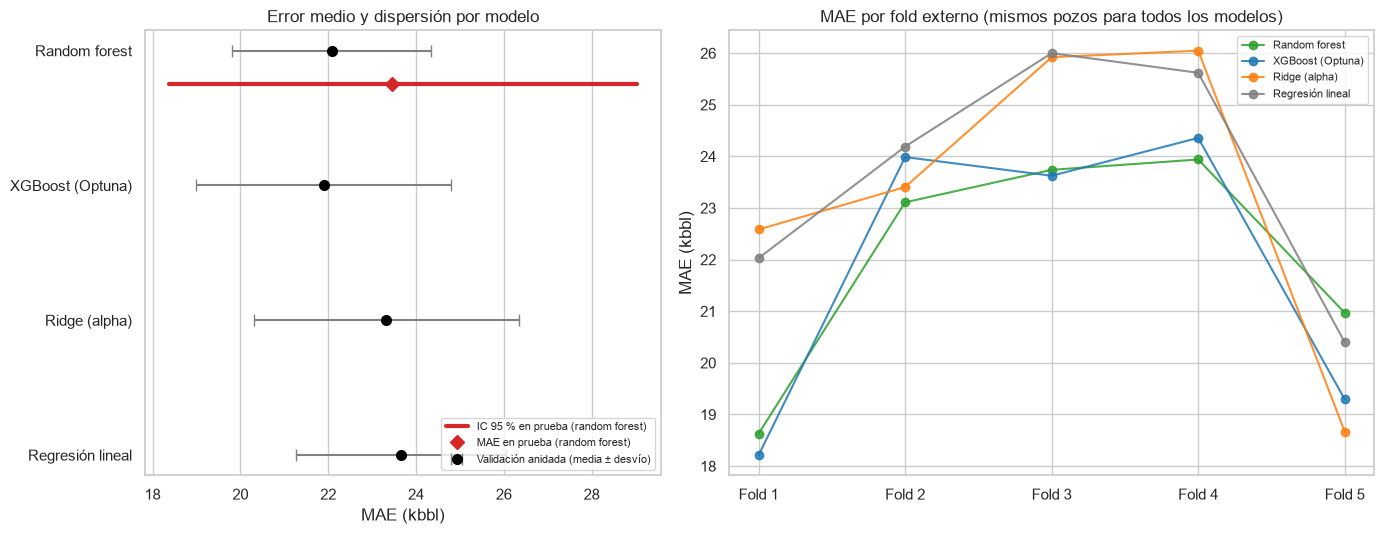

MAE medio por modelo:
  Random forest      22.08 ± 2.26
  XGBoost (Optuna)   21.90 ± 2.90
  Ridge (alpha)      23.33 ± 3.02
  Regresión lineal   23.65 ± 2.39

Diferencia por fold (modelo - random forest):
  XGBoost (Optuna)   [-0.42  0.88 -0.11  0.42 -1.67]  media -0.18
  Ridge (alpha)      [ 3.95  0.3   2.18  2.11 -2.3 ]  media +1.25
  Regresión lineal   [ 3.4   1.08  2.26  1.68 -0.57]  media +1.57


In [62]:

# MAE por fold externo (mismos folds para todos los modelos; valores de 11.3, 12.3 y 13.1)
mae_folds = {
    'Random forest': [18.63, 23.11, 23.74, 23.94, 20.97],
    'XGBoost (Optuna)': [18.214, 23.987, 23.625, 24.358, 19.296],
    'Ridge (alpha)': [22.584, 23.407, 25.922, 26.048, 18.669],
    'Regresión lineal': [22.03, 24.19, 26.00, 25.62, 20.40],
}
# Intervalo bootstrap del MAE de prueba del random forest (12.7)
ic_prueba_rf = (18.366, 29.044)
mae_prueba_rf = 23.447

modelos = list(mae_folds.keys())
medias = np.array([np.mean(v) for v in mae_folds.values()])
desvios = np.array([np.std(v, ddof=1) for v in mae_folds.values()])
colores = ['tab:green', 'tab:blue', 'tab:orange', 'tab:gray']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.25]})

# Panel izquierdo: media ± desvío de la validación anidada, y el intervalo de prueba del random forest
y_pos = np.arange(len(modelos))[::-1]
ax1.errorbar(medias, y_pos, xerr=desvios, fmt='o', color='black', ecolor='gray',
             capsize=4, markersize=7, label='Validación anidada (media ± desvío)')
ax1.plot([ic_prueba_rf[0], ic_prueba_rf[1]], [y_pos[0] - 0.25] * 2, color='tab:red', lw=3,
         label='IC 95 % en prueba (random forest)')
ax1.plot(mae_prueba_rf, y_pos[0] - 0.25, 'D', color='tab:red', markersize=7,
         label='MAE en prueba (random forest)')
ax1.set_yticks(y_pos); ax1.set_yticklabels(modelos)
ax1.set_xlabel('MAE (kbbl)')
ax1.set_title('Error medio y dispersión por modelo')
ax1.legend(fontsize=8, loc='lower right')
ax1.grid(axis='y', visible=False)

# Panel derecho: MAE por fold, uniendo cada fold entre modelos para ver la comparación pareada
x = np.arange(1, 6)
for (nombre, valores), c in zip(mae_folds.items(), colores):
    ax2.plot(x, valores, 'o-', color=c, label=nombre, alpha=0.85)
ax2.set_xticks(x); ax2.set_xticklabels([f'Fold {i}' for i in x])
ax2.set_ylabel('MAE (kbbl)')
ax2.set_title('MAE por fold externo (mismos pozos para todos los modelos)')
ax2.legend(fontsize=8)

plt.tight_layout(); plt.show()

print("MAE medio por modelo:")
for m, mu, sd in zip(modelos, medias, desvios):
    print(f"  {m:<18} {mu:.2f} ± {sd:.2f}")

# Diferencias pareadas frente a random forest, por fold
ref = np.array(mae_folds['Random forest'])
print("\nDiferencia por fold (modelo - random forest):")
for m in modelos[1:]:
    d = np.array(mae_folds[m]) - ref
    print(f"  {m:<18} {np.round(d, 2)}  media {d.mean():+.2f}")


**Decisiones de diseño del gráfico.** Se eligieron dos paneles porque responden a preguntas distintas. El panel de la izquierda muestra el nivel del error (media) y su dispersión (desvío) para cada modelo, con el intervalo de incertidumbre del random forest en prueba como referencia externa. Es la forma más directa de comparar cuatro modelos con una sola mirada. El panel de la derecha muestra el MAE de cada fold externo, uniendo los puntos de cada modelo: como los cuatro se evaluaron sobre los mismos folds, esa lectura pareada permite ver si una diferencia se sostiene pozo a pozo o solo aparece en promedio. Se descartaron gráficos de barras, porque ocultan la dispersión y no permiten la comparación por fold.

**Patrones observados en el panel izquierdo.** Los cuatro modelos están en un rango estrecho, entre 21,9 y 23,7 kbbl. Los desvíos (entre 2,3 y 3,0 kbbl) son mayores que casi todas las diferencias entre medias, así que los intervalos se superponen por completo. El intervalo en prueba del random forest (18,4 a 29,0 kbbl) abarca a los cuatro modelos, lo que confirma que la muestra de 46 pozos no permite distinguirlos.

**Patrones observados en el panel derecho.** Las líneas se cruzan. XGBoost es mejor que random forest en los folds 1, 3 y 5, y peor en los folds 2 y 4 (en el fold 2 la diferencia es de +0,88 kbbl y en el fold 4 de +0,42). La diferencia media es de solo 0,18 kbbl a favor de XGBoost. Ridge y la regresión lineal son peores que random forest en cuatro de los cinco folds, con diferencias de 1 a 4 kbbl. En el fold 5, en cambio, las dos lineales superan a random forest. Ese fold, con un error bajo para todos los modelos, es el único donde la regresión lineal gana, y muestra que la ventaja de los árboles depende de qué pozos se evalúan.

**Conclusión del gráfico.** Los árboles tienen un error medio algo menor que los modelos lineales, pero la ventaja no es consistente en todos los folds, y la diferencia entre random forest y XGBoost es prácticamente nula. Lo que sí se mantiene estable en ambos paneles es el patrón general: ningún modelo domina en todos los pozos y el error absoluto del conjunto queda alrededor de 22 kbbl. Esto respalda la decisión de 13.2 de elegir por estabilidad y uso previsto, y no solo por el MAE medio.

## 15. ¿Qué decisiones influyeron más en el rendimiento del modelo: selección de variables, limpieza, tipo de modelo?



1. **La decisión más influyente fue qué información entra al modelo.** Pasar de predecir siempre la media (54 kbbl) a usar las predictoras reduce el error a la mitad, una diferencia de unos 30 kbbl. Ninguna otra decisión de modelado se acerca a ese efecto. En este sentido, la selección de variables es la decisión con mayor impacto, y dentro de ella, excluir las variables que solo se conocen después de la producción fue la más importante para la validez del análisis. Esa exclusión no mejora el rendimiento aparente: lo hace honesto. Incluirlas daría un error bajo artificialmente, porque el modelo tendría acceso a información del futuro.

2. **El tipo de modelo influye, pero poco.** La diferencia entre la lineal y el random forest es de unos 2 kbbl, comparable al desvío entre folds. Elegir entre familias de modelos mueve el resultado mucho menos que elegir qué información usar.

3. **El ajuste de hiperparámetros no mejoró el random forest.** La versión por defecto tuvo un error igual o levemente menor que la versión ajustada. Esto no significa que el ajuste sea inútil en general, sino que, con 180 pozos y superficies de error planas, la búsqueda no encontró una mejora que se sostenga fuera de los folds donde se eligió.

4. **El escalado no cambió nada en la regresión lineal.** La regresión lineal ordinaria no depende de la escala de las variables: multiplicar una predictora por una constante solo cambia su coeficiente, no las predicciones. Por eso la decisión de usar RobustScaler para las asimétricas no tiene efecto aquí. Sí puede importar en Ridge, donde la penalización depende de la escala; esa comparación no se midió y no se afirma su efecto.

5. **Las variables de zona aportan poco.** Quitarlas no empeora el error, sino que lo mejora ligeramente, dentro de la variabilidad. Esto sugiere que la zona no agrega información que las predictoras geológicas y de diseño no tengan. No se elimina el resultado, pero se declara como una señal a revisar con más datos.



## 16 - ¿Qué limitaciones tiene el análisis? ¿Qué datos adicionales serían útiles?


**Limitaciones de los datos**

- **Tamaño de la muestra.** Trabajamos con 226 pozos, después de descartar 772 de las 998 filas del archivo por valores faltantes. Con 180 pozos de entrenamiento y 46 de prueba, las estimaciones tienen intervalos amplios: el IC 95 % del MAE va de 18,4 a 29,0 kbbl. Con muestras así, las diferencias entre modelos de 1 a 2 kbbl no son concluyentes.
- **Cobertura de zonas.** Son cuatro zonas, y la distribución de pozos entre ellas es desigual. Cualquier conclusión por zona tiene muy pocos casos.
- **Rango de producción.** Los pozos de alta producción están poco representados. Como vimos en 12.5, el modelo los subestima de forma sistemática, y con tan pocos casos no podemos caracterizar ese rango con precisión.
- **Ausencia de información temporal.** No tenemos fecha de perforación, de terminación ni de inicio de producción. Si hay cambios en prácticas operativas, tecnología de fractura o condiciones del yacimiento a lo largo de los años, el modelo los trata como si fueran estables. No podemos evaluar esto ya que suponemos que toda la practica operativa se realizo con las misma condiciones y mismas tecnologias. 
- **Selección de hiperparámetros con datos limitados.** Las búsquedas se hicieron con grillas y espacios definidos a mano, y la superficie de error resultó plana. Otras elecciones de rangos podrían dar resultados ligeramente distintos.
- **Uso del ROC AUC.** Lo calculamos con un umbral de 108,0 kbbl, que es arbitrario. El AUC cambia con el umbral y no dice qué tan útil sería una decisión concreta.

---

**Limitaciones de lo que el modelo puede afirmar**

- **Asociación, no causalidad.** Los modelos describen relaciones entre el diseño, la geología y la producción, pero no dicen qué pasaría si se cambia una variable. Por ejemplo, que un pozo con más longitud lateral produzca más no significa que aumentar la longitud sea la intervención que genera ese aumento.


**Datos adicionales que serían útiles**

Estos datos no los tenemos, y cada uno respondería a una de las limitaciones anteriores:

1. **Fechas de perforación, terminación e inicio de producción.** Permitirían evaluar la deriva temporal y hacer una validación en el tiempo, entrenando con pozos más antiguos y evaluando con los más recientes. Es la forma más realista de estimar el desempeño sobre pozos futuros.
2. **Identificadores de plataforma, pad, operador y yacimiento.** Permitirían verificar la dependencia entre pozos y usar validación agrupada (por ejemplo, `GroupKFold`), para que la evaluación refleje el caso de un pozo nuevo en un área nueva.
3. **Historia de producción más allá de 210 días.** Serviría para comparar horizontes de predicción, validar el objetivo con curvas completas y detectar si la variable a 210 días es representativa del comportamiento a más largo plazo.
4. **Documentación del diccionario de datos y de los procedimientos de medición.** Permitiría distinguir errores de carga de valores atípicos reales, y evaluar la incertidumbre de las variables geológicas y de estimulación.
6. **Más pozos, sobre todo en el rango de alta producción.** Es la vía más directa para reducir la incertidumbre y el sesgo en los extremos. Con más datos, la curva de aprendizaje de random forest tendría margen para seguir mejorando.


## 17. Conclusiones del analisis


**Pregunta de investigación.** ¿En qué medida es posible predecir la producción acumulada de petróleo a 210 días (`210d_kbbl`) a partir de características geológicas, geomecánicas, de diseño y de estimulación, y qué modelo de regresión ofrece el mejor desempeño predictivo bajo una evaluación rigurosa?

**Respuesta** Es posible predecir la producción a 210 días con una capacidad predictiva real pero con un error considerable. El random forest optimizado explica cerca del 80 % de la variabilidad de la producción en pozos no vistos (R² de 0,79 en prueba), pero su error medio es de unos 23 kbbl, cerca del 25 % de la mediana de producción. Entre los modelos evaluados, XGBoost y random forest tienen el menor error medio, pero la diferencia con los modelos lineales no es concluyente, por lo que el criterio de elección fue la estabilidad y el uso previsto.

**Resumen de hallazgos por etapa.**

1. **Datos y gobernanza.** El archivo contiene 998 filas, de las cuales 226 tienen información completa en todas las columnas utilizadas. Descartar el resto es la limitación de datos más grande del análisis, porque no sabemos si esos pozos son distintos. Las variables posteriores a la producción (como las que se conocen después de los primeros meses) se excluyeron del modelo para evitar fuga de información.

2. **Modelado.** Con validación anidada de 5 folds, los cuatro modelos evaluados tienen un error medio entre 21,9 y 23,7 kbbl, con desvíos de 2 a 3 kbbl. XGBoost tiene el menor MAE medio (21,90 kbbl), pero random forest (22,08 kbbl) es más estable entre folds. La regresión lineal y Ridge son competitivos, y tienen la ventaja de la interpretabilidad.

3. **Evaluación final.** Random forest, entrenado con 180 pozos y evaluado una sola vez en 46 pozos no usados para decidir, tiene un MAE de 23,4 kbbl (IC 95 % entre 18,4 y 29,0), un RMSE de 29,9 kbbl y un R² de 0,79. Su resultado está dentro de la variabilidad observada en validación. Para pozos de alta producción, el modelo subestima de forma sistemática: en el tercio de mayor producción predicha, el error medio supera los 35 kbbl.

4. **Clasificación complementaria.** Al binarizar la producción con el umbral de entrenamiento (108 kbbl), el ROC AUC en prueba es de 0,91. El modelo ordena bien los pozos de alta y baja producción, aunque sus estimaciones en kbbl no sean precisas.

---

**Conclusiones.**

- **Sí hay capacidad predictiva.** Las variables de diseño, geología y estimulación contienen información útil sobre la producción a 210 días: explican la mayor parte de la variabilidad en pozos no vistos y separan razonablemente bien los pozos de alta producción.

- **El error es alto para decisiones por pozo.** Un error medio de unos 22 a 23 kbbl sobre pozos con mediana cercana a 95 kbbl no permite estimaciones finas. El modelo sirve como orientación dentro del rango de datos observado.

- **La mejora depende más de los datos que del algoritmo.** Cambiar de familia de modelo o ajustar hiperparámetros movió el error muy poco. Lo que más limita el resultado es la cantidad de pozos, la falta de información temporal y de agrupamiento, y el rango de producción poco representado.

- **La elección del modelo es una decisión de contexto.** Random forest es la recomendación para uso productivo por estabilidad y capacidad de mejora con más datos. Si el uso exige explicar el efecto de cada variable, la alternativa es Ridge, con un error prácticamente igual.

- **Los resultados describen asociaciones.** El análisis no permite afirmar qué pasaría con la producción si se modificara una variable de diseño o de estimulación. Las importancias de variables no son causas.


# Notas Finales 

Hola!

Soy Alam Martínez, ingeniero en Petróleos recientemente graduado de la Universidad Nacional de Cuyo. Este notebook documenta el desarrollo del Proyecto Integrador "Predicción en producción de pozos de petróleo", realizado en el marco del curso de "Fundamentos de Ciencia de Datos aplicados a la industria energética", dictado por la Fundación Sadosky en conjunto con la Fundación YPF.

El objetivo de este notebook no es únicamente producir un proyecto que cumpla con la consigna. También busca funcionar como una guía de trabajo en un entorno académico, registrando el recorrido que seguí tanto en la comprensión teórica como en la práctica, desde la revisión del dataset hasta la evaluación final de los modelos. Por eso cada sección detalla qué se evalúa, por qué se evalúa y cómo se interpretan los resultados obtenidos.

Mi formación universitaria no incluye asignaturas de ciencia de datos ni de programación en Python y sus librerías. Por ese motivo, este proyecto representó un aprendizaje considerable, tanto conceptual como instrumental: estadística descriptiva aplicada, validación de modelos, prevención de fuga de información, lectura crítica de métricas y programación reproducible.

Durante el desarrollo utilicé los materiales bibliográficos y las guías proporcionadas por el curso como fuente principal de referencia teórica. Además, recurrí a herramientas de inteligencia artificial, principalmente Claude y Gemini, para optimizar parte del código, revisar la sintaxis y reformular algunas explicaciones escritas. Quiero dejar claro que todo el razonamiento, las decisiones metodológicas, la interpretación de los resultados y las conclusiones son de mi autoría por lo que no son exactas ni mucho menos perfectas. Estas herramientas funcionaron como un recurso complementario, y cada fragmento incorporado fue revisado, ejecutado y comprendido antes de darlo por válido.

Reconozco que el notebook presenta repeticiones en varias secciones. Esa redundancia es deliberada en la medida en que este documento cumple, para mi, una función didáctica: explicitar el razonamiento paso a paso y dejarlo disponible para revisión propia y de terceros. Pido disculpas si en algunos tramos resulta excesiva, aunque considero que sirve al objetivo de aprendizaje que motivó el trabajo.

La mayor enseñanza que me dejó este trabajo es que el resultado de un modelo depende más de la información con la que se alimenta que de la sofisticación del algoritmo. Separar las variables según el momento en que se conocen, validar sin filtrar información del futuro y reportar la incertidumbre junto con cada estimación son decisiones que determinaron la validez de las conclusiones. Espero que este notebook sirva como registro de ese proceso y como punto de partida para trabajos futuros con más datos y mejor información temporal.

Para finalizar quiero agradecer al equipo docente que dictó las clases teóricas y prácticas del curso. Sus materiales y sus guías fueron la principal fuente de referencia para comprender los conceptos y decidir los procedimientos de este trabajo.

**¡Muchas gracias por el curso!**

Ing. Martínez Alam 
